# Olist Product Recommendation and Customer Retention

This notebook develops CSE303 catalog topic 9.2 using the Olist Brazilian E-Commerce dataset. We will explore customer behavior, recommend relevant products, and estimate repeat-purchase likelihood. The verified pipeline will later support an application with a conversational assistant.

The proposed application user is a marketing employee exploring customer retention opportunities. The prediction horizon and application technology will be decided after assessing the data.

We will develop one section at a time and explain its actual results in [PIPELINE_NOTES.md](PIPELINE_NOTES.md). See [PROJECT_PLAN.md](PROJECT_PLAN.md) for the broader sequence.


## References

- [Olist dataset](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) provides the source tables.
- [Mohab Allam's reference notebook](https://www.kaggle.com/code/mohabovic/eda-satisfaction-prediction-nlp-rfm-deployment/notebook) informs our approach to data preparation, EDA, satisfaction analysis, and segmentation. Specific adaptations will be credited as they are introduced.
- The course kickoff guide and Week 10 recommender starter inform the deliverables and understanding checks.

This first section contains our own loading code.


## How the two reference notebooks are used

| Reference component | Our corresponding section | Current use |
|---|---|---|
| Kaggle loading cleaning and EDA | Sections 1 to 4 | Workflow reference, adapted with validated row grains, explicit missing-data rules, and our own measured plots |
| Kaggle preprocessing Pipeline and ColumnTransformer | Section 6.1 | Adapted to training-only median imputation, scaling, state encoding, and Logistic Regression |
| Kaggle classification workflow | Sections 5 to 10 | Model-development reference with a new future repeat-order target and chronological partitions |
| Kaggle RFM analysis | Section 5.2 | Historical recency, frequency, and monetary concepts adapted to a fixed prediction date and distinct orders |
| Kaggle clustering review NLP and deployment | Later stages | Clustering and application work pending. Review-text NLP remains an optional extension |
| Week 10 baselines and ranking metrics | Sections 5.5 and 6.3 | Popularity and top-K metric formulas adapted to implicit purchase relevance |
| Week 10 content collaborative SVD and hybrid models | Section 8 and optional later work | Content and item-based collaborative methods implemented with historical fitting and validation. A simple hybrid is optional, and SVD is deferred |
| Week 10 cold-start and understanding pack | Sections 6 and 8 | New-user, single-history and metadata-only product examples implemented, including a collaborative by-hand calculation. Full deliberate-leak experiment and remaining understanding pack are pending |

This project is an independent adaptation of the references. Their problem definitions and evaluation assumptions differ from the current tasks. Specific differences and attributions are recorded where introduced. Course materials are kept locally in SOURCE FILES.

[Kaggle reference notebook](https://www.kaggle.com/code/mohabovic/eda-satisfaction-prediction-nlp-rfm-deployment/notebook)


## 1 Load the source tables

Read all nine CSV files and record their dimensions. Keep the tables separate so that their row meanings and relationships can be inspected before joining them.

Open this notebook in VS Code and select a Python kernel with pandas installed. Run the cells from top to bottom with the repository root as the working directory. Source CSVs should be directly inside `data/raw/`.

`Path` constructs filesystem paths. pandas loads CSV files into DataFrames, which are tables with named columns.


In [1]:
from pathlib import Path

import pandas as pd

print(f"pandas version: {pd.__version__}")


pandas version: 3.1.1


### Locate and check the files

`data_files` maps meaningful table names to the original CSV filenames. Check that the source folder and every required file exist before loading. Relative paths let collaborators run the same code from their own repository root.


In [2]:
project_root = Path.cwd()
data_dir = project_root / "data" / "raw"

if not data_dir.is_dir():
    raise FileNotFoundError(
        "Expected data/raw/ under the working directory. "
        "Run the notebook from the repository root and check the README download instructions."
    )

data_files = {
    "customers": "olist_customers_dataset.csv",
    "orders": "olist_orders_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "order_payments": "olist_order_payments_dataset.csv",
    "order_reviews": "olist_order_reviews_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "category_translation": "product_category_name_translation.csv",
}

missing_files = [
    filename
    for filename in data_files.values()
    if not (data_dir / filename).is_file()
]

if missing_files:
    raise FileNotFoundError(f"Missing source files: {', '.join(missing_files)}")

print(f"Found all {len(data_files)} required CSV files in data/raw/.")


Found all 9 required CSV files in data/raw/.


### Read the tables and summarize their dimensions

`pd.read_csv()` reads each file into a DataFrame. The `tables` dictionary holds them under meaningful names, such as `tables["customers"]` and `tables["orders"]`.

Postal-code prefixes are identifiers. Loading them with the `string` dtype preserves leading zeros when present in the source. Other types are initially inferred by pandas. Timestamps will be inspected and parsed in a later section.

`.shape[0]` returns row count, and `.shape[1]` returns column count. These counts describe the source tables before cleaning.


In [3]:
postal_code_types = {
    "customer_zip_code_prefix": "string",
    "seller_zip_code_prefix": "string",
    "geolocation_zip_code_prefix": "string",
}

tables = {}

for table_name, filename in data_files.items():
    tables[table_name] = pd.read_csv(
        data_dir / filename,
        dtype=postal_code_types,
    )

summary_rows = []

for table_name, dataframe in tables.items():
    summary_rows.append({
        "table": table_name,
        "rows": dataframe.shape[0],
        "columns": dataframe.shape[1],
    })

data_summary = pd.DataFrame(summary_rows)

print(data_summary.to_string(index=False))
print()
print(f"Loaded {len(tables)} source tables.")


               table    rows  columns
           customers   99441        5
              orders   99441        8
         order_items  112650        7
      order_payments  103886        5
       order_reviews   99224        7
            products   32951        9
             sellers    3095        4
         geolocation 1000163        5
category_translation      71        2

Loaded 9 source tables.


### Observations from this execution

| Table | Rows | Columns |
|---|---:|---:|
| customers | 99,441 | 5 |
| orders | 99,441 | 8 |
| order_items | 112,650 | 7 |
| order_payments | 103,886 | 5 |
| order_reviews | 99,224 | 7 |
| products | 32,951 | 9 |
| sellers | 3,095 | 4 |
| geolocation | 1,000,163 | 5 |
| category_translation | 71 | 2 |

All nine source tables loaded successfully and contain rows. Their row units differ. For example, order items represent products within orders, and payments represent payment records. We will inspect keys and relationships before combining tables.

Missing-value handling, duplicate checks, timestamp parsing, and join validation will be documented in later sections.

**Next checkpoint** — Inspect sample rows, column types, missing values, identifiers, and duplicate keys.

**Suggested commit message** — `feat: start Olist notebook and load source tables`.


## 2 Inspect the source data

Inspect the loaded tables before deciding how to clean or combine them. This section examines sample rows, column types, missing values, repeated records, identifiers, and relationship coverage.

The checks create summaries from the source tables. We will use their results to justify cleaning and join rules in the next checkpoint.


### 2.1 Inspect sample rows

`.head(2)` shows the first two rows of each DataFrame. This helps identify what a row represents and how fields are stored. These examples illustrate structure. They are too small to describe a table's full distribution.

`max_colwidth=40` shortens long values only in the printed display, keeping the saved notebook readable.


In [4]:
for table_name, dataframe in tables.items():
    print(f"Table: {table_name}")
    print(dataframe.head(2).to_string(index=False, max_colwidth=40))
    print()


Table: customers
                     customer_id               customer_unique_id customer_zip_code_prefix         customer_city customer_state
06b8999e2fba1a1fbc88172c00ba8bc7 861eff4711a542e4b93843c6dd7febb0                    14409                franca             SP
18955e83d337fd6b2def6b18a428ac77 290c77bc529b7ac935b93aa66c333dc3                    09790 sao bernardo do campo             SP

Table: orders
                        order_id                      customer_id order_status order_purchase_timestamp   order_approved_at order_delivered_carrier_date order_delivered_customer_date order_estimated_delivery_date
e481f51cbdc54678b7cc49136f2d6af7 9ef432eb6251297304e76186b10a928d    delivered      2017-10-02 10:56:33 2017-10-02 11:07:15          2017-10-04 19:55:00           2017-10-10 21:25:13           2017-10-18 00:00:00
53cdb2fc8bc7dce0b6741e2150273451 b0830fb4747a6c6d20dea0b8c802d7ef    delivered      2018-07-24 20:41:37 2018-07-26 03:24:27          2018-07-26 14:31:00      

### 2.2 Measure types and missing values

For every column, record its loaded dtype, number of missing values, percentage missing, and number of distinct non-missing values.

`.isna().sum()` counts missing values. Dividing by the row count and multiplying by 100 gives the missing percentage. `.nunique(dropna=True)` counts distinct observed values. This can help identify candidate identifiers, but uniqueness alone does not establish a column's business meaning.

Date fields may still be stored as strings. We will choose and explain their conversion after inspection.


In [5]:
profile_rows = []

for table_name, dataframe in tables.items():
    for column_name in dataframe.columns:
        column = dataframe[column_name]
        missing_count = int(column.isna().sum())
        profile_rows.append({
            "table": table_name,
            "column": column_name,
            "dtype": str(column.dtype),
            "missing_count": missing_count,
            "missing_percent": round(100 * missing_count / len(dataframe), 2),
            "unique_non_missing": int(column.nunique(dropna=True)),
        })

column_profile = pd.DataFrame(profile_rows)

print(column_profile.to_string(index=False))
print()
print("Columns with missing values:")
print(
    column_profile.loc[column_profile["missing_count"] > 0]
    .sort_values("missing_percent", ascending=False)
    .to_string(index=False)
)


               table                        column   dtype  missing_count  missing_percent  unique_non_missing
           customers                   customer_id     str              0             0.00               99441
           customers            customer_unique_id     str              0             0.00               96096
           customers      customer_zip_code_prefix  string              0             0.00               14994
           customers                 customer_city     str              0             0.00                4119
           customers                customer_state     str              0             0.00                  27
              orders                      order_id     str              0             0.00               99441
              orders                   customer_id     str              0             0.00               99441
              orders                  order_status     str              0             0.00                   8
 

### 2.3 Check repeated records and identifiers

`.duplicated().sum()` counts rows identical across every column after the first occurrence. `.duplicated(subset=key_columns).sum()` counts repeated key combinations after their first occurrence, even when other fields differ.

For order items, the pair `order_id` and `order_item_id` identifies a line item. For payments, inspect the pair `order_id` and `payment_sequential`. A shared order identifier can occur legitimately across several items or payments.

Inspect review identifiers as candidates that need investigation. A postal-code prefix can map to multiple geographic observations, and a stable customer identifier can appear on multiple order-level customer records. Repeated values in these fields need interpretation before choosing a deduplication rule.


In [6]:
duplicate_rows = []

for table_name, dataframe in tables.items():
    duplicate_rows.append({
        "table": table_name,
        "total_rows": len(dataframe),
        "exact_duplicate_rows": int(dataframe.duplicated().sum()),
    })

duplicate_summary = pd.DataFrame(duplicate_rows)

key_definitions = [
    ("customers", ["customer_id"], "expected unique"),
    ("customers", ["customer_unique_id"], "customer may recur"),
    ("orders", ["order_id"], "expected unique"),
    ("order_items", ["order_id", "order_item_id"], "expected unique"),
    ("order_payments", ["order_id", "payment_sequential"], "expected unique"),
    ("order_reviews", ["review_id"], "candidate to investigate"),
    ("order_reviews", ["order_id"], "order may have multiple reviews"),
    ("products", ["product_id"], "expected unique"),
    ("sellers", ["seller_id"], "expected unique"),
    ("geolocation", ["geolocation_zip_code_prefix"], "prefix may recur"),
    ("category_translation", ["product_category_name"], "expected unique"),
]

key_rows = []

for table_name, key_columns, interpretation in key_definitions:
    dataframe = tables[table_name]
    key_rows.append({
        "table": table_name,
        "key_columns": " + ".join(key_columns),
        "missing_key_rows": int(dataframe[key_columns].isna().any(axis=1).sum()),
        "duplicate_key_rows": int(dataframe.duplicated(subset=key_columns).sum()),
        "interpretation": interpretation,
    })

key_summary = pd.DataFrame(key_rows)

print("Exact duplicate rows:")
print(duplicate_summary.to_string(index=False))
print()
print("Identifier checks:")
print(key_summary.to_string(index=False))


Exact duplicate rows:
               table  total_rows  exact_duplicate_rows
           customers       99441                     0
              orders       99441                     0
         order_items      112650                     0
      order_payments      103886                     0
       order_reviews       99224                     0
            products       32951                     0
             sellers        3095                     0
         geolocation     1000163                261831
category_translation          71                     0

Identifier checks:
               table                   key_columns  missing_key_rows  duplicate_key_rows                  interpretation
           customers                   customer_id                 0                   0                 expected unique
           customers            customer_unique_id                 0                3345              customer may recur
              orders                      ord

### 2.4 Check relationship coverage before joining

For each relationship, `.isin()` checks whether a non-missing child identifier occurs in its parent table. We count missing child identifiers separately from observed identifiers with no matching parent.

Coverage checks measure whether matches exist. They do not establish safe join cardinality. Parent uniqueness and repeated records must also be considered before a merge.

Finally, count orders without matching item, payment, or review records. This shows where an inner join could remove orders. Record status and timing will need examination before deciding how to handle these cases.


In [7]:
relationships = [
    ("orders", "customer_id", "customers", "customer_id"),
    ("order_items", "order_id", "orders", "order_id"),
    ("order_items", "product_id", "products", "product_id"),
    ("order_items", "seller_id", "sellers", "seller_id"),
    ("order_payments", "order_id", "orders", "order_id"),
    ("order_reviews", "order_id", "orders", "order_id"),
    ("products", "product_category_name", "category_translation", "product_category_name"),
    ("customers", "customer_zip_code_prefix", "geolocation", "geolocation_zip_code_prefix"),
    ("sellers", "seller_zip_code_prefix", "geolocation", "geolocation_zip_code_prefix"),
]

relationship_rows = []

for child_table, child_column, parent_table, parent_column in relationships:
    child_values = tables[child_table][child_column]
    parent_values = tables[parent_table][parent_column].dropna()
    unmatched = child_values.notna() & ~child_values.isin(parent_values)
    relationship_rows.append({
        "child": f"{child_table}.{child_column}",
        "parent": f"{parent_table}.{parent_column}",
        "missing_child_values": int(child_values.isna().sum()),
        "unmatched_child_rows": int(unmatched.sum()),
    })

relationship_summary = pd.DataFrame(relationship_rows)

coverage_rows = []
order_ids = tables["orders"]["order_id"]

for related_table in ["order_items", "order_payments", "order_reviews"]:
    coverage_rows.append({
        "related_table": related_table,
        "orders_without_records": int(
            (~order_ids.isin(tables[related_table]["order_id"])).sum()
        ),
    })

order_coverage = pd.DataFrame(coverage_rows)

print("Relationship coverage:")
print(relationship_summary.to_string(index=False))
print()
print("Orders without related records:")
print(order_coverage.to_string(index=False))


Relationship coverage:
                             child                                     parent  missing_child_values  unmatched_child_rows
                orders.customer_id                      customers.customer_id                     0                     0
              order_items.order_id                            orders.order_id                     0                     0
            order_items.product_id                        products.product_id                     0                     0
             order_items.seller_id                          sellers.seller_id                     0                     0
           order_payments.order_id                            orders.order_id                     0                     0
            order_reviews.order_id                            orders.order_id                     0                     0
    products.product_category_name category_translation.product_category_name                   610                    13
c

### 2.5 Findings and implications for cleaning

| Observation | Result from the downloaded CSVs | Implication for the next section |
|---|---|---|
| Stable customer identity | 96,096 unique customer identifiers across 99,441 customer records | Use the stable identity to connect histories, while preserving valid order-level customer records |
| Exact duplicates | 261,831 additional identical geolocation rows; zero in the other eight tables | Investigate and document geolocation deduplication before preparing a postal-code lookup |
| Review identifiers | 814 repeated review-ID occurrences and 551 repeated order-ID occurrences after their first appearance | Inspect review relationships and dates before selecting an order-level aggregation or record-selection rule |
| Missing review text | 88.34 percent of titles and 58.70 percent of messages are missing | Preserve transaction records without text; any later NLP analysis needs its own eligible cohort |
| Missing product category | 610 products have no category | Decide how to represent unknown categories without losing otherwise useful product records |
| Untranslated categories | 13 products have a non-missing category absent from the translation table | Inspect those category names and define an explicit label fallback |
| Missing order timestamps | 160 approvals, 1,783 carrier handovers, and 2,965 customer deliveries | Examine order status before interpreting missing lifecycle events |
| Incomplete order coverage | 775 orders lack items, 1 lacks payments, and 768 lack reviews | Measure the effect of join and eligibility choices before filtering orders |
| Geographic coverage | 278 customer records and 7 seller records have postal prefixes absent from geolocation | Keep optional location enrichment from unintentionally removing otherwise usable records |

The duplicate-key counts describe additional rows after the first occurrence. They are not counts of distinct affected customers, orders, or reviews.

All identifiers marked as expected unique passed this inspection, including the composite item and payment keys. The checked order, customer, product, and seller references all matched their parent identifiers. Coverage of optional category translations and geographic lookups needs explicit handling.

We have created diagnostic summaries and retained the loaded source tables. The next checkpoint will inspect problematic records and establish cleaning rules with measured before-and-after effects.

**Suggested commit message** — `feat: inspect Olist schemas missing data and keys`.


## 3 Clean and prepare the source tables

### 3.1 Convert timestamps and audit order timing

Convert the source timestamp strings to pandas datetimes so that dates can be compared and durations calculated. First distinguish dates that were already missing from values that fail parsing.

Create `prepared_tables` as a working mapping. Copy each table being changed before converting its date columns, preserving the loaded source tables in `tables`. The current checkpoint changes only the timestamp representation in orders, order items, and reviews.

Missing lifecycle dates need interpretation using order status. A canceled or still-processing order may legitimately lack later events. Keep missing dates as `NaT`, pandas' missing-datetime value, and inspect chronological inconsistencies before deciding record eligibility.


In [8]:
date_columns = {
    "orders": [
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date",
    ],
    "order_items": ["shipping_limit_date"],
    "order_reviews": ["review_creation_date", "review_answer_timestamp"],
}

prepared_tables = tables.copy()
conversion_rows = []

for table_name, columns in date_columns.items():
    prepared_tables[table_name] = tables[table_name].copy()
    for column_name in columns:
        original = tables[table_name][column_name]
        converted = pd.to_datetime(
            original,
            format="%Y-%m-%d %H:%M:%S",
            errors="coerce",
        )
        newly_missing = original.notna() & converted.isna()
        conversion_rows.append({
            "table": table_name,
            "column": column_name,
            "missing_before": int(original.isna().sum()),
            "parse_failures": int(newly_missing.sum()),
            "missing_after": int(converted.isna().sum()),
            "new_dtype": str(converted.dtype),
        })
        prepared_tables[table_name][column_name] = converted

timestamp_conversion = pd.DataFrame(conversion_rows)
print(timestamp_conversion.to_string(index=False))


        table                        column  missing_before  parse_failures  missing_after      new_dtype
       orders      order_purchase_timestamp               0               0              0 datetime64[us]
       orders             order_approved_at             160               0            160 datetime64[us]
       orders  order_delivered_carrier_date            1783               0           1783 datetime64[us]
       orders order_delivered_customer_date            2965               0           2965 datetime64[us]
       orders order_estimated_delivery_date               0               0              0 datetime64[us]
  order_items           shipping_limit_date               0               0              0 datetime64[us]
order_reviews          review_creation_date               0               0              0 datetime64[us]
order_reviews       review_answer_timestamp               0               0              0 datetime64[us]


### 3.2 Examine missing dates by order status

Count missing date values separately for each recorded status. `.isna()` creates boolean columns and grouping then summing counts the missing values within each status.

These statuses describe the recorded dataset. In future predictive features, eventual status will require an availability check against the historical prediction date.


In [9]:
orders_prepared = prepared_tables["orders"]

lifecycle_missing = orders_prepared[date_columns["orders"]].isna()
lifecycle_missing.insert(0, "order_status", orders_prepared["order_status"])

missing_by_status = lifecycle_missing.groupby("order_status").sum()
missing_by_status.insert(
    0,
    "orders",
    orders_prepared.groupby("order_status").size(),
)

print(missing_by_status.to_string())
print()
print("Observed purchase timestamp coverage:")
print(orders_prepared["order_purchase_timestamp"].agg(["min", "max"]).to_string())


              orders  order_purchase_timestamp  order_approved_at  order_delivered_carrier_date  order_delivered_customer_date  order_estimated_delivery_date
order_status                                                                                                                                                 
approved           2                         0                  0                             2                              2                              0
canceled         625                         0                141                           550                            619                              0
created            5                         0                  5                             5                              5                              0
delivered      96478                         0                 14                             2                              8                              0
invoiced         314                         0      

### 3.3 Flag inconsistent event sequences

For each pair of actual events, compare timestamps only when both are present. Count cases where the later event is recorded before the earlier one.

Keep flags in a separate table keyed by order identifier. These checks identify records for investigation. The effect on each modeling task will be assessed before applying exclusions.


In [10]:
event_pairs = [
    ("approval_before_purchase", "order_purchase_timestamp", "order_approved_at"),
    ("carrier_before_approval", "order_approved_at", "order_delivered_carrier_date"),
    ("delivery_before_carrier", "order_delivered_carrier_date", "order_delivered_customer_date"),
    ("delivery_before_purchase", "order_purchase_timestamp", "order_delivered_customer_date"),
]

order_timing_flags = orders_prepared[["order_id"]].copy()
timing_rows = []

for flag_name, earlier_column, later_column in event_pairs:
    earlier = orders_prepared[earlier_column]
    later = orders_prepared[later_column]
    both_present = earlier.notna() & later.notna()
    inconsistent = both_present & (later < earlier)
    order_timing_flags[flag_name] = inconsistent
    timing_rows.append({
        "check": flag_name,
        "orders_with_both_events": int(both_present.sum()),
        "inconsistent_orders": int(inconsistent.sum()),
    })

timing_summary = pd.DataFrame(timing_rows)
flag_columns = [pair[0] for pair in event_pairs]
orders_with_timing_flags = int(order_timing_flags[flag_columns].any(axis=1).sum())

print(timing_summary.to_string(index=False))
print()
print(f"Distinct orders with at least one timing flag: {orders_with_timing_flags}")


                   check  orders_with_both_events  inconsistent_orders
approval_before_purchase                    99281                    0
 carrier_before_approval                    97644                 1359
 delivery_before_carrier                    96475                   23
delivery_before_purchase                    96476                    0

Distinct orders with at least one timing flag: 1382


### Timestamp checkpoint results

Converted eight date columns in three working tables. There were 0 non-missing source values that failed the specified timestamp format.

| check | orders_with_both_events | inconsistent_orders |
| --- | --- | --- |
| approval_before_purchase | 99281 | 0 |
| carrier_before_approval | 97644 | 1359 |
| delivery_before_carrier | 96475 | 23 |
| delivery_before_purchase | 96476 | 0 |

Across these checks, 1382 distinct orders have at least one timing flag. A record can trigger several checks, so the individual counts should not be added to obtain a distinct-order total.

Missing lifecycle dates remain visible in the status summary above. Keep the measured flags available for later eligibility and feature decisions. Counts, dates, and statuses should be interpreted together.

**Next checkpoint** — Investigate review multiplicity and create an explicit, documented review selection or aggregation policy.

**Contribution** — Included in the complete data cleaning and preparation topic.


### 3.4 Investigate repeated reviews

Repeated review identifiers and multiple reviews per order are different relationships. Measure both before selecting an order-level record.

Group by review identifier to find whether one identifier appears against several orders. Group by order identifier to measure multiple review rows and changing scores. Also check exact row duplication and the combined review-order key.

The counts of affected groups differ from counts of additional rows after the first occurrence.


In [11]:
review_events = prepared_tables["order_reviews"].copy()

review_id_profile = review_events.groupby("review_id").agg(
    review_rows=("order_id", "size"),
    distinct_orders=("order_id", "nunique"),
)

order_review_profile = review_events.groupby("order_id").agg(
    review_rows=("review_id", "size"),
    distinct_review_ids=("review_id", "nunique"),
    distinct_scores=("review_score", "nunique"),
)

multiple_reviews = order_review_profile["review_rows"] > 1
changing_scores = multiple_reviews & (order_review_profile["distinct_scores"] > 1)

review_audit = pd.DataFrame([
    {"check": "Exact duplicate review rows", "count": int(review_events.duplicated().sum())},
    {"check": "Repeated review ID groups", "count": int((review_id_profile["review_rows"] > 1).sum())},
    {"check": "Review IDs attached to multiple orders", "count": int((review_id_profile["distinct_orders"] > 1).sum())},
    {"check": "Repeated review and order key rows", "count": int(review_events.duplicated(["review_id", "order_id"]).sum())},
    {"check": "Orders with multiple review rows", "count": int(multiple_reviews.sum())},
    {"check": "Multi-review orders with different scores", "count": int(changing_scores.sum())},
    {"check": "Repeated order and answer timestamp rows", "count": int(review_events.duplicated(["order_id", "review_answer_timestamp"]).sum())},
])

print(review_audit.to_string(index=False))
print()
print("Example orders with changing scores:")
example_order_ids = order_review_profile.loc[changing_scores].head(3).index
print(
    review_events.loc[
        review_events["order_id"].isin(example_order_ids),
        ["order_id", "review_id", "review_score", "review_answer_timestamp"],
    ].sort_values(["order_id", "review_answer_timestamp"]).to_string(index=False)
)


                                    check  count
              Exact duplicate review rows      0
                Repeated review ID groups    789
   Review IDs attached to multiple orders    789
       Repeated review and order key rows      0
         Orders with multiple review rows    547
Multi-review orders with different scores    202
 Repeated order and answer timestamp rows      0

Example orders with changing scores:
                        order_id                        review_id  review_score review_answer_timestamp
013056cfe49763c6f66bda03396c5ee3 ab30810c29da5da8045216f0f62652a2             5     2018-02-23 12:12:30
013056cfe49763c6f66bda03396c5ee3 73413b847f63e02bc752b364f6d05ee9             4     2018-03-05 17:02:00
02355020fd0a40a0d56df9f6ff060413 0c8e7347f1cdd2aede37371543e3d163             3     2018-03-22 01:32:08
02355020fd0a40a0d56df9f6ff060413 017f0e1ea6386de662cbeba299c59ad1             1     2018-03-30 03:16:19
029863af4b968de1e5d6a82782e662f5 04d945e95c788a3aa

### 3.5 Prepare the first answered review per order

Use the earliest answered review as a reproducible initial order-level satisfaction signal. This choice captures the first recorded response. Later responses remain in `review_events` for analysis.

Use `review_answer_timestamp` as a proxy for review availability. A stable sort uses the order, answer timestamp, creation date, and review identifier as tie breakers. Check timestamp ties in the audit above because arbitrary tie breaking could affect the selected score.

Keep the selected answer timestamp alongside its score. At any future historical prediction time, a review feature is eligible only when `first_review_available_at <= prediction_time`. The source snapshot provides recorded timestamps, and earlier visibility of edited content cannot be established from these fields alone.

Exclude answers recorded before their associated purchase from the feature summary, retaining them with flags in the full event table. Such timestamps cannot support the assumed order of purchase followed by review.


In [12]:
review_events["review_available_at"] = review_events["review_answer_timestamp"]

if review_events["review_available_at"].isna().any():
    raise ValueError("Some reviews have no usable availability timestamp. Investigate before selection.")

if review_events.duplicated(["review_id", "order_id"]).any():
    raise ValueError("Repeated review-order keys need investigation before selection.")

purchase_times = prepared_tables["orders"].set_index("order_id")["order_purchase_timestamp"]
review_events["associated_purchase_at"] = review_events["order_id"].map(purchase_times)
review_events["answer_before_purchase"] = (
    review_events["review_available_at"] < review_events["associated_purchase_at"]
)
eligible_review_events = review_events.loc[
    review_events["associated_purchase_at"].notna()
    & ~review_events["answer_before_purchase"]
].copy()

sorted_review_events = eligible_review_events.sort_values(
    ["order_id", "review_available_at", "review_creation_date", "review_id"],
    kind="stable",
)

first_review_per_order = (
    sorted_review_events.drop_duplicates(subset="order_id", keep="first")
    [["order_id", "review_id", "review_score", "review_available_at",
      "review_comment_title", "review_comment_message"]]
    .rename(columns={
        "review_id": "first_review_id",
        "review_score": "first_review_score",
        "review_available_at": "first_review_available_at",
        "review_comment_title": "first_review_comment_title",
        "review_comment_message": "first_review_comment_message",
    })
    .reset_index(drop=True)
)

review_selection_summary = pd.DataFrame([
    {"measure": "Review event rows retained", "count": len(review_events)},
    {"measure": "Review rows eligible after timing check", "count": len(eligible_review_events)},
    {"measure": "Answers before purchase excluded from selection", "count": int(review_events["answer_before_purchase"].sum())},
    {"measure": "First review rows selected", "count": len(first_review_per_order)},
    {"measure": "All event rows outside the selected summary",
     "count": len(review_events) - len(first_review_per_order)},
])

print(review_selection_summary.to_string(index=False))


                                        measure  count
                     Review event rows retained  99224
        Review rows eligible after timing check  99161
Answers before purchase excluded from selection     63
                     First review rows selected  98613
    All event rows outside the selected summary    611


### 3.6 Verify order coverage and review timing

Test a left join from order identifiers to the selected review score and timestamp. `validate="one_to_one"` checks uniqueness on both sides. Keeping every order reveals how many have no selected review.

A missing review stays missing. A missing review and a negative review represent different observations.

Also inspect answers recorded before purchase or before review creation. These checks support the timing assumptions used by later features.


In [13]:
review_merge_check = prepared_tables["orders"][
    ["order_id", "order_purchase_timestamp"]
].merge(
    first_review_per_order[
        ["order_id", "first_review_score", "first_review_available_at"]
    ],
    on="order_id",
    how="left",
    validate="one_to_one",
)

review_timing_check = review_events.merge(
    prepared_tables["orders"][["order_id", "order_purchase_timestamp"]],
    on="order_id",
    how="left",
    validate="many_to_one",
)

review_validation = pd.DataFrame([
    {"check": "Orders before review join", "count": len(prepared_tables["orders"])},
    {"check": "Orders after review join", "count": len(review_merge_check)},
    {"check": "Orders without selected review", "count": int(review_merge_check["first_review_score"].isna().sum())},
    {"check": "Answers recorded before purchase",
     "count": int((review_timing_check["review_available_at"] < review_timing_check["order_purchase_timestamp"]).sum())},
    {"check": "Answers recorded before review creation",
     "count": int((review_events["review_available_at"] < review_events["review_creation_date"]).sum())},
])

assert first_review_per_order["order_id"].is_unique
assert len(first_review_per_order) == eligible_review_events["order_id"].nunique()
assert len(review_merge_check) == len(prepared_tables["orders"])

expected_first_times = eligible_review_events.groupby("order_id")["review_available_at"].min()
selected_first_times = first_review_per_order.set_index("order_id")["first_review_available_at"]
assert selected_first_times.sort_index().equals(expected_first_times.sort_index())

print(review_validation.to_string(index=False))


                                  check  count
              Orders before review join  99441
               Orders after review join  99441
         Orders without selected review    828
       Answers recorded before purchase     63
Answers recorded before review creation      0


### Review checkpoint findings

| check | count |
| --- | --- |
| Exact duplicate review rows | 0 |
| Repeated review ID groups | 789 |
| Review IDs attached to multiple orders | 789 |
| Repeated review and order key rows | 0 |
| Orders with multiple review rows | 547 |
| Multi-review orders with different scores | 202 |
| Repeated order and answer timestamp rows | 0 |

| measure | count |
| --- | --- |
| Review event rows retained | 99224 |
| Review rows eligible after timing check | 99161 |
| Answers before purchase excluded from selection | 63 |
| First review rows selected | 98613 |
| All event rows outside the selected summary | 611 |

| check | count |
| --- | --- |
| Orders before review join | 99441 |
| Orders after review join | 99441 |
| Orders without selected review | 828 |
| Answers recorded before purchase | 63 |
| Answers recorded before review creation | 0 |

The 63 answers recorded before purchase remain flagged in the full event table. The feature summary selects the earliest answered review among records with an observed associated purchase and an answer at or after that purchase.

Earliest eligible response is an implementation choice. Later responses can differ. The summary preserves the selected response timestamp, and future features must still check availability against the prediction date.

The review left-join check preserves the source order count. Missing selected reviews remain missing.

**Next checkpoint** — Prepare a geolocation lookup and handle missing categories and translations.

**Contribution** — Included in the complete data cleaning and preparation topic.


### 3.7 Prepare a unique postal-prefix coordinate lookup

Remove exact duplicate geographic observations, then exclude coordinates outside valid latitude and longitude ranges or with missing values. Aggregate the remaining distinct observations to median latitude and longitude per postal prefix. Median coordinates provide a descriptive representative location and reduce the influence of extreme observations.

This lookup describes the published geographic data. Its coordinates represent postal areas. Preserve customer and seller rows through left joins, leaving unmatched coordinates missing and adding a match flag.


In [14]:
geo_source = tables["geolocation"]
geo_distinct = geo_source.drop_duplicates().copy()

valid_coordinates = (
    geo_distinct["geolocation_lat"].between(-90, 90)
    & geo_distinct["geolocation_lng"].between(-180, 180)
    & geo_distinct["geolocation_zip_code_prefix"].notna()
)
geo_usable = geo_distinct.loc[valid_coordinates]

geolocation_lookup = geo_usable.groupby(
    "geolocation_zip_code_prefix", as_index=False
).agg(
    latitude=("geolocation_lat", "median"),
    longitude=("geolocation_lng", "median"),
    distinct_observations=("geolocation_lat", "size"),
)

for table_name, prefix in [("customers", "customer"), ("sellers", "seller")]:
    lookup = geolocation_lookup.rename(columns={
        "geolocation_zip_code_prefix": f"{prefix}_zip_code_prefix",
        "latitude": f"{prefix}_latitude",
        "longitude": f"{prefix}_longitude",
        "distinct_observations": f"{prefix}_geo_observations",
    })
    prepared_tables[table_name] = tables[table_name].merge(
        lookup, on=f"{prefix}_zip_code_prefix", how="left", validate="many_to_one"
    )
    prepared_tables[table_name][f"{prefix}_geo_matched"] = (
        prepared_tables[table_name][f"{prefix}_latitude"].notna()
    )

geo_cleaning_summary = pd.DataFrame([
    {"measure": "Original observations", "count": len(geo_source)},
    {"measure": "Exact duplicate rows removed from lookup inputs", "count": len(geo_source) - len(geo_distinct)},
    {"measure": "Distinct observations excluded by coordinate checks", "count": int((~valid_coordinates).sum())},
    {"measure": "Unique postal prefixes in lookup", "count": len(geolocation_lookup)},
    {"measure": "Customer records without coordinates", "count": int((~prepared_tables["customers"]["customer_geo_matched"]).sum())},
    {"measure": "Seller records without coordinates", "count": int((~prepared_tables["sellers"]["seller_geo_matched"]).sum())},
])
print(geo_cleaning_summary.to_string(index=False))


                                            measure   count
                              Original observations 1000163
    Exact duplicate rows removed from lookup inputs  261831
Distinct observations excluded by coordinate checks       0
                   Unique postal prefixes in lookup   19015
               Customer records without coordinates     278
                 Seller records without coordinates       7


### 3.8 Prepare categories and physical measurements

Join the category translation table with a many-to-one validation. Label a missing original category as `unknown`. When an original category exists but lacks a translation, preserve it using an `untranslated__` prefix. Keep separate flags for those cases.

Physical weight and dimensions must be positive. Mark observed nonpositive values as invalid and replace those measurements with missing values in the working table. Retain the products and the invalid-measurement flags.

Statistical imputation and scaling will be fitted on training data after the split. Missing photo counts and description lengths remain missing at this stage.


In [15]:
products_prepared = tables["products"].merge(
    tables["category_translation"],
    on="product_category_name",
    how="left",
    validate="many_to_one",
)

products_prepared["category_missing"] = products_prepared["product_category_name"].isna()
products_prepared["category_untranslated"] = (
    products_prepared["product_category_name"].notna()
    & products_prepared["product_category_name_english"].isna()
)

products_prepared["category_label"] = (
    products_prepared["product_category_name_english"]
    .fillna("untranslated__" + products_prepared["product_category_name"])
    .fillna("unknown")
)

measurement_rows = []
for column in ["product_weight_g", "product_length_cm", "product_height_cm", "product_width_cm"]:
    invalid = products_prepared[column].notna() & products_prepared[column].le(0)
    products_prepared[f"{column}_invalid"] = invalid
    measurement_rows.append({
        "column": column,
        "original_missing": int(tables["products"][column].isna().sum()),
        "nonpositive_to_missing": int(invalid.sum()),
    })
    products_prepared.loc[invalid, column] = float("nan")

prepared_tables["products"] = products_prepared
measurement_summary = pd.DataFrame(measurement_rows)

print("Category labels:")
print(products_prepared[["category_missing", "category_untranslated"]].sum().to_string())
print()
print("Untranslated original category names:")
print(
    products_prepared.loc[products_prepared["category_untranslated"], "product_category_name"]
    .value_counts().to_string()
)
print()
print(measurement_summary.to_string(index=False))


Category labels:
category_missing         610
category_untranslated     13

Untranslated original category names:
product_category_name
portateis_cozinha_e_preparadores_de_alimentos    10
pc_gamer                                          3

           column  original_missing  nonpositive_to_missing
 product_weight_g                 2                       4
product_length_cm                 2                       0
product_height_cm                 2                       0
 product_width_cm                 2                       0


### 3.9 Aggregate order items and payments at their own grain

Validate the composite keys of item and payment records and check monetary values before aggregation. Each item record contributes its price and freight once. Each payment record contributes its payment value once.

Aggregate the two detail tables separately to one row per order. This prevents multiplying payments by item counts in a combined detail-table join. Record zero installment values as flags for inspection. Zero payment and freight values remain valid recorded observations pending any task-specific interpretation.

No statistical outlier trimming is applied. Observed high-value transactions remain available for EDA.


In [16]:
items_prepared = prepared_tables["order_items"].copy()
payments_prepared = tables["order_payments"].copy()

assert not items_prepared.duplicated(["order_id", "order_item_id"]).any()
assert not payments_prepared.duplicated(["order_id", "payment_sequential"]).any()

for frame, columns in [
    (items_prepared, ["price", "freight_value"]),
    (payments_prepared, ["payment_value"]),
]:
    if frame[columns].isna().any().any() or frame[columns].lt(0).any().any():
        raise ValueError("Missing or negative transaction amounts need investigation.")

payments_prepared["zero_installments"] = payments_prepared["payment_installments"].eq(0)

item_order_summary = items_prepared.groupby("order_id", as_index=False).agg(
    item_count=("order_item_id", "size"),
    distinct_products=("product_id", "nunique"),
    distinct_sellers=("seller_id", "nunique"),
    items_value=("price", "sum"),
    freight_total=("freight_value", "sum"),
)

payment_order_summary = payments_prepared.groupby("order_id", as_index=False).agg(
    payment_records=("payment_sequential", "size"),
    payment_methods=("payment_type", "nunique"),
    payment_total=("payment_value", "sum"),
    zero_installment_records=("zero_installments", "sum"),
)

prepared_tables["order_items"] = items_prepared
prepared_tables["order_payments"] = payments_prepared

print(f"Orders represented by item aggregates: {len(item_order_summary)}")
print(f"Orders represented by payment aggregates: {len(payment_order_summary)}")
print(f"Zero installment records flagged: {int(payments_prepared['zero_installments'].sum())}")
print(f"Recorded zero payment values: {int(payments_prepared['payment_value'].eq(0).sum())}")


Orders represented by item aggregates: 98666
Orders represented by payment aggregates: 99440
Zero installment records flagged: 2
Recorded zero payment values: 9


### 3.10 Construct validated analytical tables

Create `order_facts` with one row per source order. Enrich it with customer identity, separately aggregated items and payments, the first eligible review, and timing flags. Validate the expected cardinality at every merge.

Create `purchase_events` at the source item grain, linked to stable customer identity, purchase time, and prepared product attributes. Preserve flags for orders lacking item, payment, or eligible review records.

These are descriptive preparation outputs for EDA. Future modeling will derive customer features from events available by each prediction date. Full-snapshot totals, eventual order status, product observation dates, and review timing require task-specific temporal controls before training.


In [17]:
order_facts = prepared_tables["orders"].merge(
    prepared_tables["customers"], on="customer_id", how="left", validate="many_to_one"
)
for detail in [item_order_summary, payment_order_summary, first_review_per_order, order_timing_flags]:
    order_facts = order_facts.merge(
        detail, on="order_id", how="left", validate="one_to_one"
    )

order_facts["has_item_records"] = order_facts["item_count"].notna()
order_facts["has_payment_records"] = order_facts["payment_records"].notna()
order_facts["has_eligible_review"] = order_facts["first_review_id"].notna()

purchase_events = items_prepared.merge(
    order_facts[["order_id", "customer_unique_id", "order_purchase_timestamp", "order_status"]],
    on="order_id", how="left", validate="many_to_one",
).merge(
    products_prepared, on="product_id", how="left", validate="many_to_one",
)

preparation_summary = pd.DataFrame([
    {"table": "order_facts", "rows": len(order_facts), "row_unit": "one source order"},
    {"table": "purchase_events", "rows": len(purchase_events), "row_unit": "one source order item"},
    {"table": "products_prepared", "rows": len(products_prepared), "row_unit": "one source product"},
    {"table": "first_review_per_order", "rows": len(first_review_per_order), "row_unit": "one order with an eligible review"},
    {"table": "geolocation_lookup", "rows": len(geolocation_lookup), "row_unit": "one postal-code prefix"},
])

print(preparation_summary.to_string(index=False))
print()
print("Order coverage:")
print(order_facts[["has_item_records", "has_payment_records", "has_eligible_review"]].sum().to_string())


                 table   rows                          row_unit
           order_facts  99441                  one source order
       purchase_events 112650             one source order item
     products_prepared  32951                one source product
first_review_per_order  98613 one order with an eligible review
    geolocation_lookup  19015            one postal-code prefix

Order coverage:
has_item_records       98666
has_payment_records    99440
has_eligible_review    98613


### 3.11 Validate the complete cleaning and preparation topic

Verify row counts, key uniqueness, stable customer mapping, complete category labels, and aggregate monetary totals. Reconcile item prices, freight, and payments independently against their respective source tables, allowing less than one cent for floating-point rounding.

The different monetary totals describe different source concepts. Their reconciliation checks each source independently.

Prepared tables are constructed in memory when the notebook runs. Statistical preprocessing, predictive cohorts, and feature selection belong to later stages.


In [18]:
assert order_facts["order_id"].is_unique
assert len(order_facts) == len(tables["orders"])
assert len(purchase_events) == len(tables["order_items"])
assert len(products_prepared) == len(tables["products"])
assert len(prepared_tables["customers"]) == len(tables["customers"])
assert len(prepared_tables["sellers"]) == len(tables["sellers"])
assert geolocation_lookup["geolocation_zip_code_prefix"].is_unique
assert products_prepared["product_id"].is_unique
assert products_prepared["category_label"].notna().all()
assert purchase_events["category_label"].notna().all()
assert order_facts["customer_unique_id"].notna().all()
assert purchase_events["customer_unique_id"].notna().all()

reconciliation_rows = []
for source_table, source_column, fact_column in [
    ("order_items", "price", "items_value"),
    ("order_items", "freight_value", "freight_total"),
    ("order_payments", "payment_value", "payment_total"),
]:
    source_total = float(tables[source_table][source_column].sum())
    prepared_total = float(order_facts[fact_column].sum())
    difference = abs(source_total - prepared_total)
    assert difference < 0.01
    reconciliation_rows.append({
        "amount": fact_column,
        "source_total": round(source_total, 2),
        "prepared_total": round(prepared_total, 2),
        "absolute_difference": round(difference, 8),
    })

money_reconciliation = pd.DataFrame(reconciliation_rows)
print(money_reconciliation.to_string(index=False))
print()
print("Cleaning topic validations passed.")


       amount  source_total  prepared_total  absolute_difference
  items_value   13591643.70     13591643.70                  0.0
freight_total    2251909.54      2251909.54                  0.0
payment_total   16008872.12     16008872.12                  0.0

Cleaning topic validations passed.


### Data cleaning and preparation results

| table | rows | row_unit |
| --- | --- | --- |
| order_facts | 99441 | one source order |
| purchase_events | 112650 | one source order item |
| products_prepared | 32951 | one source product |
| first_review_per_order | 98613 | one order with an eligible review |
| geolocation_lookup | 19015 | one postal-code prefix |

| amount | source_total | prepared_total | absolute_difference |
| --- | --- | --- | --- |
| items_value | 13591643.7 | 13591643.7 | 0.0 |
| freight_total | 2251909.54 | 2251909.54 | 0.0 |
| payment_total | 16008872.12 | 16008872.12 | 0.0 |

The cleaning topic now includes timestamp conversion and lifecycle flags, review timing and selection, a unique postal-prefix lookup, explicit category labels, physical-measurement checks, separate detail-table aggregation, and validated analytical tables.

Missing dates, optional coordinates, absent review signals, and missing product measurements retain their meanings. Missing or invalid physical measurements can receive training-fitted imputation later. Chronological flags remain available for subsequent eligibility decisions.

**Next topic** — Exploratory data analysis on the prepared tables, with plots, interpretation, and reference notes developed together.

**Topic commit message** — `feat: complete Olist data cleaning and validated table preparation`.

Commit the notebook, reference notes, and relevant README updates together after reviewing this topic.


## 4 Exploratory data analysis

Explore the prepared data using the correct row unit for each question. Source orders support status and coverage analysis. Delivered orders with item records form the retrospective cohort for customer behavior, spending, and product demand.

This cohort is a descriptive choice. Eventual delivery status would require a historical availability check in a predictive task. Spend means merchandise value excluding freight. It is a transaction-value measure, with returns and profit outside the observed calculation.

Review and delivery comparisons use eligible observed records and describe association. All historical customer summaries here are descriptive. Predictive features and labels will later be constructed at explicit prediction dates.

The analysis covers activity over time, distributions, repeat behavior, demand concentration, geography, satisfaction, correlations, and candidate follow-up windows.


In [19]:
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.grid": False,
})

analysis_orders = order_facts.loc[
    order_facts["order_status"].eq("delivered") & order_facts["has_item_records"]
].copy()
analysis_items = purchase_events.loc[
    purchase_events["order_id"].isin(analysis_orders["order_id"])
].copy()

eda_metrics = {
    "source_orders": int(len(order_facts)),
    "delivered_orders_with_items": int(len(analysis_orders)),
    "analysis_item_rows": int(len(analysis_items)),
    "analysis_customers": int(analysis_orders["customer_unique_id"].nunique()),
}
assert analysis_orders["order_id"].is_unique
assert not analysis_orders.empty
print(pd.Series(eda_metrics).to_string())


No event loop hook running.
source_orders                   99441
delivered_orders_with_items     96478
analysis_item_rows             110197
analysis_customers              93358


### 4.1 Order statuses and cohort coverage

Start with all source orders. Show both delivered and smaller status groups using a logarithmic count axis, while labeling bars with their actual counts. This establishes the scope of the delivered-order cohort before interpreting its behavior.


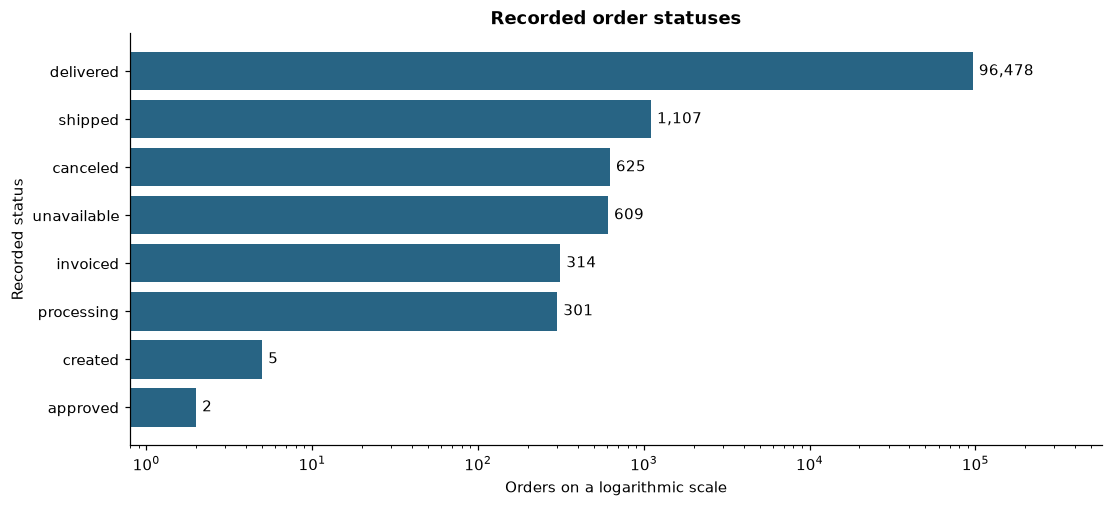

In [20]:
status_counts = order_facts["order_status"].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(10, 4.5), layout="constrained")
bars = ax.barh(status_counts.index, status_counts.values, color="#286484")
ax.set_xscale("log")
ax.set_xlim(0.8, status_counts.max() * 6)
ax.bar_label(bars, labels=[f"{n:,}" for n in status_counts.values], padding=4)
ax.set(title="Recorded order statuses", xlabel="Orders on a logarithmic scale", ylabel="Recorded status")
plt.show()


**Observed finding and implication**

The delivered cohort contains 96,478 of 99,441 source orders. Smaller status groups remain relevant when choosing a later prediction-time cohort.

### 4.2 Activity over time

Count distinct orders by purchase month for all statuses and the delivered cohort. Include zero-count months in the displayed monthly index. Boundary months and sparse tail months require review before choosing reliable prediction and follow-up periods.

Changes in observed volume can reflect market activity, data coverage, or order completion. The chart alone cannot distinguish those causes.


         all_orders  delivered_with_items
2018-06        6167                  6099
2018-07        6292                  6159
2018-08        6512                  6351
2018-09          16                     0
2018-10           4                     0


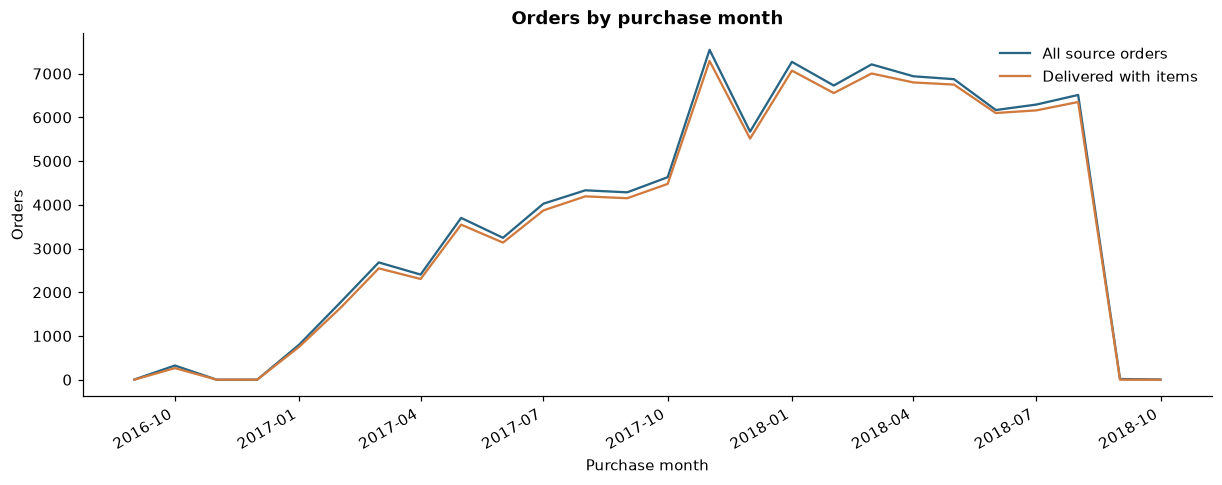

In [21]:
monthly_all = order_facts.groupby(
    order_facts["order_purchase_timestamp"].dt.to_period("M")
).size()
monthly_delivered = analysis_orders.groupby(
    analysis_orders["order_purchase_timestamp"].dt.to_period("M")
).size()
month_index = pd.period_range(monthly_all.index.min(), monthly_all.index.max(), freq="M")
monthly_activity = pd.DataFrame({
    "all_orders": monthly_all.reindex(month_index, fill_value=0),
    "delivered_with_items": monthly_delivered.reindex(month_index, fill_value=0),
})
fig, ax = plt.subplots(figsize=(11, 4.3), layout="constrained")
ax.plot(month_index.to_timestamp(), monthly_activity["all_orders"], label="All source orders", color="#286484")
ax.plot(month_index.to_timestamp(), monthly_activity["delivered_with_items"], label="Delivered with items", color="#d17a3e")
ax.set(title="Orders by purchase month", xlabel="Purchase month", ylabel="Orders")
ax.legend(frameon=False)
fig.autofmt_xdate()
plt.show()
print(monthly_activity.tail(5).to_string())


**Observed finding and implication**

The snapshot contains 6,512 source orders in August 2018, then 16 in September and 4 in October. The latter two months contain no delivered orders in this cohort. Treat the sparse tail as a coverage concern when choosing the modeling interval, rather than interpreting it as an established collapse in demand.

### 4.3 Merchandise value and freight distributions

Summarize the complete cohort with percentiles. Display the full merchandise-value range on a logarithmic horizontal scale, then compare freight against merchandise value using a deterministic sample for readability. The summaries use all eligible orders.

Scatter sampling is for display only. High-value observations remain in the data. A broad right tail may motivate transformations or robust methods during feature engineering.


       items_value  freight_total  item_count
count     96478.00       96478.00    96478.00
mean        137.04          22.79        1.14
std         209.05          21.56        0.54
min           0.85           0.00        1.00
50%          86.57          17.17        1.00
90%         269.00          39.38        1.00
95%         399.00          54.78        2.00
99%         990.00         104.24        3.00
max       13440.00        1794.96       21.00


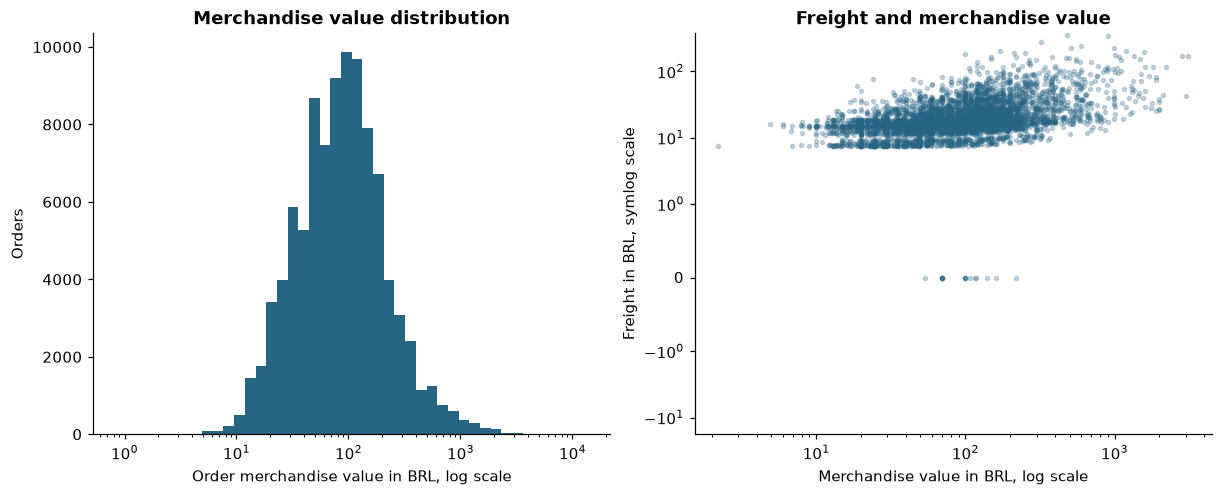

In [22]:
spend_summary = analysis_orders[["items_value", "freight_total", "item_count"]].describe(
    percentiles=[0.5, 0.9, 0.95, 0.99]
).round(2)
print(spend_summary.to_string())
eda_metrics["median_merchandise_value"] = float(analysis_orders["items_value"].median())
eda_metrics["p99_merchandise_value"] = float(analysis_orders["items_value"].quantile(0.99))

sample_orders = analysis_orders.sample(n=min(5000, len(analysis_orders)), random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), layout="constrained")
spend_bins = np.geomspace(analysis_orders["items_value"].min(), analysis_orders["items_value"].max(), 45)
axes[0].hist(analysis_orders["items_value"], bins=spend_bins, color="#286484")
axes[0].set_xscale("log")
axes[0].set(title="Merchandise value distribution", xlabel="Order merchandise value in BRL, log scale", ylabel="Orders")
axes[1].scatter(sample_orders["items_value"], sample_orders["freight_total"], s=7, alpha=0.25, color="#286484")
axes[1].set_xscale("log")
axes[1].set_yscale("symlog", linthresh=1)
axes[1].set(title="Freight and merchandise value", xlabel="Merchandise value in BRL, log scale", ylabel="Freight in BRL, symlog scale")
plt.show()


**Observed finding and implication**

Median merchandise value is BRL 86.57, while the 99th percentile is BRL 990.00. The broad range supports evaluating a log transform or robust preprocessing later. The scatter uses at most 5,000 orders with random seed 42 for readability, while statistics use the full cohort.

### 4.4 Customer activity and observed repeat purchases

Group orders by the stable customer identity. Count distinct delivered orders and sum merchandise value once per order.

The observed repeat-buyer share counts customers with at least two delivered orders anywhere in the observed cohort. Customers have different observation lengths, so this percentage is a descriptive snapshot and requires a follow-up adjustment before interpreting a future repeat-purchase target.

For repeat buyers, calculate the interval between the first and second observed delivered purchases. A zero-day interval can represent distinct orders placed on the same day.


Observed repeat-buyer share: 3.00%
Median first-to-second purchase interval: 28.98 days


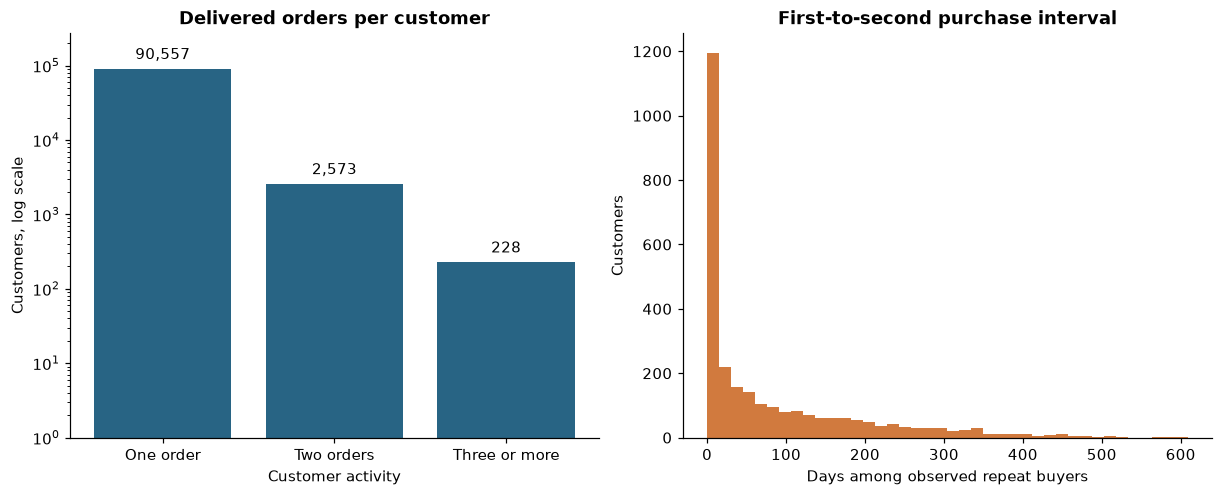

In [23]:
customer_activity = analysis_orders.groupby("customer_unique_id").agg(
    delivered_orders=("order_id", "nunique"),
    merchandise_spend=("items_value", "sum"),
    first_purchase=("order_purchase_timestamp", "min"),
    last_purchase=("order_purchase_timestamp", "max"),
)
repeat_buyers = customer_activity["delivered_orders"].ge(2)
eda_metrics["observed_repeat_buyers"] = int(repeat_buyers.sum())
eda_metrics["observed_repeat_buyer_percent"] = float(100 * repeat_buyers.mean())

ordered_purchases = analysis_orders.sort_values(
    ["customer_unique_id", "order_purchase_timestamp", "order_id"]
).copy()
ordered_purchases["purchase_number"] = ordered_purchases.groupby("customer_unique_id").cumcount()
second_purchase_times = ordered_purchases.loc[
    ordered_purchases["purchase_number"].eq(1)
].set_index("customer_unique_id")["order_purchase_timestamp"]
customer_activity["second_purchase"] = second_purchase_times
repeat_intervals = (
    customer_activity["second_purchase"] - customer_activity["first_purchase"]
).dt.total_seconds().div(86400).dropna()
eda_metrics["median_first_to_second_days"] = float(repeat_intervals.median())

activity_groups = pd.Series({
    "One order": int(customer_activity["delivered_orders"].eq(1).sum()),
    "Two orders": int(customer_activity["delivered_orders"].eq(2).sum()),
    "Three or more": int(customer_activity["delivered_orders"].ge(3).sum()),
})
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), layout="constrained")
bars = axes[0].bar(activity_groups.index, activity_groups.values, color="#286484")
axes[0].set_yscale("log")
axes[0].set_ylim(1, activity_groups.max() * 3)
axes[0].bar_label(bars, labels=[f"{n:,}" for n in activity_groups], padding=4)
axes[0].set(title="Delivered orders per customer", xlabel="Customer activity", ylabel="Customers, log scale")
axes[1].hist(repeat_intervals, bins=40, color="#d17a3e")
axes[1].set(title="First-to-second purchase interval", xlabel="Days among observed repeat buyers", ylabel="Customers")
plt.show()
print(f"Observed repeat-buyer share: {eda_metrics['observed_repeat_buyer_percent']:.2f}%")
print(f"Median first-to-second purchase interval: {repeat_intervals.median():.2f} days")


**Observed finding and implication**

There are 93,358 customers and 2,801 observed repeat buyers, or 3.00 percent. Among observed repeat buyers, the median first-to-second interval is 28.98 days. Different history lengths make the follow-up analysis necessary before using a repeat label.

### 4.5 Product demand, categories, and interaction sparsity

Deduplicate customer-product pairs when measuring implicit interactions. Purchases of multiple units remain in item demand counts, but contribute one observed pair to the binary interaction count.

Measure demand concentration through the cumulative share of observed customer-product pairs. Category popularity uses source item rows from the delivered cohort.

Sparsity is calculated from counts only. Missing customer-product pairs are unobserved interactions. The dataset does not establish dislike or exposure for those pairs.


Interaction sparsity: 99.99668%
Products bought by one observed customer: 59.52%


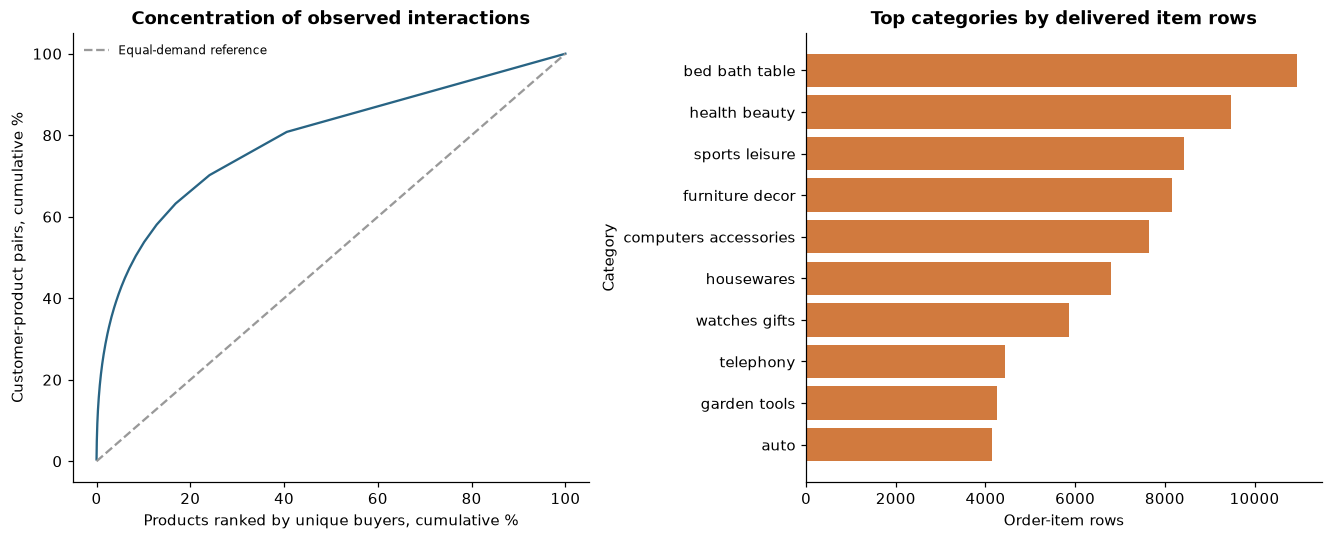

In [24]:
customer_product_pairs = analysis_items[["customer_unique_id", "product_id"]].drop_duplicates()
buyers_per_product = customer_product_pairs.groupby("product_id").size().sort_values(ascending=False)
observed_users = int(customer_product_pairs["customer_unique_id"].nunique())
observed_products = int(customer_product_pairs["product_id"].nunique())
interaction_sparsity = 1 - len(customer_product_pairs) / (observed_users * observed_products)
single_buyer_products = int(buyers_per_product.eq(1).sum())
eda_metrics.update({
    "observed_products": observed_products,
    "unique_customer_product_pairs": int(len(customer_product_pairs)),
    "interaction_sparsity_percent": float(100 * interaction_sparsity),
    "single_buyer_product_percent": float(100 * single_buyer_products / observed_products),
    "top_ten_product_interaction_percent": float(100 * buyers_per_product.head(10).sum() / buyers_per_product.sum()),
})

cumulative_demand = buyers_per_product.cumsum() / buyers_per_product.sum()
product_fraction = np.arange(1, len(buyers_per_product) + 1) / len(buyers_per_product)
top_categories = analysis_items["category_label"].value_counts().head(10).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained")
axes[0].plot(100 * product_fraction, 100 * cumulative_demand.values, color="#286484")
axes[0].plot([0, 100], [0, 100], "--", color="#999999", label="Equal-demand reference")
axes[0].set(title="Concentration of observed interactions", xlabel="Products ranked by unique buyers, cumulative %", ylabel="Customer-product pairs, cumulative %")
axes[0].legend(frameon=False, fontsize=8)
axes[1].barh(top_categories.index.str.replace("_", " "), top_categories.values, color="#d17a3e")
axes[1].set(title="Top categories by delivered item rows", xlabel="Order-item rows", ylabel="Category")
plt.show()
print(f"Interaction sparsity: {100 * interaction_sparsity:.5f}%")
print(f"Products bought by one observed customer: {100 * single_buyer_products / observed_products:.2f}%")


**Observed finding and implication**

The cohort has 99,785 distinct customer-product pairs and 32,216 products. Interaction sparsity is 99.99668 percent, and 59.52 percent of products have just one observed buyer. Compare collaborative methods with popularity and content-based fallbacks, and report the eligible recommendation cohort.

### 4.6 Regional order volume

Count distinct delivered orders by customer state. Print the leading state's share and review the dominance of large groups before making later subgroup comparisons.

Geographic order counts describe this marketplace sample. They do not measure population demand or establish that location causes purchasing behavior.


Leading state: SP
Leading state's order share: 41.98%


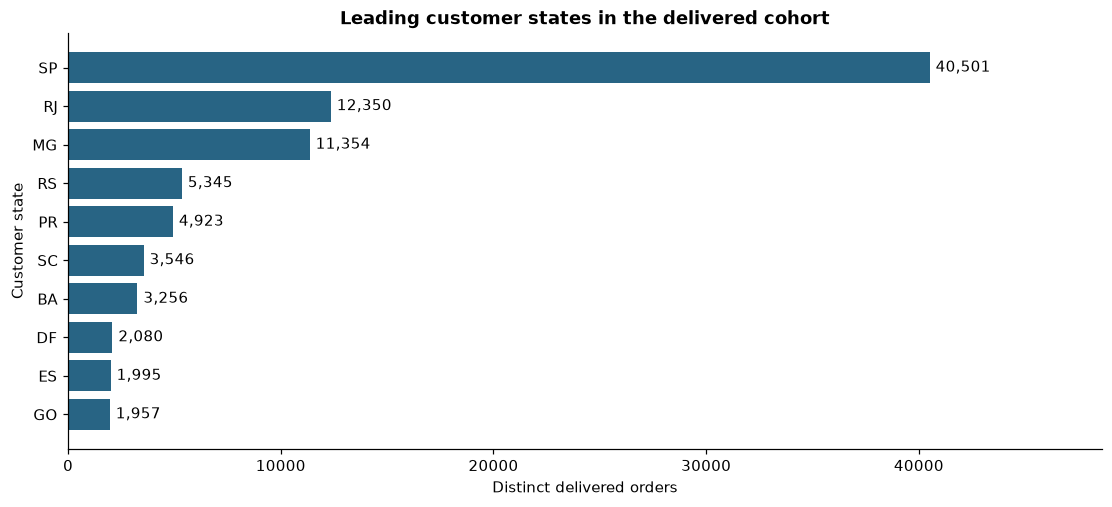

In [25]:
state_orders = analysis_orders.groupby("customer_state")["order_id"].nunique().sort_values(ascending=False)
eda_metrics["leading_state_order_percent"] = float(100 * state_orders.iloc[0] / len(analysis_orders))
top_states = state_orders.head(10).sort_values()
fig, ax = plt.subplots(figsize=(10, 4.5), layout="constrained")
bars = ax.barh(top_states.index, top_states.values, color="#286484")
ax.bar_label(bars, labels=[f"{n:,}" for n in top_states], padding=4)
ax.set_xlim(0, top_states.max() * 1.2)
ax.set(title="Leading customer states in the delivered cohort", xlabel="Distinct delivered orders", ylabel="Customer state")
plt.show()
print(f"Leading state: {state_orders.index[0]}")
print(f"Leading state's order share: {eda_metrics['leading_state_order_percent']:.2f}%")


**Observed finding and implication**

SP accounts for 41.98 percent of delivered orders in the cohort. Compare later error rates together with subgroup sample sizes so a dominant region does not hide weak performance elsewhere.

### 4.7 Review scores and delivery experience

Use each order's earliest eligible review prepared in the cleaning section. Compare the share of scores 1 to 3 between orders delivered after their estimated calendar date and orders delivered by that date.

Delivery duration uses purchase-to-customer-delivery time. Compare normalized calendar dates for lateness so that delivery on the estimated day is counted as on time. Missing dates or unavailable reviews are excluded only from the applicable comparison, with cohort sizes reported.

Review scores reflect the overall recorded order experience. This comparison describes association and does not prove that delivery timing causes a score.


                      reviewed_orders  score_1_to_3_share
delivery_group                                           
After estimated date             6381            0.732017
By estimated date               89440            0.173189
Delivered orders without an eligible review: 649


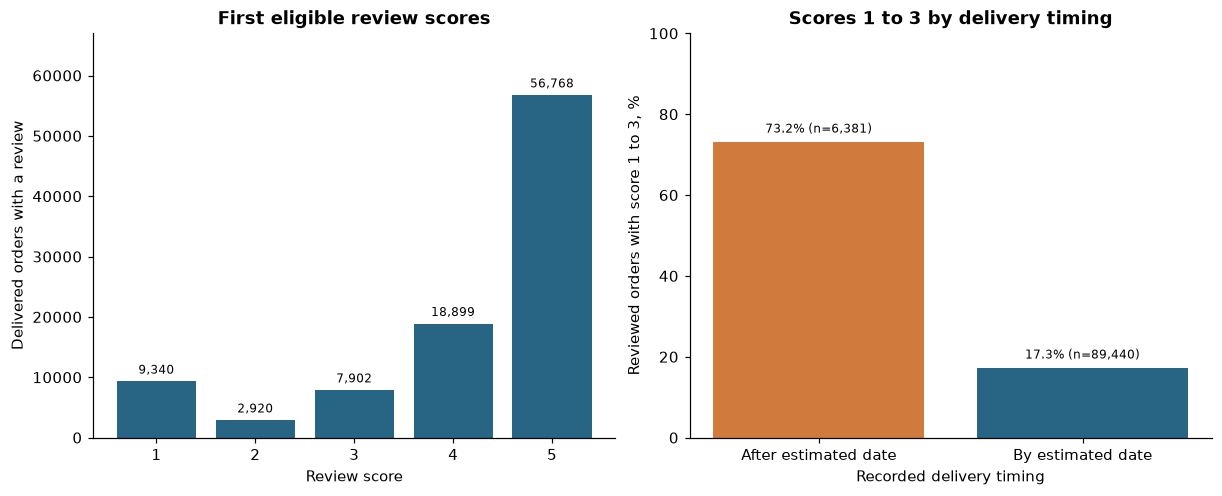

In [26]:
analysis_orders["delivery_days"] = (
    analysis_orders["order_delivered_customer_date"] - analysis_orders["order_purchase_timestamp"]
).dt.total_seconds().div(86400)

reviewed_orders = analysis_orders.loc[analysis_orders["has_eligible_review"]].copy()
score_counts = reviewed_orders["first_review_score"].value_counts().reindex(range(1, 6), fill_value=0)
delivery_comparison = reviewed_orders.loc[
    reviewed_orders["order_delivered_customer_date"].notna()
    & reviewed_orders["order_estimated_delivery_date"].notna()
    & reviewed_orders["delivery_days"].ge(0)
].copy()
delivery_comparison["delivery_group"] = np.where(
    delivery_comparison["order_delivered_customer_date"].dt.normalize()
    > delivery_comparison["order_estimated_delivery_date"].dt.normalize(),
    "After estimated date", "By estimated date",
)
delivery_comparison["score_1_to_3"] = delivery_comparison["first_review_score"].le(3)
delivery_review_summary = delivery_comparison.groupby("delivery_group").agg(
    reviewed_orders=("order_id", "size"),
    score_1_to_3_share=("score_1_to_3", "mean"),
)
eda_metrics["reviewed_delivered_orders"] = int(len(reviewed_orders))
eda_metrics["delivery_review_comparison_orders"] = int(len(delivery_comparison))
eda_metrics["median_delivery_days"] = float(analysis_orders["delivery_days"].median())
eda_metrics["late_score_1_to_3_percent"] = float(
    100 * delivery_review_summary.loc["After estimated date", "score_1_to_3_share"]
)
eda_metrics["on_time_score_1_to_3_percent"] = float(
    100 * delivery_review_summary.loc["By estimated date", "score_1_to_3_share"]
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), layout="constrained")
bars = axes[0].bar(score_counts.index.astype(str), score_counts.values, color="#286484")
axes[0].bar_label(bars, labels=[f"{n:,}" for n in score_counts], padding=3, fontsize=8)
axes[0].set_ylim(0, score_counts.max() * 1.18)
axes[0].set(title="First eligible review scores", xlabel="Review score", ylabel="Delivered orders with a review")
rates = 100 * delivery_review_summary["score_1_to_3_share"]
bars = axes[1].bar(rates.index, rates.values, color=["#d17a3e", "#286484"])
axes[1].bar_label(bars, labels=[f"{v:.1f}% (n={n:,})" for v, n in zip(rates, delivery_review_summary["reviewed_orders"])], padding=4, fontsize=8)
axes[1].set_ylim(0, 100)
axes[1].set(title="Scores 1 to 3 by delivery timing", xlabel="Recorded delivery timing", ylabel="Reviewed orders with score 1 to 3, %")
plt.show()
print(delivery_review_summary.to_string())
print(f"Delivered orders without an eligible review: {int((~analysis_orders['has_eligible_review']).sum())}")


**Observed finding and implication**

The comparison includes 95,821 reviewed orders with usable delivery timing. Scores 1 to 3 occur in 73.20 percent of late cases and 17.32 percent of on-time cases. This is a strong descriptive association. Confounding, review selection, and review timing prevent a causal conclusion. Review scores describe the order experience and require care before use as product-preference labels.

### 4.8 Numeric associations

Calculate Pearson correlations at one row per delivered order. Pairwise available values are used, so sample sizes differ where a review or delivery date is missing. Print non-missing counts alongside the heatmap.

Correlation is descriptive and can be sensitive to outliers. Review and realized delivery fields may be unavailable at an earlier prediction date, so their presence in this plot does not make them eligible model inputs.


Non-missing observations per field:
items_value           96478
freight_total         96478
item_count            96478
delivery_days         96470
first_review_score    95829


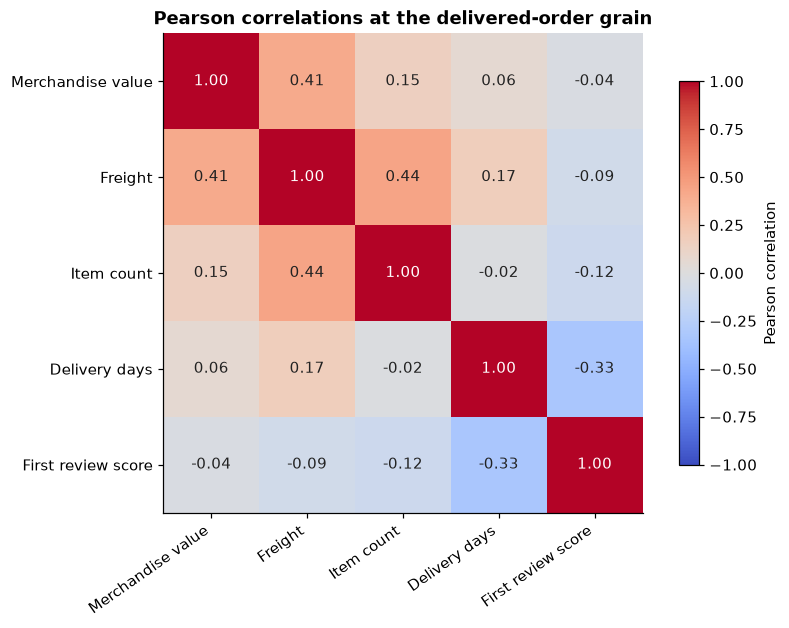

In [27]:
correlation_columns = ["items_value", "freight_total", "item_count", "delivery_days", "first_review_score"]
numeric_correlations = analysis_orders[correlation_columns].corr(method="pearson")
labels = ["Merchandise value", "Freight", "Item count", "Delivery days", "First review score"]
fig, ax = plt.subplots(figsize=(8, 5.6), layout="constrained")
image = ax.imshow(numeric_correlations, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(labels)), labels=labels, rotation=35, ha="right")
ax.set_yticks(range(len(labels)), labels=labels)
for row in range(len(labels)):
    for column in range(len(labels)):
        value = numeric_correlations.iloc[row, column]
        ax.text(column, row, f"{value:.2f}", ha="center", va="center",
                color="white" if abs(value) > 0.65 else "#222222")
ax.set_title("Pearson correlations at the delivered-order grain")
fig.colorbar(image, ax=ax, label="Pearson correlation", shrink=0.8)
plt.show()
print("Non-missing observations per field:")
print(analysis_orders[correlation_columns].notna().sum().to_string())


**Observed finding and implication**

Delivery duration and the first review score have a negative Pearson correlation of approximately -0.33 in this cohort. Merchandise value and freight correlate at approximately 0.41. Evaluate skew, temporal availability, and missingness before turning an association into a feature choice.

### 4.9 Candidate repeat-purchase windows

Examine 30, 60, and 90-day follow-up windows from each customer's first observed delivered purchase. Include a customer in a window's denominator only when its end falls on or before the final observed delivered purchase timestamp.

A repeat means a second distinct delivered order within that window, including a same-day second order. Customers whose second order falls later count as non-repeaters within the stated window.

The last observed delivered purchase is a provisional coverage boundary. Verify data completeness around that boundary when defining the model target. Eligibility cohorts differ between windows, so the percentages reflect both the horizon and cohort composition. These summaries are feasibility evidence and do not establish the final target or its performance.


 window_days  eligible_customers  repeat_customers  repeat_percent
          30               86772              1373        1.582308
          60               81203              1584        1.950667
          90               75320              1714        2.275624
Provisional delivered-purchase coverage end: 2018-08-29 15:00:37


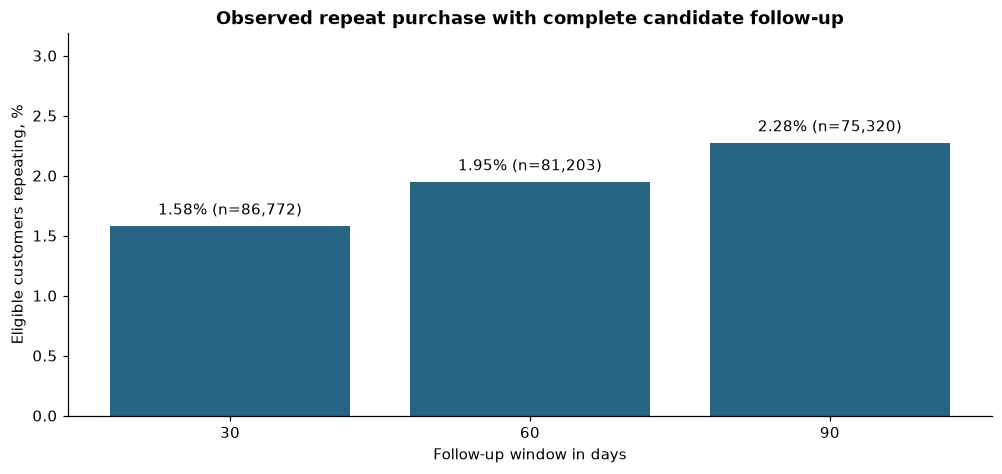

In [28]:
observed_delivery_purchase_end = analysis_orders["order_purchase_timestamp"].max()
followup_rows = []

for days in [30, 60, 90]:
    full_followup = (
        customer_activity["first_purchase"] + pd.Timedelta(days=days)
        <= observed_delivery_purchase_end
    )
    eligible = customer_activity.loc[full_followup]
    repeat_within_window = (
        eligible["second_purchase"].notna()
        & (eligible["second_purchase"] <= eligible["first_purchase"] + pd.Timedelta(days=days))
    )
    followup_rows.append({
        "window_days": days,
        "eligible_customers": int(len(eligible)),
        "repeat_customers": int(repeat_within_window.sum()),
        "repeat_percent": float(100 * repeat_within_window.mean()),
    })

followup_summary = pd.DataFrame(followup_rows)
row_90 = followup_summary.loc[followup_summary["window_days"].eq(90)].iloc[0]
eda_metrics["followup_90_eligible_customers"] = int(row_90["eligible_customers"])
eda_metrics["followup_90_repeat_customers"] = int(row_90["repeat_customers"])
eda_metrics["followup_90_repeat_percent"] = float(row_90["repeat_percent"])

fig, ax = plt.subplots(figsize=(9, 4.2), layout="constrained")
bars = ax.bar(followup_summary["window_days"].astype(str), followup_summary["repeat_percent"], color="#286484")
ax.bar_label(bars, labels=[
    f"{rate:.2f}% (n={count:,})"
    for rate, count in zip(followup_summary["repeat_percent"], followup_summary["eligible_customers"])
], padding=5)
ax.set_ylim(0, followup_summary["repeat_percent"].max() * 1.4)
ax.set(title="Observed repeat purchase with complete candidate follow-up", xlabel="Follow-up window in days", ylabel="Eligible customers repeating, %")
plt.show()
print(followup_summary.to_string(index=False))
print(f"Provisional delivered-purchase coverage end: {observed_delivery_purchase_end}")


**Observed finding and implication**

The provisional 90-day cohort contains 75,320 customers with 1,714 observed repeaters, or 2.28 percent. A constant non-repeat classification would have arithmetic accuracy of 97.72 percent in this cohort, showing why accuracy alone is insufficient. The final target still needs a verified coverage boundary and a prediction-date definition.

### EDA evidence summary

The following table collects measured values used to write the interpretation and reference notes. Percentages use the explicit cohorts defined in the analysis sections.


In [29]:
print(pd.Series(eda_metrics, name="value").to_string())

source_orders                           99441.000000
delivered_orders_with_items             96478.000000
analysis_item_rows                     110197.000000
analysis_customers                      93358.000000
median_merchandise_value                   86.575000
p99_merchandise_value                     990.000000
observed_repeat_buyers                   2801.000000
observed_repeat_buyer_percent               3.000278
median_first_to_second_days                28.980197
observed_products                       32216.000000
unique_customer_product_pairs           99785.000000
interaction_sparsity_percent               99.996682
single_buyer_product_percent               59.520114
top_ten_product_interaction_percent         3.242972
leading_state_order_percent                41.979519
reviewed_delivered_orders               95829.000000
delivery_review_comparison_orders       95821.000000
median_delivery_days                       10.217477
late_score_1_to_3_percent                  73.

### EDA conclusions and decisions for the next topic

- Most customers have one observed delivered purchase, and customer-product interactions are extremely sparse. Establish popularity baselines and explicit cold-start behavior before judging collaborative filtering.
- Repeat purchase is a minority outcome in the candidate follow-up cohorts. Use class-sensitive metrics, temporal validation, and explicit eligibility counts.
- The final sparse months require a defensible data-coverage boundary. Target construction must distinguish incomplete follow-up from a fully observed non-repeat outcome.
- Spending spans a broad range. Assess transformations and fit statistical preprocessing only on training data.
- Delivery experience and review scores are associated. Use reviews as carefully timed order-experience signals rather than assuming each order review directly rates every product.
- Geographic volume is concentrated. Any later subgroup analysis must report cohort sizes alongside error rates.
- The next topic will define historical customer snapshots, features, repeat-purchase labels, recommendation interactions, and chronological evaluation splits.

**Topic commit message** — `feat: complete Olist exploratory analysis and document findings`.

The notebook, reference notes, README, environment requirements, and ignore rules form this contribution. The local environment is ignored. Current raw CSV tracking is documented in the README.

## 5 Historical features targets and chronological partitions

Define two tasks with separate evaluation cohorts.

For retention, score an existing customer 30 days after their first observed item-bearing placed order. Predict at least one further item-bearing order in the next 90 days. This defines a fixed-age retention decision. Scores from a model trained on this design apply to that decision point.

For recommendations, learn from purchases placed before a global cutoff and evaluate discovery of previously unseen products in a future 30-day window. Report cold-customer, unseen-catalog, and repeated-product coverage separately.

An item-bearing placed order is an order with recorded line items. The label describes another placed order, including a later-canceled order if it has items. It does not depend on eventual delivery status. This differs from EDA's retrospective delivered-order cohort.

The late sparse months identified by EDA motivate a working observation boundary of 1 September 2018, exclusive. This boundary is an explicit modeling assumption. A static snapshot cannot prove historical completeness or recover all later edits. Sensitivity to target and coverage choices should be discussed with final results.


In [30]:
COVERAGE_END = pd.Timestamp("2018-09-01")
SNAPSHOT_START = pd.Timestamp("2017-01-01")
CUSTOMER_AGE_DAYS = 30
REPEAT_HORIZON_DAYS = 90
RETENTION_VALIDATION_START = pd.Timestamp("2017-11-01")
RETENTION_TEST_START = pd.Timestamp("2018-04-01")

REC_VALIDATION_CUTOFF = pd.Timestamp("2018-04-01")
REC_TEST_CUTOFF = pd.Timestamp("2018-06-01")
REC_HORIZON_DAYS = 30

placed_order_events = order_facts.loc[
    order_facts["has_item_records"]
    & order_facts["order_purchase_timestamp"].lt(COVERAGE_END)
].copy()

assert placed_order_events["order_id"].is_unique
assert placed_order_events["customer_unique_id"].notna().all()

print(f"Item-bearing placed orders before the coverage boundary: {len(placed_order_events):,}")
print(f"Working coverage end, exclusive: {COVERAGE_END}")


Item-bearing placed orders before the coverage boundary: 98,665
Working coverage end, exclusive: 2018-09-01 00:00:00


### 5.1 Customer snapshots and future outcomes

Assign one snapshot per customer at first observed placed purchase plus 30 days. Keep snapshots from the stated start date only when their entire 90-day outcome window ends before the working observation boundary.

A positive label requires another order strictly after the snapshot and on or before its outcome end. Orders at or before the snapshot belong to history. Customers with insufficient follow-up are excluded before splitting. This target concerns future customer orders, independently of whether they reorder the same product.


In [31]:
first_observed_purchase = placed_order_events.groupby(
    "customer_unique_id"
)["order_purchase_timestamp"].min()

customer_snapshots = first_observed_purchase.rename("first_observed_purchase_at").to_frame()
customer_snapshots["snapshot_at"] = (
    customer_snapshots["first_observed_purchase_at"]
    + pd.Timedelta(days=CUSTOMER_AGE_DAYS)
)
customer_snapshots["outcome_end"] = (
    customer_snapshots["snapshot_at"] + pd.Timedelta(days=REPEAT_HORIZON_DAYS)
)

complete_snapshot_mask = (
    customer_snapshots["snapshot_at"].ge(SNAPSHOT_START)
    & customer_snapshots["outcome_end"].lt(COVERAGE_END)
)
eligible_snapshots = customer_snapshots.loc[complete_snapshot_mask].reset_index()

snapshot_order_events = placed_order_events.merge(
    eligible_snapshots,
    on="customer_unique_id",
    how="inner",
    validate="many_to_one",
)

history_order_events = snapshot_order_events.loc[
    snapshot_order_events["order_purchase_timestamp"].le(snapshot_order_events["snapshot_at"])
].copy()
future_order_events = snapshot_order_events.loc[
    snapshot_order_events["order_purchase_timestamp"].gt(snapshot_order_events["snapshot_at"])
    & snapshot_order_events["order_purchase_timestamp"].le(snapshot_order_events["outcome_end"])
].copy()

future_counts = future_order_events.groupby("customer_unique_id")["order_id"].nunique()
eligible_snapshots["future_order_count"] = (
    eligible_snapshots["customer_unique_id"].map(future_counts).fillna(0).astype(int)
)
eligible_snapshots["repeat_90d"] = eligible_snapshots["future_order_count"].gt(0).astype(int)

snapshot_summary = pd.DataFrame([
    {"measure": "Customers with an observed item-bearing order", "count": len(customer_snapshots)},
    {"measure": "Snapshots meeting start and complete-follow-up rules", "count": len(eligible_snapshots)},
    {"measure": "Eligible snapshots with a future repeat order", "count": int(eligible_snapshots["repeat_90d"].sum())},
])
print(snapshot_summary.to_string(index=False))


                                             measure  count
       Customers with an observed item-bearing order  95420
Snapshots meeting start and complete-follow-up rules  71105
       Eligible snapshots with a future repeat order    665


### 5.2 Purchase history features

Aggregate only orders at or before each snapshot. Use order-level facts for spending so item and payment multiplicity cannot inflate monetary features. Use historical item rows for product and seller breadth.

Recency measures days since the latest historical placed order. Frequency is distinct historical orders. Monetary value is historical merchandise spend excluding freight. Age is fixed by design, so a constant customer-age feature is omitted.

State comes from the earliest historical order. Product and seller identifiers are used for grouping and counting, and are excluded from the predictor lists.


In [32]:
history_order_events = history_order_events.sort_values(
    ["customer_unique_id", "order_purchase_timestamp", "order_id"]
)

purchase_features = history_order_events.groupby("customer_unique_id").agg(
    historical_order_count=("order_id", "nunique"),
    merchandise_spend=("items_value", "sum"),
    average_order_value=("items_value", "mean"),
    historical_freight=("freight_total", "sum"),
    latest_historical_purchase_at=("order_purchase_timestamp", "max"),
    customer_state=("customer_state", "first"),
).reset_index()

history_item_events = purchase_events.merge(
    history_order_events[["order_id", "customer_unique_id", "snapshot_at"]],
    on=["order_id", "customer_unique_id"],
    how="inner",
    validate="many_to_one",
)
breadth_features = history_item_events.groupby("customer_unique_id").agg(
    distinct_products=("product_id", "nunique"),
    distinct_sellers=("seller_id", "nunique"),
).reset_index()

retention_dataset = eligible_snapshots.merge(
    purchase_features, on="customer_unique_id", how="left", validate="one_to_one"
).merge(
    breadth_features, on="customer_unique_id", how="left", validate="one_to_one"
)
retention_dataset["recency_days"] = (
    retention_dataset["snapshot_at"] - retention_dataset["latest_historical_purchase_at"]
).dt.total_seconds().div(86400)
retention_dataset["freight_ratio"] = (
    retention_dataset["historical_freight"] / retention_dataset["merchandise_spend"]
)
print(retention_dataset[
    ["historical_order_count", "distinct_products", "merchandise_spend", "recency_days"]
].describe().round(3).to_string())


       historical_order_count  distinct_products  merchandise_spend  recency_days
count               71105.000          71105.000          71105.000     71105.000
mean                    1.018              1.054            139.437        29.915
std                     0.142              0.269            210.572         1.243
min                     1.000              1.000              0.850         0.015
25%                     1.000              1.000             46.990        30.000
50%                     1.000              1.000             89.000        30.000
75%                     1.000              1.000            150.000        30.000
max                     6.000              7.000          13440.000        30.000


### 5.3 Reviews and deliveries available by the snapshot

Use the first eligible review only if its recorded answer is at or before the snapshot. Include a completed delivery duration only when customer delivery is recorded by that date and at or after purchase.

Aggregate known event counts and their means. Leave unavailable mean scores and durations missing. Their imputers will be fitted on training data in the baseline topic. Availability maxima remain audit columns, outside the model inputs.

Checkout amounts, recorded product identities, and review-answer timestamps serve as availability proxies in this static dataset. The snapshot cannot reconstruct later corrections to source records.


In [33]:
known_reviews = (
    history_order_events["first_review_available_at"].notna()
    & history_order_events["first_review_available_at"].le(history_order_events["snapshot_at"])
)
known_deliveries = (
    history_order_events["order_delivered_customer_date"].notna()
    & history_order_events["order_delivered_customer_date"].le(history_order_events["snapshot_at"])
    & history_order_events["order_delivered_customer_date"].ge(
        history_order_events["order_purchase_timestamp"]
    )
)

history_order_events["known_review_score"] = (
    history_order_events["first_review_score"].where(known_reviews)
)
history_order_events["known_review_available_at"] = (
    history_order_events["first_review_available_at"].where(known_reviews)
)
history_order_events["known_delivery_at"] = (
    history_order_events["order_delivered_customer_date"].where(known_deliveries)
)
history_order_events["known_delivery_days"] = (
    history_order_events["known_delivery_at"]
    - history_order_events["order_purchase_timestamp"]
).dt.total_seconds().div(86400)

known_event_features = history_order_events.groupby("customer_unique_id").agg(
    known_review_count=("known_review_score", "count"),
    mean_known_review_score=("known_review_score", "mean"),
    latest_known_review_at=("known_review_available_at", "max"),
    known_delivery_count=("known_delivery_at", "count"),
    mean_known_delivery_days=("known_delivery_days", "mean"),
    latest_known_delivery_at=("known_delivery_at", "max"),
).reset_index()

retention_dataset = retention_dataset.merge(
    known_event_features, on="customer_unique_id", how="left", validate="one_to_one"
)

retention_dataset["log1p_merchandise_spend"] = np.log1p(retention_dataset["merchandise_spend"])
retention_dataset["log1p_average_order_value"] = np.log1p(retention_dataset["average_order_value"])

RETENTION_NUMERIC_FEATURES = [
    "recency_days", "historical_order_count", "distinct_products", "distinct_sellers",
    "log1p_merchandise_spend", "log1p_average_order_value", "freight_ratio",
    "known_review_count", "mean_known_review_score",
    "known_delivery_count", "mean_known_delivery_days",
]
RETENTION_CATEGORICAL_FEATURES = ["customer_state"]
RETENTION_FEATURES = RETENTION_NUMERIC_FEATURES + RETENTION_CATEGORICAL_FEATURES

print("Predictor fields:")
print(pd.Series(RETENTION_FEATURES).to_string(index=False))
print()
print("Missing predictor values before training-fitted preprocessing:")
print(retention_dataset[RETENTION_FEATURES].isna().sum().to_string())


Predictor fields:
             recency_days
   historical_order_count
        distinct_products
         distinct_sellers
  log1p_merchandise_spend
log1p_average_order_value
            freight_ratio
       known_review_count
  mean_known_review_score
     known_delivery_count
 mean_known_delivery_days
           customer_state

Missing predictor values before training-fitted preprocessing:
recency_days                    0
historical_order_count          0
distinct_products               0
distinct_sellers                0
log1p_merchandise_spend         0
log1p_average_order_value       0
freight_ratio                   0
known_review_count              0
mean_known_review_score      5985
known_delivery_count            0
mean_known_delivery_days     5722
customer_state                  0


### 5.4 Chronological retention partitions with label maturation

Training outcomes must end before the first validation prediction date. Validation outcomes must end before the first test prediction date. The resulting gaps are deliberately excluded from this primary comparison.

Each customer contributes one snapshot and therefore belongs to at most one partition. No random train-test split or stratified time reshuffling is used. Report the remaining positive counts explicitly because the rare class limits model selection and uncertainty.


In [34]:
retention_partitions = {
    "train": retention_dataset.loc[
        retention_dataset["outcome_end"].lt(RETENTION_VALIDATION_START)
    ].copy(),
    "validation": retention_dataset.loc[
        retention_dataset["snapshot_at"].ge(RETENTION_VALIDATION_START)
        & retention_dataset["outcome_end"].lt(RETENTION_TEST_START)
    ].copy(),
    "test": retention_dataset.loc[
        retention_dataset["snapshot_at"].ge(RETENTION_TEST_START)
    ].copy(),
}

retention_split_rows = []
for partition_name, frame in retention_partitions.items():
    retention_split_rows.append({
        "partition": partition_name,
        "customers": len(frame),
        "repeat_customers": int(frame["repeat_90d"].sum()),
        "repeat_percent": round(100 * frame["repeat_90d"].mean(), 3),
        "first_snapshot": frame["snapshot_at"].min(),
        "last_snapshot": frame["snapshot_at"].max(),
        "latest_outcome_end": frame["outcome_end"].max(),
    })
retention_split_summary = pd.DataFrame(retention_split_rows)
purged_snapshot_count = len(retention_dataset) - sum(len(frame) for frame in retention_partitions.values())

X_train = retention_partitions["train"][RETENTION_FEATURES].copy()
y_train = retention_partitions["train"]["repeat_90d"].copy()
X_validation = retention_partitions["validation"][RETENTION_FEATURES].copy()
y_validation = retention_partitions["validation"]["repeat_90d"].copy()
X_test = retention_partitions["test"][RETENTION_FEATURES].copy()
y_test = retention_partitions["test"]["repeat_90d"].copy()

print(retention_split_summary.to_string(index=False))
print(f"Snapshots excluded in maturation gaps: {purged_snapshot_count:,}")


 partition  customers  repeat_customers  repeat_percent      first_snapshot       last_snapshot  latest_outcome_end
     train      14362               140           0.975 2017-01-22 23:16:47 2017-08-02 23:50:35 2017-10-31 23:50:35
validation      11768                97           0.824 2017-11-01 00:28:03 2017-12-31 23:54:03 2018-03-31 23:54:03
      test      14213               120           0.844 2018-04-01 00:07:09 2018-06-02 23:59:21 2018-08-31 23:59:21
Snapshots excluded in maturation gaps: 30,762


### 5.5 Recommendation interactions and future discovery relevance

Recommendation and retention evaluation have different row units and eligibility rules. Build recommendation history before each global cutoff and a future 30-day window with the same placed-order event policy.

Candidates are products already observed in history. Warm customers have at least one historical purchase. Relevant discovery items are future customer-product pairs that are in the historical candidate catalog and have not already been purchased by that customer.

Preserve the full future window for coverage reporting. Future new users and new catalog products remain explicit cold-start cases. Repeated-product purchases are outside this discovery protocol. No default minimum of five user interactions is imposed, and unobserved pairs are not labeled as dislikes.

After validation selects settings, final recommendation fitting may use all events before the test cutoff, including earlier validation-period events. Only test-future events remain held out. All compared methods must share the candidate and eligibility definitions.


In [35]:
placed_item_events = purchase_events.loc[
    purchase_events["order_purchase_timestamp"].lt(COVERAGE_END),
    ["customer_unique_id", "product_id", "order_id", "order_purchase_timestamp"],
].rename(columns={
    "customer_unique_id": "user",
    "product_id": "item",
    "order_purchase_timestamp": "time",
})

def build_recommendation_window(cutoff, horizon_days):
    window_end = cutoff + pd.Timedelta(days=horizon_days)
    if window_end >= COVERAGE_END:
        raise ValueError("Recommendation window must end before the working coverage boundary.")

    history = placed_item_events.loc[placed_item_events["time"].lt(cutoff)].copy()
    future = placed_item_events.loc[
        placed_item_events["time"].ge(cutoff)
        & placed_item_events["time"].lt(window_end)
    ].copy()
    history_pairs = history[["user", "item"]].drop_duplicates()
    future_pairs = future[["user", "item"]].drop_duplicates()

    annotated_pairs = future_pairs.merge(
        history_pairs.assign(seen_in_history=True),
        on=["user", "item"], how="left", validate="one_to_one",
    )
    annotated_pairs["warm_user"] = annotated_pairs["user"].isin(history_pairs["user"])
    annotated_pairs["known_item"] = annotated_pairs["item"].isin(history_pairs["item"])
    annotated_pairs["already_purchased"] = annotated_pairs["seen_in_history"].eq(True)
    relevance = annotated_pairs.loc[
        annotated_pairs["warm_user"]
        & annotated_pairs["known_item"]
        & ~annotated_pairs["already_purchased"],
        ["user", "item"],
    ].copy()

    return {
        "cutoff": cutoff, "window_end": window_end,
        "history_events": history, "history_pairs": history_pairs,
        "future_events": future, "future_pairs": annotated_pairs,
        "candidate_items": pd.Index(sorted(history_pairs["item"].unique())),
        "relevance": relevance,
    }

recommendation_partitions = {
    "validation": build_recommendation_window(REC_VALIDATION_CUTOFF, REC_HORIZON_DAYS),
    "test": build_recommendation_window(REC_TEST_CUTOFF, REC_HORIZON_DAYS),
}

recommendation_split_rows = []
for partition_name, split in recommendation_partitions.items():
    pairs = split["future_pairs"]
    recommendation_split_rows.append({
        "partition": partition_name,
        "history_pairs": len(split["history_pairs"]),
        "candidate_products": len(split["candidate_items"]),
        "future_customers": int(pairs["user"].nunique()),
        "future_unique_pairs": len(pairs),
        "cold_customer_pairs": int((~pairs["warm_user"]).sum()),
        "unseen_catalog_pairs": int((~pairs["known_item"]).sum()),
        "already_purchased_pairs": int(pairs["already_purchased"].sum()),
        "eligible_relevance_pairs": len(split["relevance"]),
        "eligible_ranking_customers": int(split["relevance"]["user"].nunique()),
    })
recommendation_split_summary = pd.DataFrame(recommendation_split_rows)
print(recommendation_split_summary.to_string(index=False))
print("Coverage categories can overlap. Eligibility applies all three conditions together.")


 partition  history_pairs  candidate_products  future_customers  future_unique_pairs  cold_customer_pairs  unseen_catalog_pairs  already_purchased_pairs  eligible_relevance_pairs  eligible_ranking_customers
validation          68203               22964              6878                 7210                 7023                  2497                       26                        97                          90
      test          82461               26895              6121                 6394                 6187                  2243                       29                       102                          97
Coverage categories can overlap. Eligibility applies all three conditions together.


### 5.6 Validate feature availability targets and partition boundaries

Check each customer's latest contributing purchase, review answer, and delivery against its snapshot. Verify the future label interval, complete follow-up, disjoint customer sets, and label maturation across retention partitions.

Independently check label counts for a deterministic sample of customers directly against the source order events. Validate ranking relevance against history and candidates. Model matrices must contain only the explicit predictor list, excluding identifiers, target counts, and audit timestamps.

Imputers, encoders, scaling, class weights, sampling, and model fitting are deferred to the baseline topic and will use training data only.


In [36]:
assert retention_dataset["customer_unique_id"].is_unique
assert len(retention_dataset) == len(eligible_snapshots)
assert retention_dataset["outcome_end"].lt(COVERAGE_END).all()
assert retention_dataset["latest_historical_purchase_at"].le(retention_dataset["snapshot_at"]).all()

for audit_column in ["latest_known_review_at", "latest_known_delivery_at"]:
    observed = retention_dataset[audit_column].notna()
    assert retention_dataset.loc[observed, audit_column].le(
        retention_dataset.loc[observed, "snapshot_at"]
    ).all()

assert future_order_events["order_purchase_timestamp"].gt(future_order_events["snapshot_at"]).all()
assert future_order_events["order_purchase_timestamp"].le(future_order_events["outcome_end"]).all()
assert retention_dataset["historical_order_count"].ge(1).all()
assert retention_dataset["recency_days"].ge(0).all()

for partition_name, frame in retention_partitions.items():
    assert not frame.empty, partition_name
    assert set(frame["repeat_90d"].unique()) == {0, 1}, partition_name

train_ids = set(retention_partitions["train"]["customer_unique_id"])
validation_ids = set(retention_partitions["validation"]["customer_unique_id"])
test_ids = set(retention_partitions["test"]["customer_unique_id"])
assert train_ids.isdisjoint(validation_ids)
assert train_ids.isdisjoint(test_ids)
assert validation_ids.isdisjoint(test_ids)
assert retention_partitions["train"]["outcome_end"].max() < retention_partitions["validation"]["snapshot_at"].min()
assert retention_partitions["validation"]["outcome_end"].max() < retention_partitions["test"]["snapshot_at"].min()

for frame in [X_train, X_validation, X_test]:
    assert list(frame.columns) == RETENTION_FEATURES
    assert not frame.columns.isin([
        "customer_unique_id", "order_id", "repeat_90d", "future_order_count",
        "snapshot_at", "outcome_end", "order_status",
    ]).any()
    assert not np.isinf(frame[RETENTION_NUMERIC_FEATURES].to_numpy(dtype=float)).any()

positive_labels = retention_dataset.loc[retention_dataset["repeat_90d"].eq(1)]
negative_labels = retention_dataset.loc[retention_dataset["repeat_90d"].eq(0)]
label_sample = pd.concat([
    positive_labels.sample(n=min(50, len(positive_labels)), random_state=42),
    negative_labels.sample(n=min(50, len(negative_labels)), random_state=42),
])
source_customer_events = placed_order_events.groupby("customer_unique_id")["order_purchase_timestamp"].apply(list)
for row in label_sample.itertuples(index=False):
    future_times = [
        time for time in source_customer_events[row.customer_unique_id]
        if row.snapshot_at < time <= row.outcome_end
    ]
    assert len(future_times) == row.future_order_count
    assert int(bool(future_times)) == row.repeat_90d

for partition_name, split in recommendation_partitions.items():
    assert split["history_events"]["time"].lt(split["cutoff"]).all()
    assert split["future_events"]["time"].ge(split["cutoff"]).all()
    assert split["future_events"]["time"].lt(split["window_end"]).all()
    assert split["candidate_items"].is_unique
    assert not split["relevance"].duplicated(["user", "item"]).any()
    assert split["relevance"]["user"].isin(split["history_pairs"]["user"]).all()
    assert split["relevance"]["item"].isin(split["candidate_items"]).all()
    seen_relevance = split["relevance"].merge(
        split["history_pairs"], on=["user", "item"], how="inner", validate="one_to_one"
    )
    assert seen_relevance.empty
    assert split["relevance"]["user"].nunique() > 0, partition_name

feature_topic_metrics = {
    "snapshot_age_days": CUSTOMER_AGE_DAYS,
    "repeat_horizon_days": REPEAT_HORIZON_DAYS,
    "eligible_retention_snapshots": int(len(retention_dataset)),
    "purged_snapshot_count": int(purged_snapshot_count),
    "numeric_predictors": len(RETENTION_NUMERIC_FEATURES),
    "categorical_predictors": len(RETENTION_CATEGORICAL_FEATURES),
    "independently_checked_labels": int(len(label_sample)),
}
print(pd.Series(feature_topic_metrics).to_string())
print("Feature availability, label, and partition validations passed.")


snapshot_age_days                  30
repeat_horizon_days                90
eligible_retention_snapshots    71105
purged_snapshot_count           30762
numeric_predictors                 11
categorical_predictors              1
independently_checked_labels      100
Feature availability, label, and partition validations passed.



### Feature target and partition results

| partition | customers | repeat_customers | repeat_percent |
| --- | --- | --- | --- |
| train | 14362 | 140 | 0.975 |
| validation | 11768 | 97 | 0.824 |
| test | 14213 | 120 | 0.844 |

| partition | candidate_products | future_customers | eligible_relevance_pairs | eligible_ranking_customers |
| --- | --- | --- | --- | --- |
| validation | 22964 | 6878 | 97 | 90 |
| test | 26895 | 6121 | 102 | 97 |The primary retention design has 71,105 eligible fixed-age snapshots. Of these, 30,762 lie in the maturation gaps and are excluded from the primary train-validation-test comparison. Small positive counts require restrained model selection and uncertainty reporting.

The observed repeat percentages differ from EDA because this target uses placed orders with items, a snapshot 30 days after first purchase, and a subsequent 90-day window. EDA measured different retrospective cohorts and follow-up origins.

The warm-customer discovery protocol evaluates 90 validation customers and 97 test customers with eligible future products. Most future customers have no historical interactions. Models therefore need both a warm-ranking report and explicit new-customer behavior. Cold-user and unseen-item pair counts can overlap and should not be summed as mutually exclusive categories.

There are 11 numeric predictors and one categorical predictor. Identifiers, label counts, snapshot audit fields, and final status are excluded from X matrices. Missing means remain missing for training-fitted preprocessing in the next topic. No model or statistical preprocessor has been fitted here.

The coverage end and fixed customer-age decision are explicit design choices. The resulting retention model will apply to that fixed-age task. Broader customer-age scoring requires a revised snapshot design and fresh evaluation.

**Verification** — Availability checks, complete-window rules, disjoint customer IDs, label maturation, ranking candidate rules, and independent source-event checks for 50 positive and 50 negative labels passed.

**Next topic** — Training-fitted preprocessing and baseline models for retention and recommendation.

**Topic commit message** — `feat: define historical features repeat targets and temporal splits`.

Commit the notebook, pipeline notes, and README together as one completed topic.

## 6 Training-fitted preprocessing and baseline models

Establish a retention prior baseline, Logistic Regression, and a global product-popularity baseline. Fit preprocessing and model parameters using their permitted training histories.

Report baseline performance on validation only. The final test cohorts remain reserved for the later locked comparison. This section establishes initial reference performance. It does not complete comparative modeling or the final benchmark requirement.

The preprocessing design adapts the Pipeline and ColumnTransformer approach in the Kaggle reference's pipeline section. The target here is future repeat-order activity. Top-K formulas are adapted from helper cell 3 of the Week 10 starter, applied to implicit purchase pairs with chronological candidates.

[ColumnTransformer documentation](https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html)
[Average precision documentation](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html)


### 6.1 Define training-fitted preprocessing

Median-impute numeric features with missingness indicators, then scale them. Encode customer state with an explicit missing label and one-hot encoding that tolerates previously unseen states.

ColumnTransformer selects only the declared predictor lists and drops other columns. The Pipeline contains preprocessing and Logistic Regression together so later calls reuse the fitted transformations. No oversampling is applied in this initial baseline. Retain the observed training prevalence.


In [37]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    average_precision_score, roc_auc_score, brier_score_loss,
    precision_score, recall_score, f1_score, confusion_matrix,
    precision_recall_curve, roc_curve,
)

numeric_preprocessing = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True)),
    ("scaler", StandardScaler()),
])
categorical_preprocessing = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="unknown")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=True)),
])
retention_preprocessing = ColumnTransformer(
    [
        ("numeric", numeric_preprocessing, RETENTION_NUMERIC_FEATURES),
        ("categorical", categorical_preprocessing, RETENTION_CATEGORICAL_FEATURES),
    ],
    remainder="drop",
    sparse_threshold=1.0,
)
logistic_baseline = Pipeline([
    ("preprocessing", retention_preprocessing),
    ("classifier", LogisticRegression(C=1.0, max_iter=2000, random_state=42)),
])
prior_baseline = DummyClassifier(strategy="prior")
print("Defined prior and Logistic Regression baselines.")


Defined prior and Logistic Regression baselines.


In [38]:
logistic_baseline.fit(X_train, y_train)

dummy_train_input = np.zeros((len(y_train), 1))
dummy_validation_input = np.zeros((len(y_validation), 1))
prior_baseline.fit(dummy_train_input, y_train)

fitted_preprocessing = logistic_baseline.named_steps["preprocessing"]
numeric_imputer = fitted_preprocessing.named_transformers_["numeric"].named_steps["imputer"]
numeric_scaler = fitted_preprocessing.named_transformers_["numeric"].named_steps["scaler"]
state_encoder = fitted_preprocessing.named_transformers_["categorical"].named_steps["encoder"]

imputation_audit = pd.DataFrame({
    "feature": RETENTION_NUMERIC_FEATURES,
    "training_median": X_train[RETENTION_NUMERIC_FEATURES].median().to_numpy(),
    "fitted_imputer_value": numeric_imputer.statistics_,
})
transformed_validation = fitted_preprocessing.transform(X_validation)
print(imputation_audit.to_string(index=False))
print(f"Training customers used for model fitting: {len(X_train):,}")
print(f"Encoded predictor count: {transformed_validation.shape[1]}")
print(f"Logistic iterations: {int(logistic_baseline.named_steps['classifier'].n_iter_.max())}")


                  feature  training_median  fitted_imputer_value
             recency_days        30.000000             30.000000
   historical_order_count         1.000000              1.000000
        distinct_products         1.000000              1.000000
         distinct_sellers         1.000000              1.000000
  log1p_merchandise_spend         4.488636              4.488636
log1p_average_order_value         4.454231              4.454231
            freight_ratio         0.224607              0.224607
       known_review_count         1.000000              1.000000
  mean_known_review_score         5.000000              5.000000
     known_delivery_count         1.000000              1.000000
 mean_known_delivery_days        10.549855             10.549855
Training customers used for model fitting: 14,362
Encoded predictor count: 40
Logistic iterations: 27


### 6.2 Retention validation results

Average precision evaluates positive-case ranking under the observed imbalance. ROC-AUC adds a second ranking view. Supplementary probability-error analysis appears in Appendix A. Also report precision, recall, F1, and a confusion matrix at the initial fixed threshold of 0.5.

A rare-event model can rank customers above the prior baseline while predicting no positive cases at 0.5. Threshold selection will be addressed after the model comparison using validation data and an explicit decision policy. The scores below are initial validation estimates.

The prior classifier assigns the training repeat rate to every validation customer. It provides a necessary reference with no feature-based discrimination.


              model  average_precision  roc_auc  precision_at_0_5  recall_at_0_5  f1_at_0_5  predicted_positives
     Training prior           0.008243 0.500000               0.0            0.0        0.0                    0
Logistic Regression           0.016882 0.515552               0.0            0.0        0.0                    0

Training prior
                   Predicted non-repeat  Predicted repeat
Actual non-repeat                 11671                 0
Actual repeat                        97                 0
Logistic Regression
                   Predicted non-repeat  Predicted repeat
Actual non-repeat                 11671                 0
Actual repeat                        97                 0


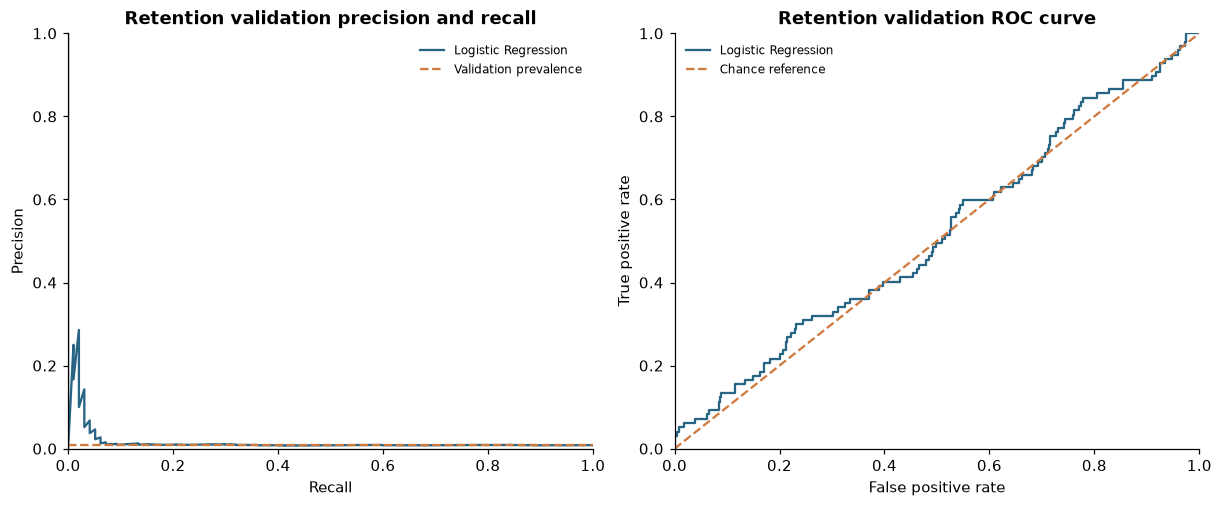

In [39]:
prior_probability = prior_baseline.predict_proba(dummy_validation_input)[:, 1]
logistic_probability = logistic_baseline.predict_proba(X_validation)[:, 1]

def repeat_classification_metrics(model_name, labels, probability):
    prediction = probability >= 0.5
    return {
        "model": model_name,
        "average_precision": average_precision_score(labels, probability),
        "roc_auc": roc_auc_score(labels, probability),
        "precision_at_0_5": precision_score(labels, prediction, zero_division=0),
        "recall_at_0_5": recall_score(labels, prediction, zero_division=0),
        "f1_at_0_5": f1_score(labels, prediction, zero_division=0),
        "predicted_positives": int(prediction.sum()),
    }

retention_baseline_rows = []
validation_confusion_matrices = {}
for model_name, probability in [
    ("Training prior", prior_probability),
    ("Logistic Regression", logistic_probability),
]:
    validation_confusion_matrices[model_name] = confusion_matrix(
        y_validation, probability >= 0.5, labels=[0, 1]
    )
    row = repeat_classification_metrics(model_name, y_validation, probability)
    row["brier_score"] = brier_score_loss(y_validation, probability)
    retention_baseline_rows.append(row)
retention_baseline_results = pd.DataFrame(retention_baseline_rows)
print(retention_baseline_results.drop(columns="brier_score").round(6).to_string(index=False))
print()
for model_name, matrix in validation_confusion_matrices.items():
    print(model_name)
    print(pd.DataFrame(matrix, index=["Actual non-repeat", "Actual repeat"],
                       columns=["Predicted non-repeat", "Predicted repeat"]).to_string())

pr_precision, pr_recall, _ = precision_recall_curve(y_validation, logistic_probability)
false_positive_rate, true_positive_rate, _ = roc_curve(y_validation, logistic_probability)
validation_prevalence = float(y_validation.mean())

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), layout="constrained")
axes[0].plot(pr_recall, pr_precision, color="#286484", label="Logistic Regression")
axes[0].axhline(validation_prevalence, color="#d17a3e", linestyle="--", label="Validation prevalence")
axes[0].set(xlim=(0, 1), ylim=(0, 1), title="Retention validation precision and recall",
            xlabel="Recall", ylabel="Precision")
axes[0].legend(frameon=False, fontsize=8)
axes[1].plot(false_positive_rate, true_positive_rate, color="#286484", label="Logistic Regression")
axes[1].plot([0, 1], [0, 1], "--", color="#d17a3e", label="Chance reference")
axes[1].set(xlim=(0, 1), ylim=(0, 1), title="Retention validation ROC curve",
            xlabel="False positive rate", ylabel="True positive rate")
axes[1].legend(frameon=False, fontsize=8)
plt.show()


### 6.3 Historical popularity and top-K metrics

Rank candidate products by the number of distinct historical buyers before the recommendation validation cutoff. Break equal-count ties by product identifier for reproducibility. Exclude each customer's already purchased products.

Return readable category labels alongside IDs and historical buyer counts. For a new customer, the same historical popularity list is the fallback. A metadata-only new item has no popularity evidence and is outside this baseline's candidate catalog.

Precision at K divides hits by K. Recall divides hits by the number of relevant future discovery items. NDCG discounts lower-ranked hits and normalizes against the ideal ordering. These formulas adapt the Week 10 helper definitions to binary purchase relevance. Global-mean and user-mean rating prediction are appropriate only for a separately justified explicit-rating task.


In [40]:
ranking_validation = recommendation_partitions["validation"]
popularity_table = (
    ranking_validation["history_pairs"].groupby("item")
    .size().rename("historical_buyers").reset_index()
    .sort_values(["historical_buyers", "item"], ascending=[False, True])
    .reset_index(drop=True)
)
popularity_items = popularity_table["item"].tolist()
popularity_counts = popularity_table.set_index("item")["historical_buyers"]
seen_products_by_user = (
    ranking_validation["history_pairs"].groupby("user")["item"].agg(set).to_dict()
)
category_lookup = products_prepared.set_index("product_id")["category_label"]

def recommend_popular(user, n=5):
    if not isinstance(n, int) or isinstance(n, bool) or not 1 <= n <= 100:
        raise ValueError("n must be an integer from 1 to 100.")
    seen = seen_products_by_user.get(user, set())
    selected = []
    for item in popularity_items:
        if item not in seen:
            selected.append(item)
        if len(selected) == n:
            break
    return pd.DataFrame({
        "product_id": selected,
        "category": category_lookup.reindex(selected).to_numpy(),
        "historical_buyers": popularity_counts.reindex(selected).to_numpy(),
    })

def top_k_metrics(recommended, relevant, k):
    if not isinstance(k, int) or isinstance(k, bool) or k < 1:
        raise ValueError("k must be a positive integer.")
    if len(set(recommended[:k])) != len(recommended[:k]):
        raise ValueError("Recommendations must be unique.")
    relevance = set(relevant)
    hits = np.array([item in relevance for item in recommended[:k]], dtype=float)
    discounts = 1 / np.log2(np.arange(len(hits)) + 2)
    ideal = (1 / np.log2(np.arange(min(k, len(relevance))) + 2)).sum()
    return {
        "precision": float(hits.sum() / k),
        "recall": float(hits.sum() / len(relevance)) if relevance else 0.0,
        "ndcg": float((hits * discounts).sum() / ideal) if ideal else 0.0,
        "hit_rate": float(hits.any()),
    }

print("Popularity candidates fitted from pre-validation purchase history:", len(popularity_items))
print(popularity_table.head(5).to_string(index=False))


Popularity candidates fitted from pre-validation purchase history: 22964
                            item  historical_buyers
99a4788cb24856965c36a24e339b6058                399
aca2eb7d00ea1a7b8ebd4e68314663af                281
422879e10f46682990de24d770e7f83d                265
154e7e31ebfa092203795c972e5804a6                253
389d119b48cf3043d311335e499d9c6b                252


In [41]:
relevance_by_user = ranking_validation["relevance"].groupby("user")["item"].agg(set).to_dict()
ranking_user_rows = []

for user, relevant in sorted(relevance_by_user.items()):
    recommended = recommend_popular(user, n=10)["product_id"].tolist()
    for k in [5, 10]:
        row = {"user": user, "k": k}
        row.update(top_k_metrics(recommended, relevant, k))
        ranking_user_rows.append(row)

ranking_user_results = pd.DataFrame(ranking_user_rows)
popularity_baseline_results = ranking_user_results.groupby("k").agg(
    users=("user", "nunique"),
    precision=("precision", "mean"),
    recall=("recall", "mean"),
    ndcg=("ndcg", "mean"),
    hit_rate=("hit_rate", "mean"),
).reset_index()

recommended_catalog = set()
for user in relevance_by_user:
    recommended_catalog.update(recommend_popular(user, n=10)["product_id"])
popularity_catalog_coverage = len(recommended_catalog) / len(popularity_items)

print(popularity_baseline_results.round(6).to_string(index=False))
print(f"Catalog coverage at 10 over evaluated warm users: {100 * popularity_catalog_coverage:.4f}%")
print("New-customer fallback example:")
new_user_recommendations = recommend_popular("__new_customer__", n=5)
print(new_user_recommendations.to_string(index=False))


 k  users  precision   recall     ndcg  hit_rate
 5     90   0.002222 0.011111 0.005556  0.011111
10     90   0.002222 0.022222 0.009061  0.022222
Catalog coverage at 10 over evaluated warm users: 0.0479%
New-customer fallback example:
                      product_id        category  historical_buyers
99a4788cb24856965c36a24e339b6058  bed_bath_table                399
aca2eb7d00ea1a7b8ebd4e68314663af furniture_decor                281
422879e10f46682990de24d770e7f83d    garden_tools                265
154e7e31ebfa092203795c972e5804a6   health_beauty                253
389d119b48cf3043d311335e499d9c6b    garden_tools                252


In [42]:
np.testing.assert_allclose(
    numeric_imputer.statistics_,
    X_train[RETENTION_NUMERIC_FEATURES].median().to_numpy(),
)
assert int(numeric_scaler.n_samples_seen_) == len(X_train)
assert set(state_encoder.categories_[0]) == set(X_train["customer_state"])
assert logistic_baseline.named_steps["classifier"].n_iter_.max() < 2000
assert not np.isnan(transformed_validation.data).any()
assert np.isfinite(transformed_validation.data).all()
assert np.isfinite(logistic_probability).all()
assert ((logistic_probability >= 0) & (logistic_probability <= 1)).all()
np.testing.assert_allclose(prior_probability, y_train.mean())
assert np.isclose(
    average_precision_score(y_validation, prior_probability), y_validation.mean()
)

toy_metrics = top_k_metrics(["A", "B", "C"], {"B", "D"}, 3)
assert np.isclose(toy_metrics["precision"], 1 / 3)
assert np.isclose(toy_metrics["recall"], 1 / 2)
assert np.isclose(toy_metrics["ndcg"], (1 / np.log2(3)) / (1 + 1 / np.log2(3)))

for user in relevance_by_user:
    recommendations = recommend_popular(user, n=10)
    assert recommendations["product_id"].is_unique
    assert set(recommendations["product_id"]).isdisjoint(seen_products_by_user[user])
    assert recommendations["product_id"].isin(ranking_validation["candidate_items"]).all()
assert len(new_user_recommendations) == 5
assert new_user_recommendations["category"].notna().all()

single_history_user = next(user for user, seen in seen_products_by_user.items() if len(seen) == 1)
assert len(recommend_popular(single_history_user, n=5)) == 5
assert set(recommend_popular(single_history_user, n=5)["product_id"]).isdisjoint(
    seen_products_by_user[single_history_user]
)
assert "__metadata_only_new_item__" not in set(popularity_items)
assert set(popularity_items) == set(ranking_validation["candidate_items"])
assert ranking_user_results["user"].nunique() == ranking_validation["relevance"]["user"].nunique()

print("Training-only preprocessing, prior probabilities, metric formulas, and recommendation checks passed.")
print("Final test performance remains reserved for the locked model comparison.")


Training-only preprocessing, prior probabilities, metric formulas, and recommendation checks passed.
Final test performance remains reserved for the locked model comparison.


### Baseline results and interpretation

| Model | Validation average precision | Validation ROC-AUC | Predicted positives at 0.5 |
|---|---:|---:|---:|
| Training prior | 0.008243 | 0.500000 | 0 |
| Logistic Regression | 0.016882 | 0.515552 | 0 |

Logistic Regression has weak overall validation discrimination. At the initial 0.5 threshold both baselines predict no repeats. Threshold selection and final test performance belong to later model selection and evaluation.

Popularity has validation Recall at 5 of 0.011111 and NDCG at 5 of 0.005556 across 90 eligible warm customers. At ten products its Recall is 0.022222 and NDCG is 0.009061.

The baseline integrity checks are part of the core workflow. Bootstrap intervals and Brier reporting are supplementary material in Appendix A. The toy metric check is distinct from the future collaborative by-hand example.


## 7 Neighbors and decision trees

This topic follows Unit II and Labs 5 and 6. Compare KNN and library decision trees using the established training and validation cohorts. Implement categorical ID3 as a separate learning example. Final test scoring remains reserved for the locked comparison.

KNN uses scaled numeric features because magnitude affects distance. Trees reuse median imputation and state encoding, with scaling passed through so thresholds retain their prepared feature units. Log-transformed monetary fields remain log-transformed.

Scikit-learn's library tree is CART with entropy splitting. The recursive ID3 example below demonstrates categorical multiway splits.

### 7.1 Fit a small set of course configurations

Compare K=5 and K=15 using uniform voting and Euclidean distance. Compare entropy-based trees at depths 3 and 6, each requiring at least 50 training observations per leaf.

These predeclared configurations illustrate K and depth before later tuning. Cloning resets learned preprocessing state so each estimator fits its transformations on training only. The memory setting bounds distance-computation work buffers.

Training average precision is an in-sample diagnostic. KNN training queries can include the query point itself, which makes apparent training performance optimistic.

In [43]:
from sklearn.base import clone
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn import config_context

tree_preprocessing = clone(retention_preprocessing)
tree_preprocessing.set_params(numeric__scaler="passthrough")

course_classifier_models = {
    "KNN k=5": Pipeline([
        ("preprocessing", clone(retention_preprocessing)),
        ("classifier", KNeighborsClassifier(n_neighbors=5, weights="uniform",
                                            metric="euclidean", algorithm="brute", n_jobs=1)),
    ]),
    "KNN k=15": Pipeline([
        ("preprocessing", clone(retention_preprocessing)),
        ("classifier", KNeighborsClassifier(n_neighbors=15, weights="uniform",
                                            metric="euclidean", algorithm="brute", n_jobs=1)),
    ]),
    "Tree depth=3": Pipeline([
        ("preprocessing", clone(tree_preprocessing)),
        ("classifier", DecisionTreeClassifier(criterion="entropy", max_depth=3,
                                              min_samples_leaf=50, random_state=42)),
    ]),
    "Tree depth=6": Pipeline([
        ("preprocessing", clone(tree_preprocessing)),
        ("classifier", DecisionTreeClassifier(criterion="entropy", max_depth=6,
                                              min_samples_leaf=50, random_state=42)),
    ]),
}

neighbor_tree_rows = []
course_validation_probabilities = {}

with config_context(working_memory=128):
    for model_name, estimator in course_classifier_models.items():
        estimator.fit(X_train, y_train)
        train_probability = estimator.predict_proba(X_train)[:, 1]
        validation_probability = estimator.predict_proba(X_validation)[:, 1]
        course_validation_probabilities[model_name] = validation_probability
        row = repeat_classification_metrics(model_name, y_validation, validation_probability)
        row["training_average_precision"] = average_precision_score(y_train, train_probability)
        row["validation_customers"] = len(y_validation)
        neighbor_tree_rows.append(row)

neighbor_tree_results = pd.DataFrame(neighbor_tree_rows)
print(neighbor_tree_results.round(6).to_string(index=False))

       model  average_precision  roc_auc  precision_at_0_5  recall_at_0_5  f1_at_0_5  predicted_positives  training_average_precision  validation_customers
     KNN k=5           0.008216 0.498250               0.0            0.0        0.0                    0                    0.215187                 11768
    KNN k=15           0.008963 0.529690               0.0            0.0        0.0                    0                    0.074084                 11768
Tree depth=3           0.007915 0.471039               0.0            0.0        0.0                    0                    0.019506                 11768
Tree depth=6           0.007718 0.467589               0.0            0.0        0.0                    0                    0.032750                 11768


### KNN worked example

Choose the highest-scored validation customer under K=5 to illustrate a neighbor vote. This is a deliberately selected teaching example.

Print the five neighbor labels and their distances. For uniform voting, repeat probability is the number of repeat-labeled neighbors divided by five. Independently calculate Euclidean distance over the transformed features as the square root of the sum of squared coordinate differences.


In [44]:
knn_demo = course_classifier_models["KNN k=5"]
example_position = int(np.argmax(course_validation_probabilities["KNN k=5"]))
example_query = knn_demo.named_steps["preprocessing"].transform(
    X_validation.iloc[[example_position]]
)
neighbor_distances, neighbor_positions = knn_demo.named_steps["classifier"].kneighbors(
    example_query, n_neighbors=5
)
neighbor_indices = neighbor_positions[0]
neighbor_labels = y_train.iloc[neighbor_indices].to_numpy()
neighbor_features = knn_demo.named_steps["preprocessing"].transform(
    X_train.iloc[neighbor_indices]
)
manual_distances = np.sqrt(
    ((neighbor_features.toarray() - example_query.toarray()) ** 2).sum(axis=1)
)
manual_knn_probability = float(neighbor_labels.mean())
example_probability = float(
    knn_demo.named_steps["classifier"].predict_proba(example_query)[0, 1]
)

knn_worked_example = pd.DataFrame({
    "neighbor_rank": np.arange(1, 6),
    "euclidean_distance": neighbor_distances[0],
    "independent_distance": manual_distances,
    "training_repeat_label": neighbor_labels,
})
np.testing.assert_allclose(manual_distances, neighbor_distances[0], atol=1e-6)
assert np.isclose(manual_knn_probability, example_probability)

print(knn_worked_example.round(6).to_string(index=False))
print(f"Uniform vote: {int(neighbor_labels.sum())} / 5 = {manual_knn_probability:.3f}")
print(f"Library probability for this query: {example_probability:.3f}")
print(f"Actual validation label for the teaching example: {int(y_validation.iloc[example_position])}")


 neighbor_rank  euclidean_distance  independent_distance  training_repeat_label
             1            1.058510              1.058510                      1
             2            1.085889              1.085889                      0
             3            1.163920              1.163920                      0
             4            1.253343              1.253343                      0
             5            1.378057              1.378057                      1
Uniform vote: 2 / 5 = 0.400
Library probability for this query: 0.400
Actual validation label for the teaching example: 0


### 7.2 Compare validation results and errors

Reuse the baseline metric function so class ordering, probabilities and the fixed 0.5 threshold are consistent. Compare training and validation average precision, plus false positives and false negatives. A training improvement requires independent validation support.

Average precision supports positive-case ranking under imbalance. Precision, recall, F1 and confusion counts describe decisions at the stated threshold.

              model  average_precision  roc_auc  precision_at_0_5  recall_at_0_5  f1_at_0_5  predicted_positives
     Training prior           0.008243 0.500000               0.0            0.0        0.0                    0
Logistic Regression           0.016882 0.515552               0.0            0.0        0.0                    0
            KNN k=5           0.008216 0.498250               0.0            0.0        0.0                    0
           KNN k=15           0.008963 0.529690               0.0            0.0        0.0                    0
       Tree depth=3           0.007915 0.471039               0.0            0.0        0.0                    0
       Tree depth=6           0.007718 0.467589               0.0            0.0        0.0                    0

       model  true_negative  false_positive  false_negative  true_positive  maximum_repeat_probability
     KNN k=5          11671               0              97              0                    0.400000
  

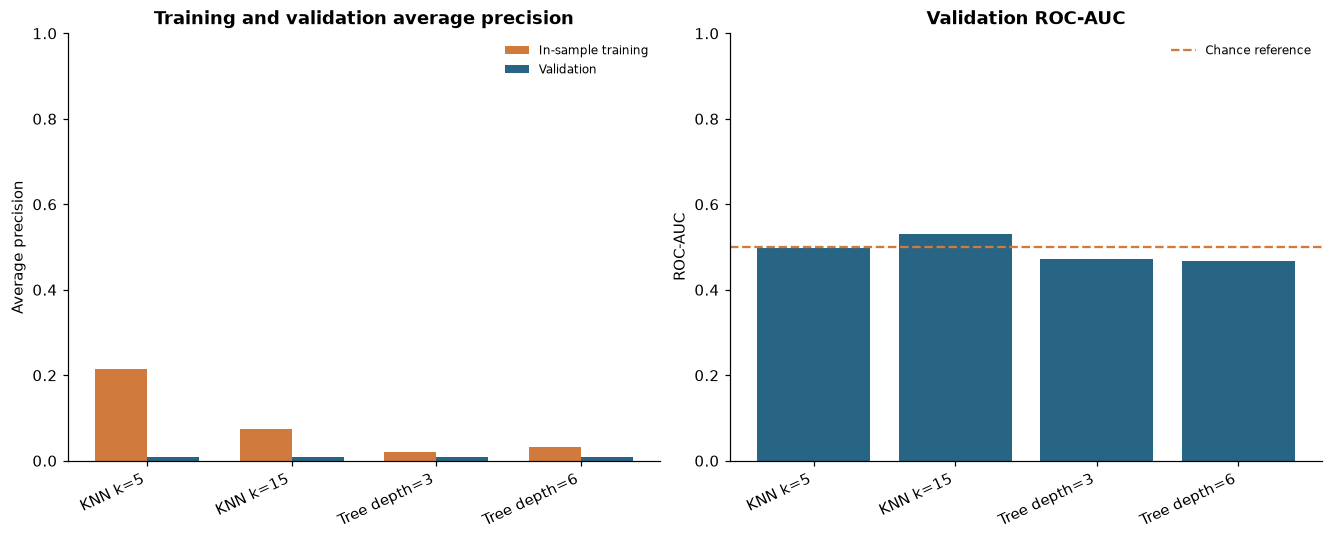

In [45]:
comparison_columns = [
    "model", "average_precision", "roc_auc", "precision_at_0_5",
    "recall_at_0_5", "f1_at_0_5", "predicted_positives",
]
retention_comparison_results = pd.concat([
    retention_baseline_results[comparison_columns],
    neighbor_tree_results[comparison_columns],
], ignore_index=True)

course_error_rows = []
for model_name, probability in course_validation_probabilities.items():
    matrix = confusion_matrix(y_validation, probability >= 0.5, labels=[0, 1])
    true_negative, false_positive, false_negative, true_positive = matrix.ravel()
    course_error_rows.append({
        "model": model_name,
        "true_negative": int(true_negative),
        "false_positive": int(false_positive),
        "false_negative": int(false_negative),
        "true_positive": int(true_positive),
        "maximum_repeat_probability": float(probability.max()),
    })
course_error_summary = pd.DataFrame(course_error_rows)

print(retention_comparison_results.round(6).to_string(index=False))
print()
print(course_error_summary.round(6).to_string(index=False))

positions = np.arange(len(neighbor_tree_results))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained")
axes[0].bar(positions - 0.18, neighbor_tree_results["training_average_precision"],
            width=0.36, color="#d17a3e", label="In-sample training")
axes[0].bar(positions + 0.18, neighbor_tree_results["average_precision"],
            width=0.36, color="#286484", label="Validation")
axes[0].set_xticks(positions, labels=neighbor_tree_results["model"], rotation=25, ha="right")
axes[0].set(title="Training and validation average precision", ylabel="Average precision", ylim=(0, 1))
axes[0].legend(frameon=False, fontsize=8)
axes[1].bar(positions, neighbor_tree_results["roc_auc"], color="#286484")
axes[1].axhline(0.5, color="#d17a3e", linestyle="--", label="Chance reference")
axes[1].set_xticks(positions, labels=neighbor_tree_results["model"], rotation=25, ha="right")
axes[1].set(title="Validation ROC-AUC", ylabel="ROC-AUC", ylim=(0, 1))
axes[1].legend(frameon=False, fontsize=8)
plt.show()

### 7.3 Read the library tree

Display the upper two levels of the depth-three tree. Each node shows a split, entropy, training sample count and class counts. Class order is non-repeat followed by repeat.

Thresholds apply to prepared feature names. Monetary fields prefixed log1p are already transformed. Numeric scaling is disabled in tree pipelines.

This is a CART implementation with entropy. The ID3 example uses categorical multiway splits.

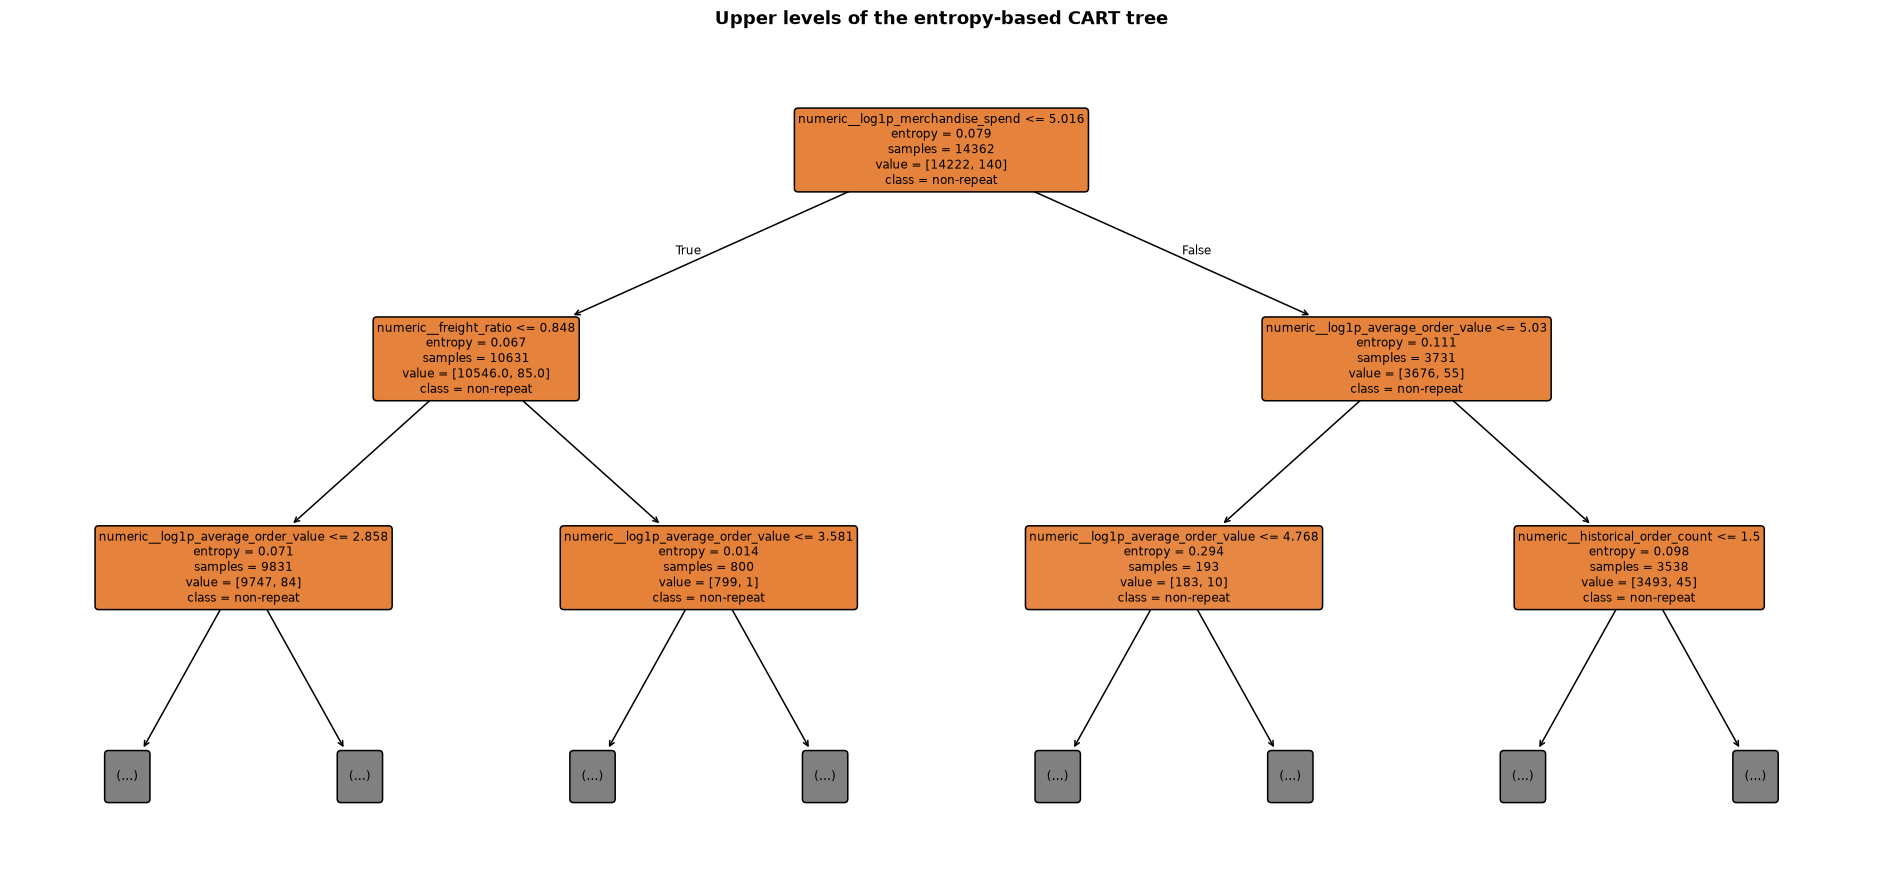

In [46]:
tree_demo = course_classifier_models["Tree depth=3"]
tree_feature_names = tree_demo.named_steps["preprocessing"].get_feature_names_out()
fig, ax = plt.subplots(figsize=(17, 8), layout="constrained")
plot_tree(
    tree_demo.named_steps["classifier"],
    max_depth=2,
    feature_names=tree_feature_names.tolist(),
    class_names=["non-repeat", "repeat"],
    filled=True, rounded=True, fontsize=8, ax=ax,
)
ax.set_title("Upper levels of the entropy-based CART tree", pad=14)
plt.show()

### 7.4 Prepare the ID3 learning example

Represent three historical fields as categorical attributes. Distinguish one versus multiple past orders, unknown/lower/higher known review score, and unknown/shorter/longer known delivery duration.

Review groups are scores 1 to 3 and 4 to 5. Delivery groups use a fixed ten-day teaching boundary. The bins are declared for the demonstration and are not optimized against validation labels.

Entropy is minus the sum of p times log2(p) over classes. Information gain is parent entropy minus weighted child entropies. ID3 selects the highest-gain categorical attribute and creates a branch per value.

This teaching representation uses fewer and coarser inputs than the library comparisons. Both algorithm and representation differ in this separate example.

In [47]:
def make_id3_attributes(features):
    attributes = pd.DataFrame(index=features.index)
    attributes["order_history"] = np.where(
        features["historical_order_count"].ge(2), "multiple_orders", "one_order"
    )
    attributes["known_review"] = np.select(
        [features["mean_known_review_score"].isna(),
         features["mean_known_review_score"].le(3)],
        ["unknown", "score_1_to_3"], default="score_4_to_5",
    )
    attributes["known_delivery"] = np.select(
        [features["mean_known_delivery_days"].isna(),
         features["mean_known_delivery_days"].le(10)],
        ["unknown", "up_to_10_days"], default="over_10_days",
    )
    return attributes

def class_entropy(labels):
    proportions = labels.value_counts(normalize=True)
    return float(-(proportions * np.log2(proportions)).sum())

def categorical_information_gain(frame, feature, target):
    parent_entropy = class_entropy(frame[target])
    weighted_child_entropy = sum(
        len(group) / len(frame) * class_entropy(group[target])
        for _, group in frame.groupby(feature, sort=True)
    )
    return parent_entropy - weighted_child_entropy

id3_train_attributes = make_id3_attributes(X_train)
id3_validation_attributes = make_id3_attributes(X_validation)
id3_training_data = id3_train_attributes.copy()
id3_training_data["repeat_90d"] = y_train

id3_root_gains = pd.DataFrame([
    {
        "attribute": attribute,
        "information_gain": categorical_information_gain(
            id3_training_data, attribute, "repeat_90d"
        ),
    }
    for attribute in id3_train_attributes.columns
]).sort_values("information_gain", ascending=False)

print(f"Training target entropy: {class_entropy(y_train):.6f} bits")
print(id3_root_gains.round(8).to_string(index=False))

Training target entropy: 0.079118 bits
     attribute  information_gain
 order_history          0.000593
  known_review          0.000069
known_delivery          0.000003


### 7.5 Build and use the ID3 tree

Retain a node's training sample count and class proportion. Stop when labels are pure, attributes are exhausted, or no gain remains. Otherwise split by the highest-gain attribute and recurse after removing it from the remaining attributes.

Prediction follows a branch for each categorical value. An unseen value falls back to the current node's training class proportion. Leaf scores are empirical proportions and have not been probability-calibrated.

The path length is bounded by the three input attributes.

In [48]:
def fit_id3(frame, attributes, target):
    node = {
        "samples": len(frame),
        "repeat_probability": float(frame[target].mean()),
        "attribute": None,
        "branches": {},
    }
    if frame[target].nunique() == 1 or not attributes:
        return node
    gains = {
        attribute: categorical_information_gain(frame, attribute, target)
        for attribute in attributes
    }
    best_attribute = max(gains, key=gains.get)
    if gains[best_attribute] <= 1e-12:
        return node

    node["attribute"] = best_attribute
    remaining = [attribute for attribute in attributes if attribute != best_attribute]
    for value, group in frame.groupby(best_attribute, sort=True):
        node["branches"][str(value)] = fit_id3(group, remaining, target)
    return node

def id3_probability(tree, attributes):
    node = tree
    while node["attribute"] is not None:
        value = str(attributes[node["attribute"]])
        child = node["branches"].get(value)
        if child is None:
            return node["repeat_probability"]
        node = child
    return node["repeat_probability"]

id3_model = fit_id3(
    id3_training_data, id3_train_attributes.columns.tolist(), "repeat_90d"
)
id3_validation_probability = np.array([
    id3_probability(id3_model, row)
    for row in id3_validation_attributes.to_dict("records")
])
id3_validation_results = pd.DataFrame([
    repeat_classification_metrics(
        "Teaching ID3 with 3 categorical attributes", y_validation, id3_validation_probability
    )
])
print(f"ID3 root attribute: {id3_model['attribute']}")
print(id3_validation_results.round(6).to_string(index=False))

ID3 root attribute: order_history
                                     model  average_precision  roc_auc  precision_at_0_5  recall_at_0_5  f1_at_0_5  predicted_positives
Teaching ID3 with 3 categorical attributes           0.012043 0.527934               0.0            0.0        0.0                    0


### 7.6 Work through the root split

Show each branch's class counts, entropy and weighted contribution. Root information gain is parent entropy minus the sum of weighted child entropies.

For binary labels, entropy is minus p0 times log2(p0) minus p1 times log2(p1). A zero-probability contribution is zero, and a pure branch has zero entropy. Reproduce the printed calculation with a calculator.

In [49]:
id3_branch_rows = []
root_attribute = id3_model["attribute"]
for value, group in id3_training_data.groupby(root_attribute, sort=True):
    negatives = int(group["repeat_90d"].eq(0).sum())
    positives = int(group["repeat_90d"].eq(1).sum())
    entropy = class_entropy(group["repeat_90d"])
    weight = len(group) / len(id3_training_data)
    id3_branch_rows.append({
        "branch": value, "non_repeat": negatives, "repeat": positives,
        "samples": len(group), "entropy_bits": entropy,
        "weight": weight, "weighted_entropy": weight * entropy,
    })
id3_branch_calculation = pd.DataFrame(id3_branch_rows)
id3_parent_entropy = class_entropy(y_train)
id3_weighted_child_entropy = float(id3_branch_calculation["weighted_entropy"].sum())
id3_calculated_gain = id3_parent_entropy - id3_weighted_child_entropy

print(id3_branch_calculation.round(8).to_string(index=False))
print(f"Parent entropy: {id3_parent_entropy:.8f}")
print(f"Weighted child entropy: {id3_weighted_child_entropy:.8f}")
print(f"Information gain: {id3_calculated_gain:.8f}")

         branch  non_repeat  repeat  samples  entropy_bits   weight  weighted_entropy
multiple_orders         274      10      284      0.219888 0.019774          0.004348
      one_order       13948     130    14078      0.075673 0.980226          0.074177
Parent entropy: 0.07911751
Weighted child entropy: 0.07852473
Information gain: 0.00059278


In [50]:
for model_name, estimator in course_classifier_models.items():
    preprocessor = estimator.named_steps["preprocessing"]
    imputer = preprocessor.named_transformers_["numeric"].named_steps["imputer"]
    np.testing.assert_allclose(
        imputer.statistics_, X_train[RETENTION_NUMERIC_FEATURES].median().to_numpy()
    )
    encoder = preprocessor.named_transformers_["categorical"].named_steps["encoder"]
    assert set(encoder.categories_[0]) == set(X_train["customer_state"])
    probability = course_validation_probabilities[model_name]
    assert len(probability) == len(y_validation)
    assert np.isfinite(probability).all()
    assert ((probability >= 0) & (probability <= 1)).all()
    if model_name.startswith("KNN"):
        scaler = preprocessor.named_transformers_["numeric"].named_steps["scaler"]
        assert int(scaler.n_samples_seen_) == len(X_train)
    else:
        assert preprocessor.named_transformers_["numeric"].named_steps["scaler"] == "passthrough"
        tree = estimator.named_steps["classifier"]
        assert tree.get_depth() <= tree.max_depth
        leaves = tree.tree_.children_left == -1
        assert (tree.tree_.n_node_samples[leaves] >= tree.min_samples_leaf).all()

assert id3_train_attributes.index.equals(y_train.index)
assert id3_validation_attributes.index.equals(y_validation.index)
assert id3_training_data["repeat_90d"].notna().all()
assert set(id3_training_data["repeat_90d"].unique()) == {0, 1}
assert np.isclose(class_entropy(pd.Series([0, 0, 0])), 0)
assert np.isclose(class_entropy(pd.Series([0, 1])), 1)
assert np.isclose(
    id3_calculated_gain,
    categorical_information_gain(id3_training_data, root_attribute, "repeat_90d"),
)
assert np.isclose(id3_model["repeat_probability"], y_train.mean())
assert np.isfinite(id3_validation_probability).all()
assert ((id3_validation_probability >= 0) & (id3_validation_probability <= 1)).all()

unseen_attributes = id3_validation_attributes.iloc[0].to_dict()
unseen_attributes[root_attribute] = "__unseen_value__"
assert np.isclose(id3_probability(id3_model, unseen_attributes), y_train.mean())
assert len(neighbor_tree_results) == 4
assert len(retention_comparison_results) == 6
print("Training fits, outputs, tree limits, entropy, gain and unseen-value fallback passed.")
print("Final test performance remains reserved for the locked comparison.")
perfect_split = pd.DataFrame({
    "attribute": ["a", "a", "b", "b"],
    "label": [0, 0, 1, 1],
})
assert np.isclose(categorical_information_gain(perfect_split, "attribute", "label"), 1)
perfect_tree = fit_id3(perfect_split, ["attribute"], "label")
assert id3_probability(perfect_tree, {"attribute": "a"}) == 0
assert id3_probability(perfect_tree, {"attribute": "b"}) == 1
assert id3_probability(perfect_tree, {"attribute": "unseen"}) == 0.5
constant_attribute = pd.DataFrame({"attribute": ["a", "a"], "label": [0, 1]})
constant_tree = fit_id3(constant_attribute, ["attribute"], "label")
assert constant_tree["attribute"] is None
assert constant_tree["repeat_probability"] == 0.5
print("Small entropy, perfect-split, no-gain and fallback sanity checks passed.")


Training fits, outputs, tree limits, entropy, gain and unseen-value fallback passed.
Final test performance remains reserved for the locked comparison.
Small entropy, perfect-split, no-gain and fallback sanity checks passed.


### Viva checklist

- Explain Euclidean distance and why scaling changes KNN neighbors.
- Explain how K changes locality, smoothness and rare-class voting.
- Explain why KNN in-sample training results can be optimistic.
- Read a tree split, entropy, class count, depth and leaf constraint.
- Distinguish CART from categorical ID3.
- Reproduce the root information-gain calculation.
- Explain the categorical teaching representation and unseen-value fallback.
- Interpret validation errors and the limits imposed by rare outcomes.


### Neighbors trees and ID3 results

| model | training_average_precision | average_precision | roc_auc |
| --- | --- | --- | --- |
| KNN k=5 | 0.215187 | 0.008216 | 0.49825 |
| KNN k=15 | 0.074084 | 0.008963 | 0.52969 |
| Tree depth=3 | 0.019506 | 0.007915 | 0.471039 |
| Tree depth=6 | 0.03275 | 0.007718 | 0.467589 |

K=15 reduces the apparent KNN training-validation gap relative to K=5, while validation discrimination remains weak. KNN in-sample queries can include themselves, so the training score is optimistic.

The deeper tree has greater training average precision and slightly worse validation metrics in this comparison. The tested configurations provide no observed validation improvement over the Logistic Regression baseline on the primary average-precision metric. Final model selection remains pending.

All four library configurations predict no repeats at threshold 0.5. Their probability rankings differ. Adjusting the threshold changes decisions and confusion counts, while ranking quality needs separate evaluation.

| model | average_precision | roc_auc |
| --- | --- | --- |
| Teaching ID3 with 3 categorical attributes | 0.012043 | 0.527934 |The ID3 example is implemented from the categorical information-gain algorithm and uses three coarsened historical attributes. Its metrics reflect this separate representation as well as the algorithm.

The KNN example reproduces five Euclidean distances and the two-out-of-five vote, giving a repeat score of 0.4. The selected customer is a non-repeat case in validation. It was deliberately chosen for teaching.

The ID3 root is order_history. Its parent entropy is approximately 0.07911751 bits, weighted child entropy 0.07852473 bits, and information gain 0.00059278 bits. The low starting entropy reflects the rare positive class.

**Completed** — Unit II KNN and decision-tree comparisons, error counts, a CART visualization, recursive categorical ID3, a worked neighbor vote, a root gain calculation, and model integrity checks.

**Next topic** — Syllabus content-based and item-based collaborative recommendations with cold-start behavior and the existing ranking protocol.

**Topic commit message** — `feat: compare KNN and trees with ID3 viva examples`.

The notebook and reference notes are one topic contribution. Bootstrap and Brier material is retained in Appendix A for supplementary study.

## 8 Content based and item based collaborative recommendations

Unit II explicitly covers content-based and collaborative filtering systems. Compare both with the historical popularity baseline using the fixed validation candidates and future discovery relevance from Section 5.5.

Content uses category and a price band. Collaborative filtering uses shared historical buyers. The two methods represent products differently even though both use cosine similarity.

Fit everything using pre-validation history and its observed candidate products. Use the same 90 eligible warm-validation customers and evaluate at five and ten recommendations. Report fallback behavior and coverage alongside ranking quality. Final test scoring remains reserved.

Product metadata is treated as a stable description of products observed before the cutoff. Historical prices are calculated strictly from earlier order items. This static dataset cannot establish the history of later category edits or stock availability.

### 8.1 Build content vectors from historical candidate metadata

Calculate each candidate product's median observed price before the validation cutoff. Learn quartile boundaries from those candidate medians and assign price bands. This gives a coarse price description without assuming unavailable product titles or descriptions.

One-hot encode category and price band. Give category coordinates weight two and price-band coordinates weight one, then normalize each product vector to length one. This fixed teaching choice gives category agreement more influence. It is a declared setting rather than an optimized weight.

For products with the same known metadata fields, the weighted dot product is four for category agreement plus one for price-band agreement. Each raw vector has squared length five. Consequently, item similarity can be 1, 0.8, 0.2, or 0 for the two-field representation.

A customer's content profile will be the normalized sum of vectors for their distinct historical products.

In [51]:
from scipy import sparse
from sklearn.preprocessing import normalize

rec_item_ids = ranking_validation["candidate_items"]
rec_user_ids = pd.Index(sorted(ranking_validation["history_pairs"]["user"].unique()))

price_history_events = purchase_events.loc[
    purchase_events["order_purchase_timestamp"].lt(ranking_validation["cutoff"])
    & purchase_events["product_id"].isin(rec_item_ids)
]
historical_item_prices = price_history_events.groupby("product_id")["price"].median()

content_catalog = products_prepared.set_index("product_id").reindex(rec_item_ids)[
    ["category_label"]
].copy()
content_catalog["historical_price"] = historical_item_prices.reindex(rec_item_ids)

price_breaks = np.unique(
    content_catalog["historical_price"].quantile([0.25, 0.5, 0.75]).to_numpy()
)
price_bin_edges = np.r_[-np.inf, price_breaks, np.inf]
price_band_names = [f"price_band_{i + 1}" for i in range(len(price_bin_edges) - 1)]

def content_metadata_fields(metadata):
    fields = pd.DataFrame(index=metadata.index)
    fields["category_label"] = metadata["category_label"].astype("string").fillna("unknown")
    fields["price_band"] = pd.cut(
        metadata["historical_price"], bins=price_bin_edges, labels=price_band_names
    ).astype("string").fillna("unknown_price")
    return fields

content_fields = content_metadata_fields(content_catalog)
content_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=True)
encoded_content = content_encoder.fit_transform(content_fields)
content_feature_names = content_encoder.get_feature_names_out()
content_feature_weights = np.array([
    2.0 if name.startswith("category_label_") else 1.0
    for name in content_feature_names
])
content_item_vectors = normalize(
    encoded_content.multiply(content_feature_weights).tocsr(), norm="l2"
)

def encode_additional_content(metadata):
    encoded = content_encoder.transform(content_metadata_fields(metadata))
    return normalize(encoded.multiply(content_feature_weights).tocsr(), norm="l2")

rec_popularity = popularity_counts.reindex(rec_item_ids).to_numpy(dtype=float)
rec_item_strings = rec_item_ids.to_numpy(dtype=str)

print("Historical price-band boundaries in BRL:", price_breaks)
print("Content matrix shape:", content_item_vectors.shape)
print("Category weight: 2. Price-band weight: 1.")

Historical price-band boundaries in BRL: [ 39.9   78.99 152.  ]
Content matrix shape: (22964, 77)
Category weight: 2. Price-band weight: 1.


### 8.2 Learn item similarities from binary purchases

Create a sparse customer-product matrix from distinct historical pairs. An observed purchase has value one. An absent entry means no observed purchase in this history.

Column cosine similarity compares products by their buyers. Its numerator counts shared buyers and its denominator is the square root of the product of their buyer counts.

Remove self-similarity and keep up to twenty strongest neighbors per source product, with product-index tie breaking. Row-wise neighbor selection can make the pruned matrix asymmetric. A customer scores an unseen candidate by summing the retained similarities from their historical products.

Use sparse matrices to avoid allocating the full customer-product or product-product grid as dense arrays.

In [52]:
training_pairs = ranking_validation["history_pairs"]
assert not training_pairs.duplicated(["user", "item"]).any()

interaction_matrix = sparse.csr_matrix(
    (
        np.ones(len(training_pairs), dtype=float),
        (
            rec_user_ids.get_indexer(training_pairs["user"]),
            rec_item_ids.get_indexer(training_pairs["item"]),
        ),
    ),
    shape=(len(rec_user_ids), len(rec_item_ids)),
)
normalized_item_columns = normalize(interaction_matrix, norm="l2", axis=0)
item_similarity = (normalized_item_columns.T @ normalized_item_columns).tocsr()
item_similarity.setdiag(0)
item_similarity.eliminate_zeros()

ITEM_NEIGHBORS = 20
for row in range(item_similarity.shape[0]):
    start, end = item_similarity.indptr[row:row + 2]
    values = item_similarity.data[start:end]
    columns = item_similarity.indices[start:end]
    if len(values) > ITEM_NEIGHBORS:
        order = np.lexsort((columns, -values))
        discard = np.ones(len(values), dtype=bool)
        discard[order[:ITEM_NEIGHBORS]] = False
        values[discard] = 0
item_similarity.eliminate_zeros()

dense_grid_gib = interaction_matrix.shape[0] * interaction_matrix.shape[1] * 8 / 1024**3
sparse_storage_mib = (
    interaction_matrix.data.nbytes
    + interaction_matrix.indices.nbytes
    + interaction_matrix.indptr.nbytes
) / 1024**2

print("Customer-product matrix shape:", interaction_matrix.shape)
print("Observed binary interactions:", interaction_matrix.nnz)
print("Retained directed item-similarity links:", item_similarity.nnz)
print(f"Theoretical dense float64 customer grid: {dense_grid_gib:.2f} GiB")
print(f"Stored CSR arrays: {sparse_storage_mib:.2f} MiB")

Customer-product matrix shape: (63881, 22964)
Observed binary interactions: 68203
Retained directed item-similarity links: 9928
Theoretical dense float64 customer grid: 10.93 GiB
Stored CSR arrays: 1.02 MiB


### 8.3 Score and return recommendations

Score candidates from a known customer's historical row. Content compares the normalized profile with item vectors. Collaborative scores sum item-neighbor similarities. Exclude already purchased products.

Sort by model score, then historical buyer count, then product ID. Popularity tie breaking is explicit because coarse content vectors often tie. If a method supplies fewer positive-scored candidates than requested, fill remaining positions from historical popularity and label those rows. New customers receive a documented popularity fallback.

Scores represent similarity or purchase-pattern affinity. They are not calibrated purchase probabilities.

In [53]:
def raw_recommendation_scores(user, method):
    if method not in {"popularity", "content", "collaborative"}:
        raise ValueError("Choose popularity, content, or collaborative.")
    if method == "popularity":
        return rec_popularity.copy()
    position = rec_user_ids.get_indexer([user])[0]
    if position < 0:
        return np.zeros(len(rec_item_ids), dtype=float)
    history_row = interaction_matrix.getrow(position)
    if method == "content":
        profile = normalize(history_row @ content_item_vectors, norm="l2")
        return (content_item_vectors @ profile.T).toarray().ravel()
    if method == "collaborative":
        return (history_row @ item_similarity).toarray().ravel()
    raise ValueError("Choose popularity, content, or collaborative.")

def recommend_syllabus(user, method="content", n=5):
    if method not in {"popularity", "content", "collaborative"}:
        raise ValueError("Choose popularity, content, or collaborative.")
    if not isinstance(n, int) or isinstance(n, bool) or not 1 <= n <= 100:
        raise ValueError("n must be an integer from 1 to 100.")

    position = rec_user_ids.get_indexer([user])[0]
    scores = raw_recommendation_scores(user, method)
    is_new_user = position < 0
    if is_new_user or method == "popularity":
        scores = rec_popularity.copy()
    scores = scores.copy()
    if position >= 0:
        scores[interaction_matrix.getrow(position).indices] = -np.inf

    eligible = np.flatnonzero(np.isfinite(scores))
    order = np.lexsort((
        rec_item_strings[eligible], -rec_popularity[eligible], -scores[eligible]
    ))
    selected = eligible[order[:n]]
    fallback = np.zeros(len(selected), dtype=bool)
    if method != "popularity":
        fallback = np.full(len(selected), is_new_user) | (scores[selected] <= 0)

    reasons = []
    for uses_fallback in fallback:
        if uses_fallback:
            reasons.append("Historical popularity fallback")
        elif method == "content":
            reasons.append("Category and historical price-band similarity")
        elif method == "collaborative":
            reasons.append("Shared historical buyer patterns")
        else:
            reasons.append("Historical buyer popularity")

    return pd.DataFrame({
        "product_id": rec_item_ids[selected].to_numpy(),
        "category": content_catalog.iloc[selected]["category_label"].str.replace("_", " ").to_numpy(),
        "historical_price": content_catalog.iloc[selected]["historical_price"].to_numpy(),
        "model_score": scores[selected],
        "popularity_fallback": fallback,
        "reason": reasons,
    })

### 8.4 Compare the three methods on the same validation customers

Reuse the top-K metrics and relevance sets from the baseline. Evaluate all eligible users without sampling. Report full-list fallback frequency and the fraction of individual recommendation positions filled through popularity.

For known-user content or collaborative lists, a positive model score supplies method evidence. Zero-scored positions use popularity tie breaking and are marked as fills. Popularity is its own baseline, so its lists are not labeled as a fallback.

Catalog coverage is the fraction of historical candidates appearing in at least one evaluated top-K list. The metrics still describe the 90 eligible warm-discovery customers, rather than the entire future-customer population.

       method  k  users  precision   recall     ndcg  hit_rate  fallback_item_fraction  full_list_fallback  catalog_coverage
collaborative  5     90   0.002222 0.005556 0.006813  0.011111                0.771111            0.611111          0.004311
collaborative 10     90   0.002222 0.016667 0.010318  0.022222                0.848889            0.611111          0.005443
      content  5     90   0.004444 0.022222 0.015409  0.022222                0.000000            0.000000          0.011235
      content 10     90   0.003333 0.033333 0.018621  0.033333                0.000000            0.000000          0.022383
   popularity  5     90   0.002222 0.011111 0.005556  0.011111                0.000000            0.000000          0.000261
   popularity 10     90   0.002222 0.022222 0.009061  0.022222                0.000000            0.000000          0.000479


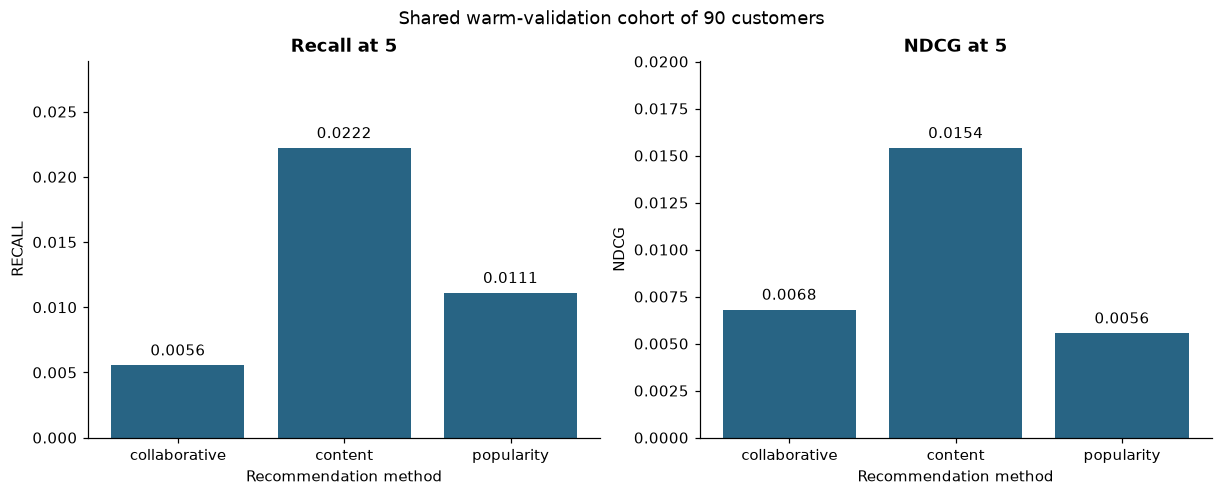

In [54]:
syllabus_ranking_rows = []
recommended_catalogs = {}

for method in ["popularity", "content", "collaborative"]:
    for k in [5, 10]:
        recommended_catalogs[(method, k)] = set()
        for user, relevant in sorted(relevance_by_user.items()):
            recommendations = recommend_syllabus(user, method=method, n=k)
            recommended = recommendations["product_id"].tolist()
            row = {"method": method, "k": k, "user": user}
            row.update(top_k_metrics(recommended, relevant, k))
            row["fallback_item_fraction"] = float(recommendations["popularity_fallback"].sum() / k)
            row["full_list_fallback"] = float(recommendations["popularity_fallback"].all())
            syllabus_ranking_rows.append(row)
            recommended_catalogs[(method, k)].update(recommended)

syllabus_ranking_user_results = pd.DataFrame(syllabus_ranking_rows)
syllabus_ranking_results = syllabus_ranking_user_results.groupby(["method", "k"]).agg(
    users=("user", "nunique"),
    precision=("precision", "mean"),
    recall=("recall", "mean"),
    ndcg=("ndcg", "mean"),
    hit_rate=("hit_rate", "mean"),
    fallback_item_fraction=("fallback_item_fraction", "mean"),
    full_list_fallback=("full_list_fallback", "mean"),
).reset_index()
syllabus_ranking_results["catalog_coverage"] = [
    len(recommended_catalogs[(row.method, row.k)]) / len(rec_item_ids)
    for row in syllabus_ranking_results.itertuples(index=False)
]

print(syllabus_ranking_results.round(6).to_string(index=False))
at_five = syllabus_ranking_results.loc[syllabus_ranking_results["k"].eq(5)]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), layout="constrained")
for ax, metric, title in zip(
    axes, ["recall", "ndcg"], ["Recall at 5", "NDCG at 5"]
):
    bars = ax.bar(at_five["method"], at_five[metric], color="#286484")
    ax.bar_label(bars, labels=[f"{value:.4f}" for value in at_five[metric]], padding=4)
    ax.set_ylim(0, max(0.02, at_five[metric].max() * 1.3))
    ax.set(title=title, xlabel="Recommendation method", ylabel=metric.upper())
fig.suptitle(f"Shared warm-validation cohort of {len(relevance_by_user)} customers")
plt.show()

### 8.5 New customers short histories and a metadata-only product

Exercise all methods for a new customer and a customer with one historical product. Both need valid unseen suggestions.

Create a clearly labeled simulated new product using a known category and an example price. Encode its metadata and compute its content similarity to a known customer's profile. This shows that content can score a candidate from attributes alone. The new ID has no collaborative interaction column, so collaborative scoring lacks evidence for it.

The fixture is separate from measured ranking evaluation. An application would need to publish and describe a new candidate before adding it to the available catalog.

In [55]:
single_history_position = int(np.flatnonzero(np.diff(interaction_matrix.indptr) == 1)[0])
single_history_user = rec_user_ids[single_history_position]
cold_start_rows = []

for user_label, user in [
    ("New customer", "__new_customer__"),
    ("One historical product", single_history_user),
]:
    for method in ["popularity", "content", "collaborative"]:
        recommendations = recommend_syllabus(user, method=method, n=5)
        cold_start_rows.append({
            "case": user_label,
            "method": method,
            "recommendations": len(recommendations),
            "popularity_fills": int(recommendations["popularity_fallback"].sum()),
        })
cold_start_summary = pd.DataFrame(cold_start_rows)

seed_item_position = int(interaction_matrix.getrow(single_history_position).indices[0])
new_product_metadata = pd.DataFrame({
    "category_label": [content_catalog.iloc[seed_item_position]["category_label"]],
    "historical_price": [content_catalog.iloc[seed_item_position]["historical_price"]],
}, index=["__simulated_new_item__"])
new_product_vector = encode_additional_content(new_product_metadata)
single_profile = normalize(
    interaction_matrix.getrow(single_history_position) @ content_item_vectors, norm="l2"
)
new_product_content_score = float((single_profile @ new_product_vector.T).toarray()[0, 0])

print(cold_start_summary.to_string(index=False))
print()
print("Simulated metadata-only product, outside benchmark candidates:")
print(f"Content score from the customer's profile: {new_product_content_score:.6f}")
print("Collaborative interaction column exists:", "__simulated_new_item__" in rec_item_ids)
print()
print("Readable content recommendations for the one-history customer:")
print(recommend_syllabus(single_history_user, method="content", n=5).to_string(index=False))

                  case        method  recommendations  popularity_fills
          New customer    popularity                5                 0
          New customer       content                5                 5
          New customer collaborative                5                 5
One historical product    popularity                5                 0
One historical product       content                5                 0
One historical product collaborative                5                 5

Simulated metadata-only product, outside benchmark candidates:
Content score from the customer's profile: 1.000000
Collaborative interaction column exists: False

Readable content recommendations for the one-history customer:
                      product_id   category  historical_price  model_score  popularity_fallback                                        reason
d189fbf8b5d79a670cebcaaad68d77b2 stationery             59.90          1.0                False Category and historical price-b

### 8.6 Work through one content cosine similarity

Pick two historical candidates with the same category and different price bands. Category agreement contributes 2 times 2 to the dot product. The unmatched price-band coordinates contribute zero.

Both raw vectors have length square root of five, giving similarity 4 / 5 = 0.8. Compare this calculation with the dot product of the normalized encoded vectors.

In [56]:
content_example_seed = 0
seed_category = content_fields.iloc[content_example_seed]["category_label"]
seed_band = content_fields.iloc[content_example_seed]["price_band"]
content_example_candidates = np.flatnonzero(
    content_fields["category_label"].eq(seed_category).to_numpy()
    & content_fields["price_band"].ne(seed_band).to_numpy()
)
assert len(content_example_candidates) > 0
content_example_target = int(content_example_candidates[0])

category_matches = content_fields.iloc[content_example_seed]["category_label"] == content_fields.iloc[content_example_target]["category_label"]
band_matches = content_fields.iloc[content_example_seed]["price_band"] == content_fields.iloc[content_example_target]["price_band"]
manual_content_cosine = (4 * int(category_matches) + int(band_matches)) / 5
encoded_content_cosine = float(
    (content_item_vectors.getrow(content_example_seed) @
     content_item_vectors.getrow(content_example_target).T).toarray()[0, 0]
)

content_worked_example = content_catalog.iloc[
    [content_example_seed, content_example_target]
].copy()
content_worked_example["price_band"] = content_fields.iloc[
    [content_example_seed, content_example_target]
]["price_band"]
print(content_worked_example.to_string())
print(f"Manual cosine: {manual_content_cosine:.6f}")
print(f"Encoded-vector cosine: {encoded_content_cosine:.6f}")

                                 category_label  historical_price    price_band
00088930e925c41fd95ebfe695fd2655           auto             129.9  price_band_3
0011c512eb256aa0dbbb544d8dffcf6e           auto              52.0  price_band_2
Manual cosine: 0.800000
Encoded-vector cosine: 0.800000


### 8.7 Work through an implicit collaborative score

Choose a retained item-neighbor link and a historical customer who bought its source product without buying the candidate. This is a teaching example selected independently of future relevance.

For each of that customer's historical products, calculate shared buyers divided by the square root of the product of buyer counts. If neighbor pruning discarded a link, its contribution to the model score is zero. Sum retained contributions and compare with the implemented customer-candidate score.

A high cosine based on very few shared buyers is weak support. These scores describe observed purchase patterns rather than calibrated purchase probability.

In [57]:
interaction_columns = interaction_matrix.tocsc()
similarity_sources, similarity_targets = item_similarity.nonzero()
collaborative_example = None

for source_index, target_index in zip(similarity_sources, similarity_targets):
    source_users = set(interaction_columns.getcol(source_index).nonzero()[0])
    target_users = set(interaction_columns.getcol(target_index).nonzero()[0])
    eligible_example_users = sorted(source_users - target_users)
    if eligible_example_users:
        collaborative_example = (
            eligible_example_users[0], int(source_index), int(target_index)
        )
        break
assert collaborative_example is not None

worked_user_position, worked_source_position, worked_candidate_position = collaborative_example
worked_user = rec_user_ids[worked_user_position]
worked_history_positions = interaction_matrix.getrow(worked_user_position).indices
collaborative_contributions = []

for source_position in worked_history_positions:
    source_column = interaction_columns.getcol(source_position)
    target_column = interaction_columns.getcol(worked_candidate_position)
    shared_buyers = int(source_column.multiply(target_column).sum())
    source_buyers = int(source_column.sum())
    candidate_buyers = int(target_column.sum())
    cosine = shared_buyers / np.sqrt(source_buyers * candidate_buyers)
    retained = float(item_similarity[source_position, worked_candidate_position])
    collaborative_contributions.append({
        "historical_product": rec_item_ids[source_position],
        "shared_buyers": shared_buyers,
        "source_buyers": source_buyers,
        "candidate_buyers": candidate_buyers,
        "manual_cosine": cosine,
        "retained_contribution": retained,
    })

collaborative_worked_example = pd.DataFrame(collaborative_contributions)
manual_collaborative_score = float(collaborative_worked_example["retained_contribution"].sum())
implemented_collaborative_score = float(
    raw_recommendation_scores(worked_user, "collaborative")[worked_candidate_position]
)
print("Worked candidate:", rec_item_ids[worked_candidate_position])
print(collaborative_worked_example.round(6).to_string(index=False))
print(f"Manual sum of retained similarities: {manual_collaborative_score:.6f}")
print(f"Implemented score: {implemented_collaborative_score:.6f}")

Worked candidate: e19ddcc85537b41f22116c8d5425ef46
              historical_product  shared_buyers  source_buyers  candidate_buyers  manual_cosine  retained_contribution
001b72dfd63e9833e8c02742adf472e3              1             12                18       0.068041               0.068041
Manual sum of retained similarities: 0.068041
Implemented score: 0.068041


In [58]:
assert interaction_matrix.nnz == len(training_pairs)
assert np.all(interaction_matrix.data == 1)
assert interaction_matrix.shape == (len(rec_user_ids), len(rec_item_ids))
assert price_history_events["order_purchase_timestamp"].lt(ranking_validation["cutoff"]).all()
assert content_catalog["historical_price"].notna().all()
assert (content_catalog["historical_price"] > 0).all()
assert set(historical_item_prices.index) == set(rec_item_ids)
assert set(content_encoder.categories_[0]) == set(content_fields["category_label"])
assert set(content_encoder.categories_[1]) == set(content_fields["price_band"])
np.testing.assert_allclose(
    np.asarray(content_item_vectors.multiply(content_item_vectors).sum(axis=1)).ravel(), 1
)
assert not item_similarity.diagonal().any()
assert np.isfinite(item_similarity.data).all()
assert ((item_similarity.data > 0) & (item_similarity.data <= 1 + 1e-12)).all()
assert np.diff(item_similarity.indptr).max() <= ITEM_NEIGHBORS
assert np.isclose(manual_content_cosine, encoded_content_cosine)
assert np.isclose(manual_content_cosine, 0.8)
assert np.isclose(manual_collaborative_score, implemented_collaborative_score)

retained_rows = collaborative_worked_example["retained_contribution"] > 0
np.testing.assert_allclose(
    collaborative_worked_example.loc[retained_rows, "manual_cosine"],
    collaborative_worked_example.loc[retained_rows, "retained_contribution"],
)

for user in relevance_by_user:
    for method in ["popularity", "content", "collaborative"]:
        recommendations = recommend_syllabus(user, method=method, n=10)
        assert recommendations["product_id"].is_unique
        assert recommendations["product_id"].isin(rec_item_ids).all()
        assert set(recommendations["product_id"]).isdisjoint(seen_products_by_user[user])
        assert recommendations["category"].notna().all()
        if method == "popularity":
            assert recommendations["product_id"].tolist() == recommend_popular(user, 10)["product_id"].tolist()

for k in [5, 10]:
    original = popularity_baseline_results.set_index("k").loc[k]
    repeated = syllabus_ranking_results.loc[
        syllabus_ranking_results["method"].eq("popularity")
        & syllabus_ranking_results["k"].eq(k)
    ].iloc[0]
    for metric in ["precision", "recall", "ndcg", "hit_rate"]:
        assert np.isclose(original[metric], repeated[metric])
assert cold_start_summary["recommendations"].eq(5).all()
assert cold_start_summary.loc[
    cold_start_summary["case"].eq("New customer")
    & cold_start_summary["method"].ne("popularity"), "popularity_fills"
].eq(5).all()
assert "__simulated_new_item__" not in rec_item_ids
assert np.isfinite(new_product_content_score) and new_product_content_score > 0
assert set(syllabus_ranking_results["users"]) == {len(relevance_by_user)}
assert len(syllabus_ranking_results) == 6
print("Historical fitting, sparse matrices, ranking parity, seen-item exclusion, cold-start and worked-score checks passed.")
print("Final recommendation test performance remains reserved for the locked comparison.")

Historical fitting, sparse matrices, ranking parity, seen-item exclusion, cold-start and worked-score checks passed.
Final recommendation test performance remains reserved for the locked comparison.


### 8.8 Validation findings and interpretation

| Method | Recall at 5 | NDCG at 5 | Recall at 10 | NDCG at 10 |
|---|---|---|---|---|
| Popularity | 0.011111 | 0.005556 | 0.022222 | 0.009061 |
| Content | 0.022222 | 0.015409 | 0.033333 | 0.018621 |
| Item collaborative | 0.005556 | 0.006813 | 0.016667 | 0.010318 |

Content leads these particular validation comparisons. Only two of 90 customers receive a relevant content recommendation in the top five, versus one for each other method. This small cohort and low absolute quality limit the strength of the comparison.

Collaborative filtering fills 77.11 percent of top-five positions from popularity, and 61.11 percent of customers receive an entirely fallback list. Content needs no zero-score fallback here, but coarse metadata creates many ties resolved by historical popularity. Catalog coverage at five is 1.1235 percent for content, 0.4311 percent for collaborative, and 0.0261 percent for popularity. Coverage measures recommendation diversity across this cohort, rather than purchase accuracy.

The category weight of two, price-band weight of one, and twenty retained neighbors per source item are fixed teaching configurations. They have not been established as optimal. The simulated new product demonstrates metadata scoring separately from the historical candidate benchmark. Product availability is unknown in this static dataset. Final test scores remain reserved until model choices are locked.


## 9 Naive Bayes and linear SVM for repeat purchases

Unit III compares probabilistic classification and maximum-margin classification. Keep the existing train/validation customers and historical target. Fit preprocessing only on training rows. Reserve test scoring.

Gaussian Naive Bayes uses the eleven numeric features with training-median imputation, without state or missingness indicator coordinates. It assumes conditionally independent Gaussian features within each class. Counts, ratios and correlated spending/history features violate that approximation, so this is an explicitly limited course comparison. It avoids treating one-hot state coordinates as Gaussian measurements. Compare models as complete pipelines, acknowledging the different representations.

Linear SVM uses the same scaled numeric and encoded-state representation as Logistic Regression. Use LinearSVC with C=1, once with ordinary class weights and once with balanced training-class weights. This is a small declared comparison, rather than a hyperparameter search. A linear boundary keeps margin and coefficients understandable. Nonlinear kernels remain a theory discussion for now.

In [59]:
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC
from sklearn.exceptions import ConvergenceWarning
import warnings

bayes_numeric_preprocessing = Pipeline([
    ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
])
unit_three_models = {
    "Gaussian NB numeric": Pipeline([
        ("preprocessing", bayes_numeric_preprocessing),
        ("classifier", GaussianNB(var_smoothing=1e-9)),
    ]),
    "Linear SVM": Pipeline([
        ("preprocessing", clone(retention_preprocessing)),
        ("classifier", LinearSVC(C=1.0, dual="auto", max_iter=20000,
                                  random_state=42)),
    ]),
    "Linear SVM balanced": Pipeline([
        ("preprocessing", clone(retention_preprocessing)),
        ("classifier", LinearSVC(C=1.0, class_weight="balanced", dual="auto",
                                  max_iter=20000, random_state=42)),
    ]),
}
unit_three_inputs = {}
for name, model in unit_three_models.items():
    train_input = X_train[RETENTION_NUMERIC_FEATURES] if name.startswith("Gaussian") else X_train
    validation_input = X_validation[RETENTION_NUMERIC_FEATURES] if name.startswith("Gaussian") else X_validation
    unit_three_inputs[name] = (train_input, validation_input)
    with warnings.catch_warnings():
        warnings.simplefilter("error", ConvergenceWarning)
        model.fit(train_input, y_train)
print("Fitted three training-only pipelines without convergence warnings.")

Fitted three training-only pipelines without convergence warnings.


### 9.1 Compare ranking scores and native decisions

Naive Bayes returns estimated class probabilities and uses its native class decision, normally equivalent to a 0.5 threshold for two classes. LinearSVC returns a signed decision score. Positive scores predict repeat, using the zero boundary. SVM scores are not probabilities. AP and ROC-AUC accept either type of ranking score.

Use native decisions for precision, recall, F1 and confusion counts. Class balancing weights rare training examples more heavily and may increase recall and false positives. It does not create new evidence or guarantee better ranking. Accuracy alone hides rare repeat events.

              model  training_average_precision  average_precision  roc_auc  precision   recall       f1  predicted_positives    tn   fp  fn  tp  decision_boundary
Gaussian NB numeric                    0.014551           0.013115 0.528977   0.023936 0.092784 0.038055                  376 11304  367  88   9                0.5
         Linear SVM                    0.023872           0.010308 0.512059   0.000000 0.000000 0.000000                    0 11671    0  97   0                0.0
Linear SVM balanced                    0.019595           0.010450 0.523457   0.008566 0.443299 0.016807                 5020  6694 4977  54  43                0.0
Validation customers: 11768 actual repeats: 97
Prior AP reference: 0.008243


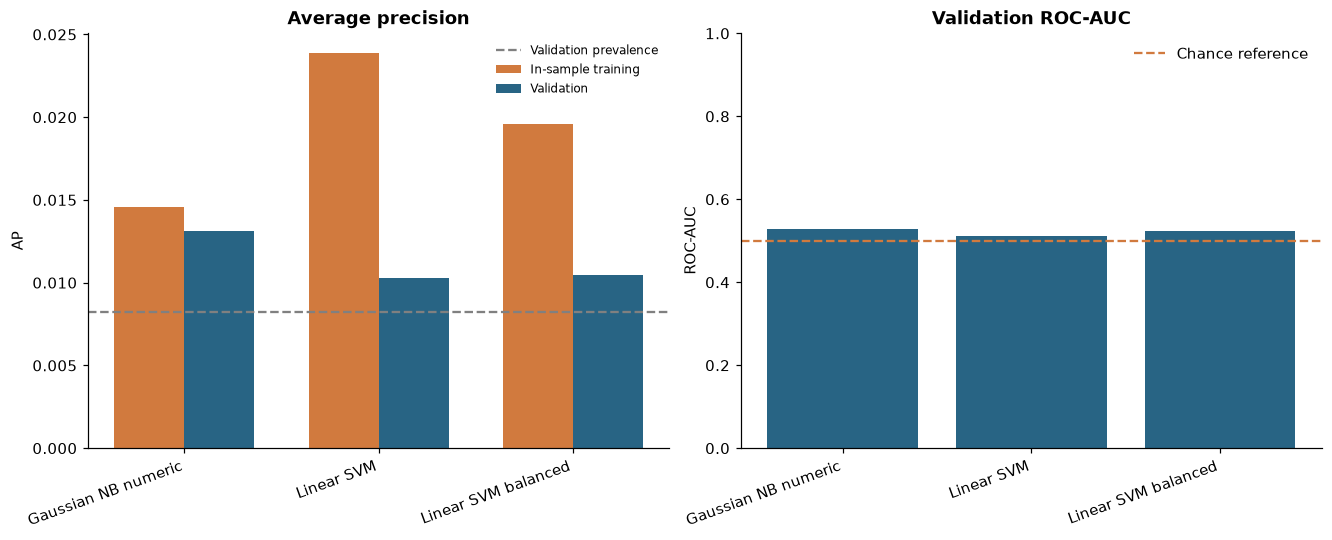

In [60]:
unit_three_scores = {}
unit_three_predictions = {}
unit_three_rows = []
for name, model in unit_three_models.items():
    train_input, validation_input = unit_three_inputs[name]
    is_bayes = name.startswith("Gaussian")
    train_score = model.predict_proba(train_input)[:, 1] if is_bayes else model.decision_function(train_input)
    validation_score = model.predict_proba(validation_input)[:, 1] if is_bayes else model.decision_function(validation_input)
    prediction = model.predict(validation_input)
    unit_three_scores[name] = validation_score
    unit_three_predictions[name] = prediction
    tn, fp, fn, tp = confusion_matrix(y_validation, prediction, labels=[0, 1]).ravel()
    unit_three_rows.append({
        "model": name,
        "training_average_precision": average_precision_score(y_train, train_score),
        "average_precision": average_precision_score(y_validation, validation_score),
        "roc_auc": roc_auc_score(y_validation, validation_score),
        "precision": precision_score(y_validation, prediction, zero_division=0),
        "recall": recall_score(y_validation, prediction, zero_division=0),
        "f1": f1_score(y_validation, prediction, zero_division=0),
        "predicted_positives": int(prediction.sum()),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
        "decision_boundary": 0.5 if is_bayes else 0.0,
    })
unit_three_results = pd.DataFrame(unit_three_rows)
print(unit_three_results.round(6).to_string(index=False))
print("Validation customers:", len(y_validation), "actual repeats:", int(y_validation.sum()))
print("Prior AP reference:", round(float(y_validation.mean()), 6))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained")
x = np.arange(len(unit_three_results))
axes[0].bar(x - .18, unit_three_results.training_average_precision, width=.36, label="In-sample training", color="#d17a3e")
axes[0].bar(x + .18, unit_three_results.average_precision, width=.36, label="Validation", color="#286484")
axes[0].axhline(y_validation.mean(), color="grey", linestyle="--", label="Validation prevalence")
axes[0].set(title="Average precision", ylabel="AP")
axes[0].legend(frameon=False, fontsize=8)
axes[1].bar(x, unit_three_results.roc_auc, color="#286484")
axes[1].axhline(.5, color="#d17a3e", linestyle="--", label="Chance reference")
axes[1].set(title="Validation ROC-AUC", ylabel="ROC-AUC", ylim=(0, 1))
axes[1].legend(frameon=False)
for ax in axes:
    ax.set_xticks(x, labels=unit_three_results.model, rotation=20, ha="right")
plt.show()

### 9.2 Calculate one Naive Bayes prediction

Bayes combines the training class prior and feature likelihoods. For each class c, compute `log P(c) + sum_j log Normal(x_j; mean_cj, variance_cj)`. Subtract the log-sum-exp across classes before exponentiating to recover normalized probabilities. Log arithmetic avoids multiplying many tiny densities. GaussianNB adds a small variance smoothing term for numerical stability.

Use the validation row with the highest estimated repeat probability as a reproducible worked example, not an independent evaluation or proof of success. Show each numeric feature's contribution to the repeat-versus-nonrepeat log odds. Correlated features can effectively count similar evidence more than once.

In [61]:
from scipy.special import logsumexp
bayes_pipeline = unit_three_models["Gaussian NB numeric"]
bayes_estimator = bayes_pipeline.named_steps["classifier"]
bayes_worked_position = int(np.argmax(unit_three_scores["Gaussian NB numeric"]))
bayes_query = bayes_pipeline.named_steps["preprocessing"].transform(
    X_validation[RETENTION_NUMERIC_FEATURES].iloc[[bayes_worked_position]]
)[0]
gaussian_log_density = -.5 * (
    np.log(2 * np.pi * bayes_estimator.var_)
    + (bayes_query - bayes_estimator.theta_) ** 2 / bayes_estimator.var_
)
bayes_joint_log = np.log(bayes_estimator.class_prior_) + gaussian_log_density.sum(axis=1)
bayes_manual_probability = np.exp(bayes_joint_log - logsumexp(bayes_joint_log))
bayes_library_probability = bayes_pipeline.predict_proba(
    X_validation[RETENTION_NUMERIC_FEATURES].iloc[[bayes_worked_position]]
)[0]
bayes_feature_contributions = pd.DataFrame({
    "feature": RETENTION_NUMERIC_FEATURES,
    "imputed_value": bayes_query,
    "log_likelihood_ratio_repeat": gaussian_log_density[1] - gaussian_log_density[0],
})
print(bayes_feature_contributions.round(6).to_string(index=False))
print("Training class priors:", bayes_estimator.class_prior_)
print("Manual class probabilities:", bayes_manual_probability)
print("Library class probabilities:", bayes_library_probability)
print("Actual repeat label:", int(y_validation.iloc[bayes_worked_position]))

                  feature  imputed_value  log_likelihood_ratio_repeat
             recency_days      26.001644                     2.085005
   historical_order_count       2.000000                    12.067656
        distinct_products       2.000000                     2.804826
         distinct_sellers       2.000000                    17.736906
  log1p_merchandise_spend       5.627261                     0.261433
log1p_average_order_value       4.937706                     0.105987
            freight_ratio       0.287071                     0.435112
       known_review_count       2.000000                     1.539408
  mean_known_review_score       5.000000                     0.121057
     known_delivery_count       2.000000                     2.428160
 mean_known_delivery_days      10.013015                    -0.065641
Training class priors: [0.99025205 0.00974795]
Manual class probabilities: [6.97516269e-16 1.00000000e+00]
Library class probabilities: [6.97516269e-16 1.000000

### 9.3 Calculate one SVM decision

A linear SVM scores the transformed row as `w dot x + b`. The sign determines the predicted class. LinearSVC uses a regularized squared-hinge objective by default. C controls the penalty for training errors relative to regularization. Larger C penalizes errors more strongly. Standardizing numeric features makes the geometry meaningful relative to their units.

For the balanced model, the training weight for class c is `n / (2 * count_c)`. These weights enter training, rather than post-hoc score multiplication. Show the highest-scored validation customer's transformed feature contributions and the fitted score. A decision score is not a probability. The normalized score `score / ||w||` gives signed distance to this fitted hyperplane in transformed feature space.

In [62]:
svm_pipeline = unit_three_models["Linear SVM balanced"]
svm_estimator = svm_pipeline.named_steps["classifier"]
svm_worked_position = int(np.argmax(unit_three_scores["Linear SVM balanced"]))
svm_query = svm_pipeline.named_steps["preprocessing"].transform(X_validation.iloc[[svm_worked_position]])
svm_query_values = svm_query.toarray().ravel() if sparse.issparse(svm_query) else svm_query.ravel()
svm_weights = svm_estimator.coef_.ravel()
svm_manual_score = float(svm_query_values @ svm_weights + svm_estimator.intercept_[0])
svm_library_score = float(svm_pipeline.decision_function(X_validation.iloc[[svm_worked_position]])[0])
svm_feature_contributions = pd.DataFrame({
    "feature": svm_pipeline.named_steps["preprocessing"].get_feature_names_out(),
    "scaled_or_encoded_value": svm_query_values,
    "weight": svm_weights,
    "contribution": svm_query_values * svm_weights,
})
svm_feature_contributions = svm_feature_contributions.iloc[
    np.argsort(-np.abs(svm_feature_contributions.contribution.to_numpy()))
]
training_class_counts = y_train.value_counts().sort_index()
svm_balanced_weights = len(y_train) / (2 * training_class_counts)
print(svm_feature_contributions.head(10).round(6).to_string(index=False))
print("Intercept:", float(svm_estimator.intercept_[0]))
print("Manual and library score:", svm_manual_score, svm_library_score)
print("Signed hyperplane distance:", svm_manual_score / np.linalg.norm(svm_weights))
print("Training balanced weights:", svm_balanced_weights.to_dict())
print("Actual repeat label:", int(y_validation.iloc[svm_worked_position]))

                                           feature  scaled_or_encoded_value    weight  contribution
                  numeric__log1p_merchandise_spend                 1.358670  3.139914      4.266108
                numeric__log1p_average_order_value                 0.653458 -3.100753     -2.026211
                   numeric__historical_order_count                 6.118233 -0.227326     -1.390836
                    categorical__customer_state_PE                 1.000000  0.688301      0.688301
                       numeric__known_review_count                 3.408505 -0.093532     -0.318805
                     numeric__known_delivery_count                 3.602072  0.069713      0.251113
                            numeric__freight_ratio                -0.386652 -0.110495      0.042723
                 numeric__mean_known_delivery_days                 1.311188  0.032390      0.042470
 numeric__missingindicator_mean_known_review_score                -0.293772 -0.140212      0.041190


### 9.4 Verify learning and evaluation boundaries

Check training medians and class counts independently. Verify both manual predictions, finite scores, confusion-count totals, and SVM zero-boundary decisions. Treat convergence warnings as errors during fitting. No test performance or validation-driven threshold selection is included in this topic.

In [63]:
assert len(unit_three_results) == 3
for name, model in unit_three_models.items():
    preprocessing = model.named_steps["preprocessing"]
    if name.startswith("Gaussian"):
        imputer = preprocessing.named_steps["imputer"]
        np.testing.assert_allclose(model.named_steps["classifier"].class_count_, training_class_counts.to_numpy())
        assert (model.named_steps["classifier"].var_ > 0).all()
    else:
        imputer = preprocessing.named_transformers_["numeric"].named_steps["imputer"]
        scaler = preprocessing.named_transformers_["numeric"].named_steps["scaler"]
        assert int(scaler.n_samples_seen_) == len(X_train)
        encoder = preprocessing.named_transformers_["categorical"].named_steps["encoder"]
        assert set(encoder.categories_[0]) == set(X_train["customer_state"])
        np.testing.assert_array_equal(unit_three_predictions[name], (unit_three_scores[name] > 0).astype(int))
        assert np.all(model.named_steps["classifier"].n_iter_ < 20000)
    np.testing.assert_allclose(imputer.statistics_, X_train[RETENTION_NUMERIC_FEATURES].median().to_numpy())
    assert np.isfinite(unit_three_scores[name]).all()
    assert len(unit_three_scores[name]) == len(y_validation)
    result_row = unit_three_results.loc[unit_three_results.model.eq(name)].iloc[0]
    assert result_row[["tn", "fp", "fn", "tp"]].sum() == len(y_validation)
    assert result_row.fn + result_row.tp == int(y_validation.sum())
np.testing.assert_allclose(bayes_manual_probability, bayes_library_probability, rtol=1e-10, atol=1e-12)
assert np.isclose(bayes_manual_probability.sum(), 1)
assert np.isclose(svm_manual_score, svm_library_score)
assert np.isclose(svm_feature_contributions.contribution.sum() + svm_estimator.intercept_[0], svm_library_score)
assert np.isclose(svm_balanced_weights.loc[0] * training_class_counts.loc[0], len(y_train)/2)
assert np.isclose(svm_balanced_weights.loc[1] * training_class_counts.loc[1], len(y_train)/2)
print("Training preprocessing, class counts, native decisions, confusion totals and manual Bayes/SVM calculations passed.")
print("Final test scoring remains reserved.")

Training preprocessing, class counts, native decisions, confusion totals and manual Bayes/SVM calculations passed.
Final test scoring remains reserved.


### 9.5 Results and limitations

| Model | Validation AP | ROC-AUC | Precision | Recall | True positives | False positives |
|---|---|---|---|---|---|---|
| Gaussian NB numeric | 0.013115 | 0.528977 | 0.023936 | 0.092784 | 9 | 367 |
| Linear SVM | 0.010308 | 0.512059 | 0 | 0 | 0 | 0 |
| Linear SVM balanced | 0.010450 | 0.523457 | 0.008566 | 0.443299 | 43 | 4977 |

All results use 11,768 validation customers with 97 actual repeats. The prior AP reference is 0.008243. Earlier Logistic Regression AP is 0.016882. None of these new configurations exceeds that baseline AP. A slightly higher ROC-AUC does not imply better positive-class precision or useful decisions.

Ordinary SVM predicts no repeats at its zero score boundary. Balancing raises recall but flags 5,020 customers, with 4,977 false positives. GaussianNB predicts 376 repeats, of which nine are correct. The worked Bayes example is almost completely confident about repeat for an actual nonrepeat customer. Correlated counts and imperfect Gaussian assumptions illustrate why such probabilities need scrutiny. Correct score arithmetic does not guarantee predictive quality or calibration.

Training has 140 repeats and 14,222 nonrepeats. Balanced SVM weights each repeat row about 51.2929 and each nonrepeat row about 0.5049. The worked SVM score is 1.196948, matching the manual weighted sum, with signed transformed-space distance 0.214712. Its selected actual label is also nonrepeat. These selected examples explain arithmetic and are not representative performance estimates.

Keep all configurations as course comparisons, with no production selection claim. Final test scoring remains reserved. Random Forest is the next core ensemble comparison. Model selection, threshold policy and application behavior follow the remaining comparisons.


## 10 Random Forest for repeat-purchase prediction

Unit V combines many trees using bootstrap sampling and random feature subsets. Each tree learns from a training sample drawn with replacement. At each split, a random subset of transformed features is considered. These sources of diversity reduce reliance on a single tree. Averaging correlated trees cannot remove all bias, leakage or weak input signals.

Compare three declared configurations on the existing chronological validation cohort. All use 200 trees, entropy, bootstrap samples of training size, square-root feature sampling and a minimum of 20 distinct samples per leaf. Compare ordinary and balanced-subsample weighting at depth six, then increase only the balanced forest's maximum depth to twelve. This is a small comparison rather than exhaustive tuning.

Reuse the tree preprocessing pipeline with training-median imputation, missingness indicators and state one-hot encoding. Numeric scaling is bypassed because ordered tree splits do not require standardized units. Preprocessing remains fitted only on training rows. Final test scoring is reserved.

In [64]:
from sklearn.ensemble import RandomForestClassifier

forest_configurations = {
    "RF ordinary depth=6": {"max_depth": 6, "class_weight": None},
    "RF balanced depth=6": {"max_depth": 6, "class_weight": "balanced_subsample"},
    "RF balanced depth=12": {"max_depth": 12, "class_weight": "balanced_subsample"},
}
forest_models = {}
for name, configuration in forest_configurations.items():
    forest_models[name] = Pipeline([
        ("preprocessing", clone(tree_preprocessing)),
        ("classifier", RandomForestClassifier(
            n_estimators=200, criterion="entropy", min_samples_leaf=20,
            max_features="sqrt", bootstrap=True, random_state=42, n_jobs=2,
            **configuration,
        )),
    ])
    forest_models[name].fit(X_train, y_train)
print("Fitted three training-only forests with 200 trees each.")
print("Fixed settings: entropy, bootstrap, sqrt feature sampling, leaf minimum 20.")

Fitted three training-only forests with 200 trees each.
Fixed settings: entropy, bootstrap, sqrt feature sampling, leaf minimum 20.


### 10.1 Evaluate ranking and threshold decisions

Use the same classification metrics and validation customers as the preceding models. Forest probability is the mean of individual trees' repeat-class probabilities. It is not generally a majority vote of hard tree labels. Compare training AP with validation AP to expose fitting gaps. Evaluate a fixed 0.5 decision boundary without choosing a threshold on the test set.

With `balanced_subsample`, inverse-frequency class weights are recomputed within each tree's bootstrap sample. Weighted leaf class proportions can improve sensitivity, but these output probabilities need not be calibrated to natural repeat prevalence. Increasing maximum depth changes capacity while the leaf minimum remains fixed.

               model  average_precision  roc_auc  precision_at_0_5  recall_at_0_5  f1_at_0_5  predicted_positives  training_average_precision    tn   fp  fn  tp  mean_tree_depth
 RF ordinary depth=6           0.012924 0.524081          0.000000       0.000000    0.00000                    0                    0.071150 11671    0  97   0            6.000
 RF balanced depth=6           0.010549 0.515613          0.011155       0.144330    0.02071                 1255                    0.093607 10430 1241  83  14            6.000
RF balanced depth=12           0.010312 0.515023          0.018421       0.072165    0.02935                  380                    0.228160 11298  373  90   7           11.995
Validation rows: 11768 repeat labels: 97
Prior AP reference: 0.008242692046227056
Earlier Logistic Regression validation AP: 0.016882029914493026


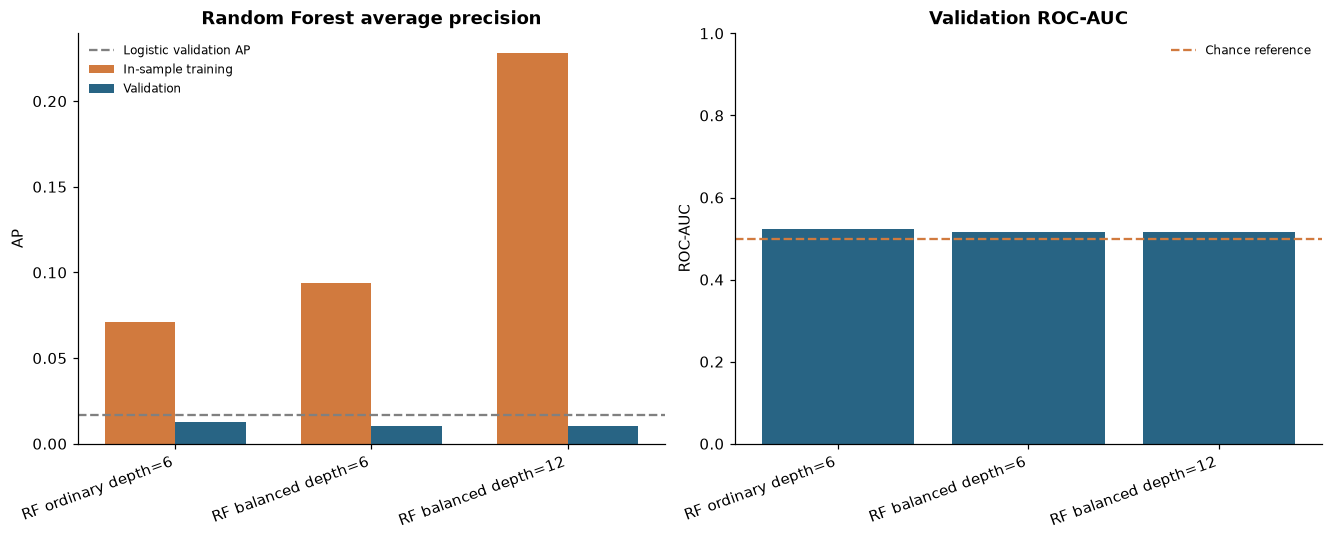

In [65]:
forest_validation_probabilities = {}
forest_rows = []
for name, pipeline in forest_models.items():
    train_probability = pipeline.predict_proba(X_train)[:, 1]
    probability = pipeline.predict_proba(X_validation)[:, 1]
    forest_validation_probabilities[name] = probability
    row = repeat_classification_metrics(name, y_validation, probability)
    row["training_average_precision"] = average_precision_score(y_train, train_probability)
    tn, fp, fn, tp = confusion_matrix(y_validation, probability >= .5, labels=[0, 1]).ravel()
    row.update(tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))
    row["mean_tree_depth"] = np.mean([tree.get_depth() for tree in pipeline.named_steps["classifier"].estimators_])
    forest_rows.append(row)
forest_results = pd.DataFrame(forest_rows)
print(forest_results.round(6).to_string(index=False))
print("Validation rows:", len(y_validation), "repeat labels:", int(y_validation.sum()))
forest_prior_reference = float(y_validation.mean())
forest_logistic_ap = float(retention_baseline_results.loc[
    retention_baseline_results.model.eq("Logistic Regression"), "average_precision"
].iloc[0])
print("Prior AP reference:", forest_prior_reference)
print("Earlier Logistic Regression validation AP:", forest_logistic_ap)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained")
x = np.arange(len(forest_results))
axes[0].bar(x-.18, forest_results.training_average_precision, .36, label="In-sample training", color="#d17a3e")
axes[0].bar(x+.18, forest_results.average_precision, .36, label="Validation", color="#286484")
axes[0].axhline(forest_logistic_ap, linestyle="--", color="grey", label="Logistic validation AP")
axes[0].set(title="Random Forest average precision", ylabel="AP")
axes[0].legend(frameon=False, fontsize=8)
axes[1].bar(x, forest_results.roc_auc, color="#286484")
axes[1].axhline(.5, linestyle="--", color="#d17a3e", label="Chance reference")
axes[1].set(title="Validation ROC-AUC", ylabel="ROC-AUC", ylim=(0, 1))
axes[1].legend(frameon=False, fontsize=8)
for ax in axes:
    ax.set_xticks(x, labels=forest_results.model, rotation=20, ha="right")
plt.show()

### 10.2 Inspect bootstrap diversity and calculate an ensemble prediction

Inspect the first three bootstrap samples of the balanced depth-six forest. Sampling with replacement produces duplicate training rows and leaves some rows out of each tree. The familiar roughly 63 percent unique-row figure is an expectation for a full-size bootstrap sample, rather than an enforced fraction. All sampled positions must refer to training rows.

For the highest-scored validation customer, obtain each tree's repeat-class probability, average all 200 values, and compare with the pipeline output. Display ten tree outputs for readability, but use every tree in the calculation. The example is selected to explain arithmetic, not estimate typical performance. Omitted training rows are not a substitute for chronological validation, and this section does not use out-of-bag scores for model selection.

In [66]:
forest_worked_pipeline = forest_models["RF balanced depth=6"]
forest_worked_estimator = forest_worked_pipeline.named_steps["classifier"]
forest_bootstrap_samples = forest_worked_estimator.estimators_samples_
forest_bootstrap_rows = []
for index, sample in enumerate(forest_bootstrap_samples[:3]):
    unique_rows = np.unique(sample)
    bootstrap_labels = y_train.iloc[sample]
    forest_bootstrap_rows.append({
        "tree": index + 1, "draws": len(sample),
        "unique_training_rows": len(unique_rows),
        "duplicate_draws": len(sample)-len(unique_rows),
        "omitted_training_rows": len(y_train)-len(unique_rows),
        "unique_fraction": len(unique_rows)/len(y_train),
        "repeat_draws": int(bootstrap_labels.sum()),
    })
forest_bootstrap_summary = pd.DataFrame(forest_bootstrap_rows)
forest_worked_position = int(np.argmax(forest_validation_probabilities["RF balanced depth=6"]))
forest_query = forest_worked_pipeline.named_steps["preprocessing"].transform(
    X_validation.iloc[[forest_worked_position]]
)
forest_tree_probabilities = np.array([
    tree.predict_proba(forest_query)[0, 1] for tree in forest_worked_estimator.estimators_
])
forest_manual_probability = float(forest_tree_probabilities.mean())
forest_library_probability = float(forest_worked_pipeline.predict_proba(
    X_validation.iloc[[forest_worked_position]]
)[0, 1])
forest_tree_example = pd.DataFrame({
    "tree": np.arange(1, 11), "repeat_probability": forest_tree_probabilities[:10],
    "hard_repeat_decision": forest_tree_probabilities[:10] >= .5,
})
print(forest_bootstrap_summary.round(6).to_string(index=False))
print("Theoretical expected unique fraction:", 1-(1-1/len(y_train))**len(y_train))
print("Features considered at each split:", forest_worked_estimator.estimators_[0].max_features_,
      "of", forest_query.shape[1])
print(forest_tree_example.round(6).to_string(index=False))
print("Manual mean over all 200 trees:", forest_manual_probability)
print("Pipeline repeat probability:", forest_library_probability)
print("Fraction of hard-positive trees:", float(np.mean(forest_tree_probabilities >= .5)))
print("Actual repeat label:", int(y_validation.iloc[forest_worked_position]))

 tree  draws  unique_training_rows  duplicate_draws  omitted_training_rows  unique_fraction  repeat_draws
    1  14362                  9065             5297                   5297         0.631180           151
    2  14362                  9042             5320                   5320         0.629578           123
    3  14362                  9154             5208                   5208         0.637376           129
Theoretical expected unique fraction: 0.632133366589197
Features considered at each split: 6 of 40
 tree  repeat_probability  hard_repeat_decision
    1            0.925280                  True
    2            0.918053                  True
    3            0.963143                  True
    4            0.865061                  True
    5            0.523607                  True
    6            0.899481                  True
    7            0.483128                 False
    8            0.727766                  True
    9            0.958573                  Tr

### 10.3 Read training-based feature importance carefully

Mean decrease in impurity summarizes how much training splits reduce weighted impurity, averaged across trees and normalized. Display the leading transformed features for the balanced depth-six forest. These values explain fitted split usage. They do not measure causal effects or independently establish predictive value.

Impurity importance can favor features with many possible split points. Correlated recency, frequency and spending features may share or exchange importance. State one-hot columns describe individual states, not one grouped state importance. The choice of weighting and depth also affects the values. Holdout ranking metrics remain the evidence for predictive quality. This is a course-level inspection rather than advanced explainability tooling.

                           feature  impurity_importance
            numeric__freight_ratio             0.194616
  numeric__log1p_merchandise_spend             0.153516
numeric__log1p_average_order_value             0.152929
 numeric__mean_known_delivery_days             0.121543
  numeric__mean_known_review_score             0.054644
    categorical__customer_state_SC             0.037422
     numeric__known_delivery_count             0.033934
    categorical__customer_state_ES             0.028051
   numeric__historical_order_count             0.026331
       numeric__known_review_count             0.023136
Importance sum: 0.9999999999999999


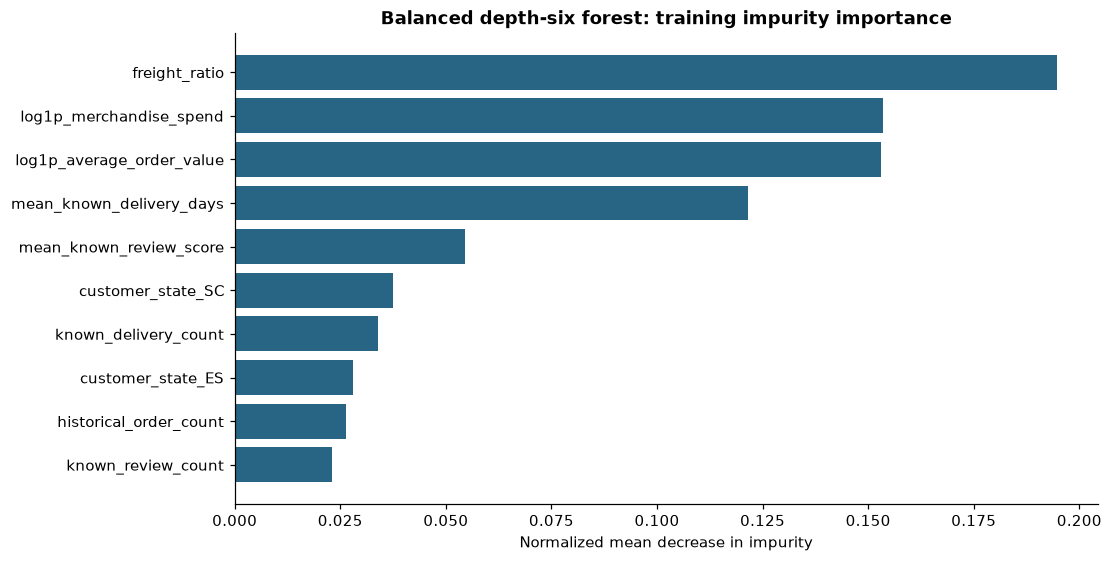

In [67]:
forest_feature_names = forest_worked_pipeline.named_steps["preprocessing"].get_feature_names_out()
forest_importance = pd.DataFrame({
    "feature": forest_feature_names,
    "impurity_importance": forest_worked_estimator.feature_importances_,
}).sort_values("impurity_importance", ascending=False).reset_index(drop=True)
print(forest_importance.head(10).round(6).to_string(index=False))
print("Importance sum:", float(forest_importance.impurity_importance.sum()))
top_forest_importance = forest_importance.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
ax.barh(top_forest_importance.feature.str.replace("numeric__", "", regex=False).str.replace("categorical__", "", regex=False),
        top_forest_importance.impurity_importance, color="#286484")
ax.set(title="Balanced depth-six forest: training impurity importance",
       xlabel="Normalized mean decrease in impurity")
plt.show()

### 10.4 Verify fitted structure and worked calculations

Check training-only preprocessing, fixed configuration, tree depth and leaf constraints, bootstrap positions and root sample counts. Confirm finite bounded probabilities, correct confusion totals and agreement between manual averaging and pipeline output. These checks verify implementation; validation metrics assess usefulness. Final test scoring remains reserved.

In [68]:
assert len(forest_models) == len(forest_results) == 3
for name, pipeline in forest_models.items():
    preprocessor = pipeline.named_steps["preprocessing"]
    numeric = preprocessor.named_transformers_["numeric"]
    assert numeric.named_steps["scaler"] == "passthrough"
    np.testing.assert_allclose(numeric.named_steps["imputer"].statistics_,
                               X_train[RETENTION_NUMERIC_FEATURES].median().to_numpy())
    encoder = preprocessor.named_transformers_["categorical"].named_steps["encoder"]
    assert set(encoder.categories_[0]) == set(X_train["customer_state"])
    estimator = pipeline.named_steps["classifier"]
    assert len(estimator.estimators_) == 200
    assert estimator.bootstrap and estimator.max_features == "sqrt"
    assert estimator.min_samples_leaf == 20
    assert estimator.class_weight == forest_configurations[name]["class_weight"]
    for tree in estimator.estimators_:
        assert tree.get_depth() <= forest_configurations[name]["max_depth"]
        leaves = tree.tree_.children_left == -1
        assert (tree.tree_.n_node_samples[leaves] >= 20).all()
    probability = forest_validation_probabilities[name]
    assert len(probability) == len(y_validation)
    assert np.isfinite(probability).all() and ((probability >= 0) & (probability <= 1)).all()
    row = forest_results.loc[forest_results.model.eq(name)].iloc[0]
    assert row[["tn", "fp", "fn", "tp"]].sum() == len(y_validation)
    assert row.fn + row.tp == int(y_validation.sum())
for index, sample in enumerate(forest_bootstrap_samples):
    assert len(sample) == len(y_train)
    assert sample.min() >= 0 and sample.max() < len(y_train)
    assert forest_worked_estimator.estimators_[index].tree_.n_node_samples[0] == len(np.unique(sample))
assert not np.array_equal(forest_bootstrap_samples[0], forest_bootstrap_samples[1])
assert len(forest_tree_probabilities) == 200
assert np.isclose(forest_manual_probability, forest_library_probability)
assert np.isclose(forest_importance.impurity_importance.sum(), 1)
assert (forest_importance.impurity_importance >= 0).all()
assert len(forest_importance) == forest_query.shape[1]
print("Training preprocessing, forest structure, bootstrap samples, probability averaging and metric checks passed.")
print("Final test performance remains reserved.")

Training preprocessing, forest structure, bootstrap samples, probability averaging and metric checks passed.
Final test performance remains reserved.


### 10.5 Measured results and interpretation

| Forest | Training AP | Validation AP | ROC-AUC | Precision at 0.5 | Recall at 0.5 | True positives | False positives |
|---|---|---|---|---|---|---|---|
| Ordinary depth 6 | 0.071150 | 0.012924 | 0.524081 | 0 | 0 | 0 | 0 |
| Balanced depth 6 | 0.093607 | 0.010549 | 0.515613 | 0.011155 | 0.144330 | 14 | 1241 |
| Balanced depth 12 | 0.228160 | 0.010312 | 0.515023 | 0.018421 | 0.072165 | 7 | 373 |

All use 11,768 validation customers with 97 repeats. Prior AP is 0.008243 and earlier Logistic Regression AP is 0.016882. None of these forests improves on Logistic Regression AP. The ordinary forest has the highest forest validation AP, but makes no repeat decisions at 0.5. Weighted forests make some positive decisions with many false alarms.

For balanced forests, raising maximum depth from six to twelve increases training AP from 0.093607 to 0.228160 while validation AP slightly decreases. This larger fit gap supports keeping capacity under control. It does not establish that all deeper forests will behave identically. These are one-seed fixed-configuration results, with robustness and final selection deferred.

The first three bootstrap samples contain 9,065, 9,042 and 9,154 distinct training rows from 14,362 draws each. Their unique fractions are close to the expected 0.632133. Each split considers six of the forty transformed features. For the selected worked customer, averaging all 200 tree probabilities gives 0.722449, matching the pipeline. The fraction of hard-positive trees is 0.865, demonstrating that a hard-vote fraction and mean probability differ. The actual label is nonrepeat, illustrating that correct arithmetic does not ensure prediction correctness or probability calibration.

The leading training impurity importances are freight ratio (0.194616), log merchandise spend (0.153516), log average order value (0.152929) and known delivery days (0.121543). Interpret these as fitted split usage with the stated bias and correlation limitations. Final test scores remain reserved. Next, complete compact neural-learning demonstrations and a small ANN comparison.


## Appendix A Supplementary evaluation

Retain these outputs for traceability and optional study. Core viva preparation focuses on the syllabus models, confusion-matrix metrics, recommendation ranking and the guide's repeated-run comparisons.

Brier score and bootstrap intervals are supplementary. Their formal theory is outside the recommended core scope.

### Optional conditional uncertainty

Bootstrap validation customers for approximate 95-percent percentile intervals. Retention intervals condition on the fitted Logistic Regression model and observed validation population. Recommendation intervals condition on the 90 eligible warm users. These intervals do not measure temporal drift, training variability, or cold-customer ranking quality.

This baseline uses one fixed configuration on one validation split. The final repeated-run and external-benchmark comparison remains part of later modeling and tuning.


In [69]:
print(retention_baseline_results[["model", "brier_score"]].round(6).to_string(index=False))

rng = np.random.default_rng(42)
validation_labels = y_validation.to_numpy()
bootstrap_average_precision = []
for _ in range(300):
    indices = rng.integers(0, len(validation_labels), size=len(validation_labels))
    labels = validation_labels[indices]
    if np.unique(labels).size == 2:
        bootstrap_average_precision.append(
            average_precision_score(labels, logistic_probability[indices])
        )

ndcg_at_5_values = ranking_user_results.loc[ranking_user_results["k"].eq(5), "ndcg"].to_numpy()
bootstrap_ndcg = []
for _ in range(1000):
    sampled = rng.choice(ndcg_at_5_values, size=len(ndcg_at_5_values), replace=True)
    bootstrap_ndcg.append(float(sampled.mean()))

baseline_uncertainty = pd.DataFrame([
    {
        "metric": "Logistic validation average precision",
        "lower_95": float(np.quantile(bootstrap_average_precision, 0.025)),
        "upper_95": float(np.quantile(bootstrap_average_precision, 0.975)),
        "resamples": len(bootstrap_average_precision),
    },
    {
        "metric": "Popularity validation NDCG at 5",
        "lower_95": float(np.quantile(bootstrap_ndcg, 0.025)),
        "upper_95": float(np.quantile(bootstrap_ndcg, 0.975)),
        "resamples": len(bootstrap_ndcg),
    },
])
print(baseline_uncertainty.round(6).to_string(index=False))


              model  brier_score
     Training prior     0.008177
Logistic Regression     0.008190
                               metric  lower_95  upper_95  resamples
Logistic validation average precision  0.008922  0.044339        300
      Popularity validation NDCG at 5  0.000000  0.016667       1000
